# Is the pipeline fit for publication? Validation and verdict

This notebook asks one question per step of the analysis — *does it measure what the paper will say it measures, and how well?* — and answers it from the data, with 95 % confidence intervals, against hand annotation where there is any. Each claim ends with a verdict:

- **PASS** — the step does what the paper needs; report the numbers given.
- **PASS with caveat** — usable, but the caveat must be stated (methods or limitations) or a sensitivity analysis shown.
- **FAIL** — not usable as is for the claim; what to do instead is said.

**The pipeline** (ARGUS, `microscopy_viewer`): (1) the junction between the two organoids is found on the overview (`junction`), or drawn by hand where it failed; (2) nuclei are segmented with Cellpose (`cpsam`) over the whole section and grown by 6 µm into cells; (3) a cell is **AF488+** when its AF488 mean, less the local median over 45 µm, exceeds the median + 7 robust SD of the junction region's cells; (4) cells are placed against the junction line and the tissue edge; (5) WT3 and GD1 are compared section by section with a mixed model (experiment fixed, slide random).

**The study** compares WT3 with GD1. The file list also holds WT2 sections; WT2 is not part of this study and is left out from the start.

**Standards applied.** Accuracy on sections not used to tune the method (held out); human inter-annotator variability as the benchmark; agreement by Lin's CCC and Bland–Altman, not correlation alone; confidence intervals by bootstrap over **sections or slides** (cells of one section are not independent); one pre-specified primary outcome and Holm correction for the secondary ones; sensitivity analyses for every choice a reviewer could question.

Sections: (1) the data — what was analysed and what was left out; (2) junction detection; (3) nuclei and AF488 positivity against two independent annotators; (4) the biological result and its robustness; (5) the verdict, the limitations, and what to write in the methods.

Every number here is recomputed from the stored data; settings are at the top of the first code cell. Figures (svg + png, 300 dpi) are written to `run_analysis_20261028\figures_publication\`.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().resolve()
while not (ROOT / "microscopy_viewer").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# ---------------------------------------------------------------- Settings: change these
DATA = Path(r"D:\Slidescanner extracted")
EVAL = DATA / "junction_eval"                                        # junction ground truth and scores
RUN = DATA / "cells_analysis" / "2026-10-28_090440 re-scored"         # the cells-analysis run
OUT = DATA / "run_analysis_20261028"                                  # caches of dataset/03–05
FIGURES = OUT / "figures_publication"
DESIGN_CSV = DATA / "Image_File_List.csv"
SEED = 0                 # every bootstrap and jitter
N_BOOT = 2000            # bootstrap resamples for the 95 % CIs
SAVE_FIGURES = True
# ----------------------------------------------------------------------------------------

FIGURES.mkdir(parents=True, exist_ok=True)
GENOTYPES = ["WT3", "GD1"]
GENOTYPE_COLOURS = {"WT3": "#2a78d6", "GD1": "#eb6834"}
ANNOTATOR_COLOURS = {"Quillan": "#7a4cc2", "James": "#1baf7a"}
PIPELINE_COLOUR, GREY = "#1c5cab", "#8a8a8a"
EDGE = dict(edgecolor="black", linewidth=1.1)
mpl.rcParams.update({
    "font.family": "Arial", "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.labelweight": "bold", "axes.linewidth": 1.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.width": 1.8, "ytick.major.width": 1.8, "xtick.major.size": 6, "ytick.major.size": 6,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "svg.fonttype": "none",
})


def save(fig, name):
    if SAVE_FIGURES:
        for ext in ("svg", "png"):
            fig.savefig(FIGURES / f"{name}.{ext}")


def panel_letters(axes, x=-0.18, y=1.06):
    for letter, ax in zip("ABCDEFGHIJKLMNOP", np.ravel(axes)):
        ax.text(x, y, letter, transform=ax.transAxes, fontsize=16, fontweight="bold", va="bottom")


def stars(p):
    return "ns" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"


def boot_ci(frame, statistic, groups=None, n=N_BOOT, seed=SEED, level=0.95):
    """Point estimate and percentile CI of *statistic(frame)*, resampling *groups* (a column: whole sections or
    slides are drawn, so cells of one section are never treated as independent); rows when *groups* is None."""
    rng = np.random.default_rng(seed)
    estimate = statistic(frame)
    if groups is None:
        draws = [statistic(frame.iloc[rng.integers(0, len(frame), len(frame))]) for _ in range(n)]
    else:
        parts = {k: g for k, g in frame.groupby(groups)}
        keys = list(parts)
        draws = [statistic(pd.concat([parts[keys[i]] for i in rng.integers(0, len(keys), len(keys))]))
                 for _ in range(n)]
    draws = np.asarray(draws, float)
    lo, hi = np.nanpercentile(draws, [(1 - level) / 2 * 100, (1 + level) / 2 * 100])
    return estimate, lo, hi


def ccc(a, b):
    """Lin's concordance correlation coefficient."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    ok = np.isfinite(a) & np.isfinite(b)
    a, b = a[ok], b[ok]
    if len(a) < 3:
        return np.nan
    return 2 * np.cov(a, b, bias=True)[0, 1] / (a.var() + b.var() + (a.mean() - b.mean()) ** 2)


def bland_altman(reference, method, log=False, z=1.96):
    """Bias and limits of agreement of *method* against *reference*; on log2((y + 1) / (x + 1)) when *log*."""
    x, y = np.asarray(reference, float), np.asarray(method, float)
    diff = np.log2((y + 1) / (x + 1)) if log else y - x
    mean = (np.log2(x + 1) + np.log2(y + 1)) / 2 if log else (x + y) / 2
    bias, sd = diff.mean(), diff.std(ddof=1)
    fit = stats.linregress(mean, diff) if np.ptp(mean) > 0 else None
    return {"diff": diff, "mean": mean, "bias": bias, "low": bias - z * sd, "high": bias + z * sd,
            "slope": fit.slope if fit else np.nan, "p slope": fit.pvalue if fit else np.nan}


VERDICTS = []          # every section adds its claims here; the last section shows the table


def verdict(claim, result, evidence, report):
    """Record one claim's verdict ("PASS", "PASS with caveat", "FAIL") for the summary table."""
    VERDICTS.append({"claim": claim, "verdict": result, "evidence": evidence, "what to report": report})
    print(f"[{result}] {claim}\n    {evidence}")


design = pd.read_csv(DESIGN_CSV)
design["name"] = design["File_Name"].str.replace(".ome.tiff", "", regex=False)
design["slide"] = design["Genotype"] + " e" + design["Experiment"].astype(str) + " s" + design["Slide"].astype(str)
design["Experiment"] = design["Experiment"].astype(str)
print(f"design: {len(design)} files; figures → {FIGURES}")

design: 1454 files; figures → D:\Slidescanner extracted\run_analysis_20261028\figures_publication


## 1. The data: what was analysed, and what was left out

**Claim.** The 614 sections analysed are a fair sample of the WT3 and GD1 sections that were scanned: no step between the scan and the analysis dropped sections in a way that could make or hide the genotype difference.

**WT2 is not part of this study.** The file list (`Image_File_List.csv`) also holds WT2 sections; they are left out by design, from the start, and the flow below begins with the WT3 and GD1 files only.

**How it is checked.** Every scanned WT3 and GD1 file (the design table, `Image_File_List.csv`) is followed through four steps, per genotype, experiment and slide:

1. **pre-screened** — in the OASIS pre-screen table (`oasis_prescreen_211026.csv`: Quality, Ripped, Folded, Shape, Pass);
2. **passed** — Pass = yes and Shape not "Separated" (the pre-screen's verdict that the section shows a fused pair);
3. **finder run** — the junction finder ran on it (`junction_rerun_20261022/junctions.csv`);
4. **analysed** — accepted in the Junction review and in the cells-analysis run (`RUN/cells/*.json`), the 614 sections of `dataset/04`.

Then the selection-bias checks of `dataset/03` §7, recomputed: the pre-screen pass rate by genotype; the sections lost between "passed" and "analysed" by genotype, on sections (Fisher) and on slides (Mann-Whitney on each slide's kept share, the honest unit); whether the lost sections differ from the kept ones (pre-screen labels, the finder's verdict); slides per genotype; and the covariates that differ by genotype in the analysed set (slide means, Mann-Whitney).

In [2]:
import pyarrow.csv as pacsv
from IPython.display import display
import statsmodels.formula.api as smf
from scipy.spatial import cKDTree
from statsmodels.stats.multitest import multipletests

# ---------------------------------------------------------------- Settings for sections 1 and 4
PRESCREEN_CSV = Path(r"C:\Users\qfavey\Downloads\oasis_prescreen_211026.csv")   # OASIS: Quality, Ripped, Folded, Shape, Pass
FINDER_CSV = DATA / "junction_rerun_20261022" / "junctions.csv"                   # the finder on every passed section
CACHE = OUT / "cache"                 # slim cell tables of dataset/03 (built here if missing)
MASKS = OUT / "af488_mask"            # af488_masks.py: cell cover and mask objects per section
CHANNEL = "AF488"
GAP_UM, NEAR_UM, KEEP_UM = 2.0, 300.0, 650.0     # crossed = 2–300 µm past the line; cache keeps 650 µm
MIN_EDGE = 3          # a section's distance outcomes need at least this many crossed cells
MIN_SHARE = 5         # share crossed only where at least this many positives lie within 300 µm of the line
REFERENCE, OTHER = "GD1", "WT3"                   # folds and differences are WT3 against GD1
TERM = f"C(Genotype, Treatment('{REFERENCE}'))[T.{OTHER}]"
# ------------------------------------------------------------------------------------------------


def read_run_section(path):
    info = json.loads(path.read_text(encoding="utf-8"))
    bg = info.get("background", {}).get(CHANNEL) or [np.nan, np.nan]
    return {"name": info["sample"], "region by": info.get("region_by"), "finder status": info.get("finder_status"),
            "junction length (µm)": info.get("junction_length_um", np.nan), "cells in section": info.get("n_cells_section"),
            f"{CHANNEL} background": bg[0]}


sections = pd.DataFrame([read_run_section(p) for p in sorted((RUN / "cells").glob("*.json"))])
review = pd.read_excel(RUN / "counts.xlsx", sheet_name="Counts")
review = review[review["Channel"] == CHANNEL].set_index("Sample")
sections["review status"] = sections["name"].map(review["Review status"])
sections = sections.merge(design[["name", "Genotype", "Experiment", "slide"]], on="name", how="left")
prescreen = (pd.read_csv(PRESCREEN_CSV, encoding="utf-8-sig").drop_duplicates("object_id")
             .rename(columns={"object_id": "name"}))
sections = sections.merge(prescreen[["name", "Quality", "Ripped", "Folded", "Shape", "Pass"]], on="name", how="left")
sections = sections.set_index("name")
sections["length (mm)"] = sections["junction length (µm)"] / 1000
sections["QC ok"] = sections["review status"].eq("ok")
sections["hand-drawn region"] = sections["region by"].eq("by hand")
sections["Quality good"] = sections["Quality"].eq("Good")
sections["Ripped (yes)"] = sections["Ripped"].eq("yes")
sections["Folded (yes)"] = sections["Folded"].eq("yes")
finder = pd.read_csv(FINDER_CSV).drop_duplicates("name").set_index("name")

# The flow: every scanned file, step by step.
# WT2 is in the file list but not part of this study: the flow starts from the study's genotypes.
excluded = design[~design["Genotype"].isin(GENOTYPES)]
print(f"left out by design (not in this study): {excluded['Genotype'].value_counts().to_dict()}")
flow = design[design["Genotype"].isin(GENOTYPES)].set_index("name")[["Genotype", "Experiment", "slide"]].copy()
ps = prescreen.set_index("name")
flow["pre-screened"] = flow.index.isin(ps.index)
flow["Pass"] = flow.index.map(ps["Pass"])
flow["Shape"] = flow.index.map(ps["Shape"])
flow["passed"] = flow["Pass"].eq("yes") & flow["Shape"].ne("Separated")
flow["finder run"] = flow.index.isin(finder.index)
flow["analysed"] = flow.index.isin(sections.index)
STEPS = ["scanned", "pre-screened", "passed", "finder run", "analysed"]
flow["scanned"] = True
print(f"{len(sections)} sections analysed on {sections['slide'].nunique()} slides; design has {len(flow)} files; "
      f"missing design: {int(sections['Genotype'].isna().sum())}, missing pre-screen: {int(sections['Pass'].isna().sum())}")
by_group = flow.groupby(["Genotype", "Experiment"])[STEPS].sum()
by_group.loc[("all", ""), :] = by_group.sum()
by_group["analysed ÷ passed (%)"] = (100 * by_group["analysed"] / by_group["passed"].where(by_group["passed"] > 0)).round(0)
display(by_group.astype({s: int for s in STEPS}))
off_route = flow[flow["analysed"] & ~flow["passed"]]
print(f"analysed although not 'passed': {len(off_route)} sections, pre-screen Pass = "
      f"{off_route['Pass'].value_counts().to_dict()}, genotype {off_route['Genotype'].value_counts().to_dict()}")

left out by design (not in this study): {'WT2': 483}
614 sections analysed on 36 slides; design has 971 files; missing design: 0, missing pre-screen: 0


scanned  pre-screened  passed  finder run  analysed  analysed ÷ passed (%)
Genotype Experiment                                                                            
GD1      10              163           163     122         122       122                  100.0
         8               159           159     122         122       111                   91.0
         9               157           157     118         118       116                   98.0
WT3      10              183           183     123         123       100                   81.0
         8               127           127      89          89        80                   90.0
         9               182           182     134         134        85                   63.0
all                      971           971     708         708       614                   87.0

analysed although not 'passed': 20 sections, pre-screen Pass = {'review': 20}, genotype {'GD1': 15, 'WT3': 5}


**The flow, drawn.** One box per step with the WT3 / GD1 numbers, the sections leaving at each step on the right. Right: the share of the passed sections that were analysed, one dot per slide (the unit that matters, since sections of a slide are not independent).

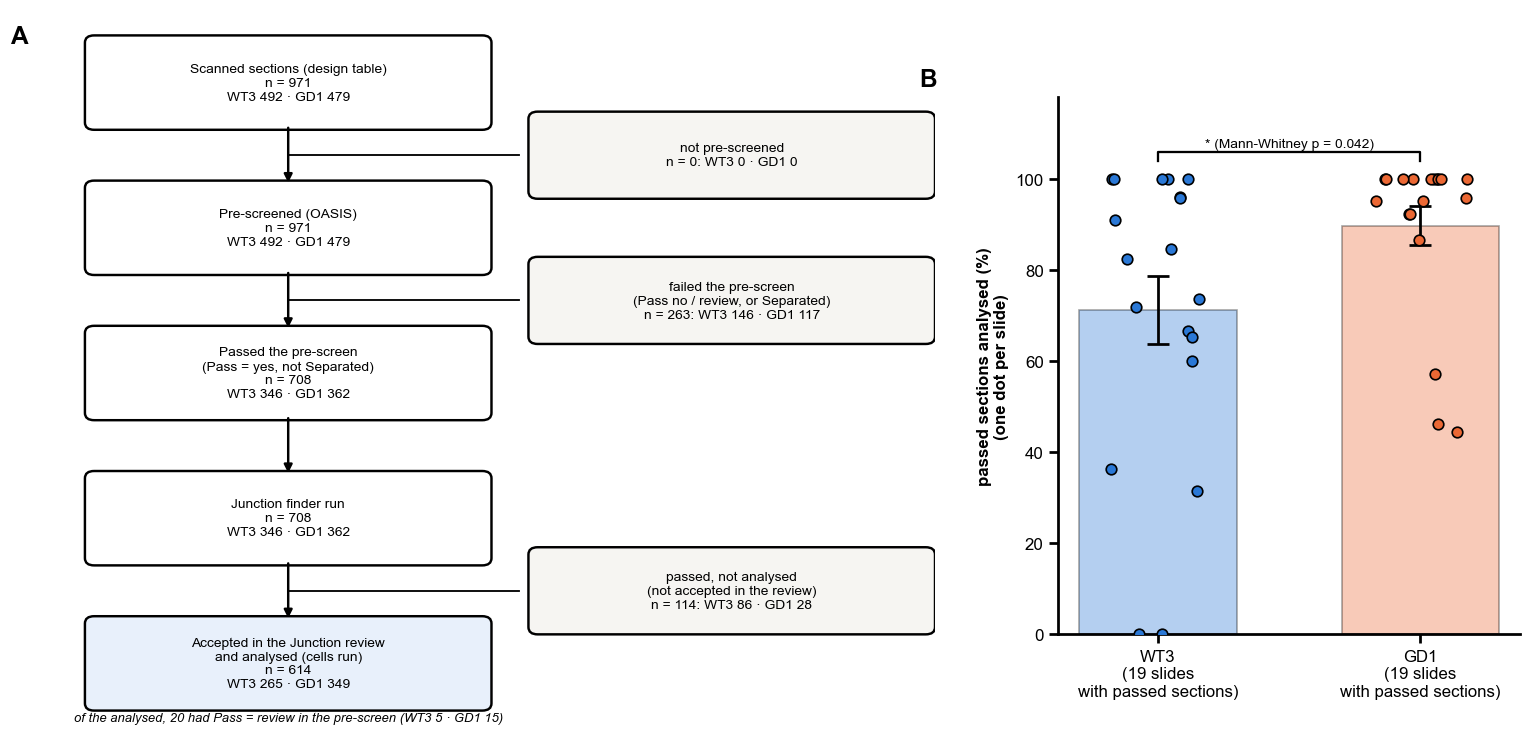

In [3]:
def flow_numbers(mask):
    part = flow[mask]
    return {g: int((part["Genotype"] == g).sum()) for g in GENOTYPES}


def box(ax, x, y, text, w=0.42, h=0.11, face="white"):
    ax.add_patch(mpl.patches.FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.01",
                                            facecolor=face, edgecolor="black", linewidth=1.6))
    ax.text(x, y, text, ha="center", va="center", fontsize=9)


def fmt(n):
    return f"WT3 {n['WT3']} · GD1 {n['GD1']}"


fig = plt.figure(figsize=(14, 6.6))
ax = fig.add_axes([0.0, 0.0, 0.6, 1.0])
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
masks = {"scanned": flow["scanned"], "pre-screened": flow["pre-screened"], "passed": flow["passed"],
         "finder run": flow["finder run"], "analysed": flow["analysed"]}
labels = {"scanned": "Scanned sections (design table)", "pre-screened": "Pre-screened (OASIS)",
          "passed": "Passed the pre-screen\n(Pass = yes, not Separated)", "finder run": "Junction finder run",
          "analysed": "Accepted in the Junction review\nand analysed (cells run)"}
ys = np.linspace(0.9, 0.1, len(STEPS))
for k, (step, y) in enumerate(zip(STEPS, ys)):
    n = flow_numbers(masks[step])
    box(ax, 0.3, y, f"{labels[step]}\nn = {sum(n.values())}\n{fmt(n)}",
        face="#e8f0fb" if step == "analysed" else "white")
    if k:
        ax.annotate("", (0.3, y + 0.058), (0.3, ys[k - 1] - 0.058),
                    arrowprops=dict(arrowstyle="-|>", color="black", lw=1.6))
outs = {
    "pre-screened": ("not pre-screened", masks["scanned"] & ~masks["pre-screened"]),
    "passed": ("failed the pre-screen\n(Pass no / review, or Separated)", masks["pre-screened"] & ~masks["passed"]),
    "analysed": ("passed, not analysed\n(not accepted in the review)", masks["passed"] & ~masks["analysed"]),
}
for step, (text, mask) in outs.items():
    y = (ys[STEPS.index(step)] + ys[STEPS.index(step) - 1]) / 2
    n = flow_numbers(mask)
    ax.plot([0.3, 0.55], [y, y], color="black", lw=1.2)
    box(ax, 0.78, y, f"{text}\nn = {sum(n.values())}: {fmt(n)}", w=0.42, h=0.1, face="#f6f5f2")
n = flow_numbers(masks["analysed"] & ~masks["passed"])
ax.text(0.3, 0.02, f"of the analysed, {sum(n.values())} had Pass = review in the pre-screen ({fmt(n)})",
        ha="center", fontsize=8.5, style="italic")
ax.text(0.0, 0.98, "A", fontsize=16, fontweight="bold", va="top")

# B: per slide, the share of its passed sections that was analysed.
ax = fig.add_axes([0.68, 0.14, 0.3, 0.74])
slide_flow = (flow[flow["Genotype"].isin(GENOTYPES) & flow["passed"]].groupby("slide")
              .agg(Genotype=("Genotype", "first"), Experiment=("Experiment", "first"),
                   passed=("passed", "sum"), analysed=("analysed", "sum")))
slide_flow["kept (%)"] = 100 * slide_flow["analysed"] / slide_flow["passed"]
p_kept = stats.mannwhitneyu(*[slide_flow.loc[slide_flow["Genotype"] == g, "kept (%)"] for g in GENOTYPES]).pvalue
rng = np.random.default_rng(SEED)
for k, g in enumerate(GENOTYPES):
    y = slide_flow.loc[slide_flow["Genotype"] == g, "kept (%)"]
    ax.bar(k, y.mean(), width=0.6, color=GENOTYPE_COLOURS[g], alpha=0.35, **EDGE)
    ax.errorbar(k, y.mean(), yerr=y.std(ddof=1) / np.sqrt(len(y)), color="black", capsize=7, lw=1.8, capthick=1.8)
    ax.scatter(k + rng.uniform(-0.18, 0.18, len(y)), y, s=48, color=GENOTYPE_COLOURS[g], zorder=3, **EDGE)
ax.plot([0, 0, 1, 1], [104, 106, 106, 104], color="black", lw=1.5)
ax.text(0.5, 107, f"{stars(p_kept)} (Mann-Whitney p = {p_kept:.2g})", ha="center", fontsize=9)
ax.set_xticks([0, 1], [f"{g}\n({int((slide_flow['Genotype'] == g).sum())} slides\nwith passed sections)" for g in GENOTYPES])
ax.set_ylim(0, 118)
ax.set_ylabel("passed sections analysed (%)\n(one dot per slide)")
ax.text(-0.3, 1.02, "B", transform=ax.transAxes, fontsize=16, fontweight="bold")
save(fig, "data_flow")
plt.show()

### Selection-bias checks

In [4]:
def fisher_row(label, start, end):
    """Share of the *start* sections that reach *end*, per genotype, and Fisher's p (sections)."""
    t = pd.crosstab(flow.loc[start, "Genotype"], end[start]).reindex(index=GENOTYPES, columns=[False, True],
                                                                     fill_value=0)
    return {"step": label, **{f"{g} (%)": 100 * t.at[g, True] / t.loc[g].sum() for g in GENOTYPES},
            **{f"{g} n": f"{t.at[g, True]}/{t.loc[g].sum()}" for g in GENOTYPES},
            "Fisher p (sections)": stats.fisher_exact(t.to_numpy())[1]}


rows = []
two = flow["Genotype"].isin(GENOTYPES)
for label, start, end in (("pre-screened → passed", two & flow["pre-screened"], flow["passed"]),
                          ("passed → analysed", two & flow["passed"], flow["analysed"]),
                          ("pre-screened → analysed", two & flow["pre-screened"], flow["analysed"])):
    rows.append(fisher_row(label, start, end))
attrition = pd.DataFrame(rows).set_index("step")
# the same on slides: each slide's share, Mann-Whitney between genotypes
flow["passed_analysed"] = flow["passed"] & flow["analysed"]
slide_rates = flow[two & flow["pre-screened"]].groupby("slide").agg(
    Genotype=("Genotype", "first"), screened=("pre-screened", "sum"), passed=("passed", "sum"), analysed=("analysed", "sum"),
    passed_analysed=("passed_analysed", "sum"))
for label, num, den in (("pre-screened → passed", "passed", "screened"), ("passed → analysed", "passed_analysed", "passed"),
                        ("pre-screened → analysed", "analysed", "screened")):
    r = slide_rates[num] / slide_rates[den].where(slide_rates[den] > 0)
    a, b = (r[slide_rates["Genotype"] == g].dropna() for g in GENOTYPES)
    attrition.at[label, "slide median WT3 / GD1 (%)"] = f"{100 * a.median():.0f} / {100 * b.median():.0f}"
    attrition.at[label, "Mann-Whitney p (slides)"] = stats.mannwhitneyu(a, b).pvalue
print("1. Attrition by genotype (share of the step's sections that reach the next):")
display(attrition.round(4))

print("2. Passed → analysed, by genotype and experiment:")
display(flow[two & flow["passed"]].groupby(["Genotype", "Experiment"])["analysed"].agg(["sum", "size", "mean"])
        .rename(columns={"sum": "analysed", "size": "passed", "mean": "share"}).round(2))

# 3. Do the lost passed sections differ from the kept ones? Pre-screen labels and the finder's verdict.
passed_two = flow[two & flow["passed"]].join(ps[["Quality", "Ripped", "Folded"]]).join(
    finder[["status", "Junction length (um)", "Seam price"]].rename(columns={"status": "finder status"}))
passed_two["Quality good"] = passed_two["Quality"].eq("Good")
passed_two["Ripped (yes)"] = passed_two["Ripped"].eq("yes")
passed_two["Folded (yes)"] = passed_two["Folded"].eq("yes")
passed_two["finder ok"] = passed_two["finder status"].eq("ok")
passed_two["finder fail"] = passed_two["finder status"].eq("fail")
rows = []
for g in GENOTYPES:
    part = passed_two[passed_two["Genotype"] == g]
    for column in ("Quality good", "Ripped (yes)", "Folded (yes)", "finder ok", "finder fail"):
        t = pd.crosstab(part["analysed"], part[column]).reindex(index=[True, False], columns=[False, True], fill_value=0)
        rows.append({"genotype": g, "attribute": column,
                     "kept (%)": 100 * t.at[True, True] / t.loc[True].sum(),
                     "lost (%)": 100 * t.at[False, True] / max(t.loc[False].sum(), 1),
                     "p": stats.fisher_exact(t.to_numpy())[1]})
    for column in ("Junction length (um)", "Seam price"):
        a, b = part.loc[part["analysed"], column].dropna(), part.loc[~part["analysed"], column].dropna()
        rows.append({"genotype": g, "attribute": f"{column} (median)", "kept (%)": a.median(), "lost (%)": b.median(),
                     "p": stats.mannwhitneyu(a, b).pvalue if len(a) and len(b) else np.nan})
lost_vs_kept = pd.DataFrame(rows).set_index(["genotype", "attribute"])
print("3. Passed sections: kept (analysed) against lost — pre-screen labels and the finder's verdict:")
display(lost_vs_kept.round(3))

# 4. Slides per genotype; slides lost entirely.
per_slide = sections.groupby("slide").agg(sections=("Genotype", "size"), Genotype=("Genotype", "first"))
slides_scanned = flow[two].groupby("Genotype")["slide"].nunique()
for g in GENOTYPES:
    part = per_slide[per_slide["Genotype"] == g]
    share = part["sections"] / part["sections"].sum()
    print(f"4. {g}: {len(part)} of {slides_scanned[g]} scanned slides analysed, {part['sections'].sum()} sections, "
          f"{part['sections'].min()}–{part['sections'].max()} per slide (median {part['sections'].median():.0f}), "
          f"effective number of slides {1 / (share ** 2).sum():.1f}")

# 5. Covariates of the analysed sections by genotype: slide means (Mann-Whitney), yes/no as % (Fisher on sections).
CONTINUOUS = {"junction length (µm)": "junction line (µm)", "cells in section": "cells in section",
              f"{CHANNEL} background": f"{CHANNEL} tissue background (a.u.)"}
BINARY = ["QC ok", "hand-drawn region", "Quality good", "Ripped (yes)", "Folded (yes)"]
slide_means = sections.groupby("slide").agg({**{c: "mean" for c in CONTINUOUS}, **{c: "mean" for c in BINARY},
                                             "Genotype": "first"})
rows = {}
for column, label in list(CONTINUOUS.items()) + [(c, f"{c} (% of sections)") for c in BINARY]:
    scale = 100 if column in BINARY else 1
    a, b = (slide_means.loc[slide_means["Genotype"] == g, column].astype(float) for g in GENOTYPES)
    row = {f"{g}": scale * (sections.loc[sections["Genotype"] == g, column].astype(float).median() if scale == 1
                            else sections.loc[sections["Genotype"] == g, column].mean()) for g in GENOTYPES}
    row["p (slides, Mann-Whitney)"] = stats.mannwhitneyu(a, b).pvalue
    if column in BINARY:
        t = pd.crosstab(sections["Genotype"], sections[column]).reindex(index=GENOTYPES, columns=[False, True], fill_value=0)
        row["p (sections, Fisher)"] = stats.fisher_exact(t.to_numpy())[1]
    rows[label] = row
covariates = pd.DataFrame(rows).T
covariates["differs (slides)"] = covariates["p (slides, Mann-Whitney)"].map(stars)
print("5. Covariates of the analysed sections (continuous: section medians; yes/no: % of sections):")
display(covariates.round(3))

1. Attrition by genotype (share of the step's sections that reach the next):


,WT3 (%),GD1 (%),WT3 n,GD1 n,Fisher p (sections),slide median WT3 / GD1 (%),Mann-Whitney p (slides)
step,,,,,,,
pre-screened → passed,70.3252,75.5741,346/492,362/479,0.0711,73 / 78,0.5695
passed → analysed,75.1445,92.2652,260/346,334/362,0.0000,82 / 100,0.0419
pre-screened → analysed,53.8618,72.8601,265/492,349/479,0.0000,63 / 78,0.0656


2. Passed → analysed, by genotype and experiment:


analysed  passed  share
Genotype Experiment                         
GD1      10               121     122   0.99
         8                104     122   0.85
         9                109     118   0.92
WT3      10                99     123   0.80
         8                 78      89   0.88
         9                 83     134   0.62

3. Passed sections: kept (analysed) against lost — pre-screen labels and the finder's verdict:


kept (%)  lost (%)      p
genotype attribute                                               
WT3      Quality good                     54.615    31.395  0.000
         Ripped (yes)                     28.077    19.767  0.156
         Folded (yes)                     31.538    13.953  0.001
         finder ok                        48.846     9.302  0.000
         finder fail                       0.000     1.163  0.249
         Junction length (um) (median)   967.935   853.642  0.004
         Seam price (median)               0.244     0.489  0.000
GD1      Quality good                     56.886    10.714  0.000
         Ripped (yes)                     31.437    21.429  0.393
         Folded (yes)                     22.455    25.000  0.814
         finder ok                        19.461    10.714  0.321
         finder fail                       0.599     7.143  0.031
         Junction length (um) (median)  1105.413   748.573  0.000
         Seam price (median)               0.244     0.425  0.000

4. WT3: 17 of 20 scanned slides analysed, 265 sections, 4–24 per slide (median 16), effective number of slides 14.9
4. GD1: 19 of 20 scanned slides analysed, 349 sections, 4–29 per slide (median 20), effective number of slides 17.2
5. Covariates of the analysed sections (continuous: section medians; yes/no: % of sections):


,WT3,GD1,"p (slides, Mann-Whitney)","p (sections, Fisher)",differs (slides)
junction line (µm),992.457,1132.409,0.410,NaN,ns
cells in section,40083.000,37743.000,0.113,NaN,ns
AF488 tissue background (a.u.),211.000,207.000,0.342,NaN,ns
QC ok (% of sections),42.642,16.332,0.040,0.000,*
hand-drawn region (% of sections),34.340,23.496,0.048,0.004,*
Quality good (% of sections),53.585,55.014,0.612,0.744,ns
Ripped (yes) (% of sections),29.057,33.524,0.579,0.255,ns
Folded (yes) (% of sections),32.075,22.636,0.182,0.010,ns


In [5]:
_a = attrition
_lost = flow_numbers(flow["passed"] & ~flow["analysed"])
_differ = [i for i in covariates.index if covariates.at[i, "p (slides, Mann-Whitney)"] < 0.05]
verdict("Analysed set: no genotype-biased loss before the analysis",
        "PASS with caveat",
        f"pre-screen pass rate WT3 {_a.at['pre-screened → passed', 'WT3 (%)']:.0f} % vs GD1 "
        f"{_a.at['pre-screened → passed', 'GD1 (%)']:.0f} % (p {_a.at['pre-screened → passed', 'Fisher p (sections)']:.2g}); "
        f"passed → analysed WT3 {_a.at['passed → analysed', 'WT3 (%)']:.0f} % vs GD1 {_a.at['passed → analysed', 'GD1 (%)']:.0f} % "
        f"(Fisher p {_a.at['passed → analysed', 'Fisher p (sections)']:.1g}; slides p "
        f"{_a.at['passed → analysed', 'Mann-Whitney p (slides)']:.2g}); covariates differing by genotype (slides): "
        + (", ".join(_differ) if _differ else "none"),
        "the CONSORT flow (figure data_flow) with the WT3-biased loss at the review step; WT2 not part of the study (left out by design); "
        "the sensitivity analyses of section 4 (v) for QC status and section covariates")

[PASS with caveat] Analysed set: no genotype-biased loss before the analysis
    pre-screen pass rate WT3 70 % vs GD1 76 % (p 0.071); passed → analysed WT3 75 % vs GD1 92 % (Fisher p 4e-10; slides p 0.042); covariates differing by genotype (slides): QC ok (% of sections), hand-drawn region (% of sections)


**Verdict — §1: PASS with caveat.** The analysed set is the study's WT3 and GD1 sections, but the loss before the analysis was not even between the genotypes, and that has to be reported.

- **The flow** (figure `data_flow`): 971 WT3 and GD1 sections scanned → 971 pre-screened → 708 passed → 708 through the junction finder → **614 analysed** (WT3 265, GD1 349; 36 slides, 17 WT3 and 19 GD1).
- **WT2 is not part of this study.** The file list also holds 483 WT2 sections; they are left out by design, not lost along the way, and the paper compares WT3 with GD1.
- **The pre-screen treats the genotypes alike.** It passed 70 % of WT3 and 76 % of GD1 sections (Fisher p 0.07; slides p 0.57).
- **The Junction review does not.** It kept **75 % of passed WT3 sections against 92 % of GD1** (86 against 28 lost; Fisher p 4 × 10⁻¹⁰). On slides the medians are 82 % and 100 % (Mann-Whitney p 0.042). The worst is WT3 experiment 9: 83 of 134 kept (62 %). 3 WT3 slides and 1 GD1 slide lost every section.
- **The lost sections were the harder ones, in both genotypes.** They had worse pre-screen Quality (good: WT3 31 % lost against 55 % kept; GD1 11 % against 57 %) and a higher seam price (0.43–0.49 against 0.24, so less often a dark line at the junction). Their junctions were shorter, and in WT3 fewer were finder "ok" (9 % against 49 %). The review dropped poor, ambiguous junctions, and it found more of them among the WT3 sections.
- **20 analysed sections had Pass = review** in the pre-screen (WT3 5, GD1 15). They entered the run without a clear pass.
- **Covariates of the analysed set.** Junction length, cells per section, AF488 background, Quality, Ripped and Folded do not differ by genotype on slides (all p > 0.1). Two things do: the review's QC status ("ok" in 43 % of WT3 against 16 % of GD1 sections, slides p 0.040) and how often the region was drawn by hand (34 % against 23 %, p 0.048).
- **What to report.** The CONSORT flow with the per-genotype numbers at each step. The genotype-biased loss at the review, and that it removed low-quality, no-seam junctions. The sensitivity analyses of §4 (v): QC status, hand-drawn region and section size as covariates, and inverse-probability weighting for the selection. All of them leave the primary result in place (§4).

## 2. Junction detection

The junction finder (`microscopy_viewer/junction.py`) draws the line where the two organoids meet; the counting band is built
along it. Everything downstream depends on where that line is, so it is judged against lines drawn by hand.

**How the junction is set in this study.** The finder only proposes the line. **Every section's line was then screened by eye** in the Junction review panel, and **redrawn by hand when it was wrong**. So the line used for counting is either a finder line a person accepted, or a person's own line. The claims below therefore test two things: the finder on its own (2a–2c: how much work it saves, and how much it would err without the screening — not something the paper relies on), and **the junctions actually used** (2e: does the screening catch the bad lines, and how accurate are the final lines).

**Pre-specified primary metric** (fixed in `junction_tuning.py` before any of this): the **capped mean error**, the mean over
sections of the mean symmetric distance (µm) between the automatic and the hand-drawn line over the tissue, each section capped
at 300 µm; a section where no junction is found scores 300. Secondary: median error, share of sections within 50 / 100 µm,
Dice of the band.

**Data.** 138 sections with a hand-drawn junction (`junction_eval/annotated_all.csv`), split before any tuning into 93 tuning and
45 held-out sections, stratified by Ripped / Folded / Quality; the split never moves (`junction_tuning.split`,
`junction_seeding._split`). One section is excluded (`junction_tuning.EXCLUDE`: organoids separated, nothing to find). A second
annotator (Quillan, stored as `manual annotated junction region quillan`) redrew 27 of them. Annotator 1 is the main ground
truth (`manual annotated junction region`).

**How the 138 were chosen matters.** The first 30 come from a pick list drawn from the pre-screen, before anyone had seen the
finder's line on them. The other 108 are every section that was later drawn by hand — and in the analysed run every one of
them is a section whose automatic line the reviewer **rejected and redrew** (shown below). So 37 of the 45 held-out sections
are known finder failures by selection, and the 138 overstate the failure rate on a random section. The first 30 are the
nearest thing to an unselected sample.

**The finder is re-run here** with today's defaults on every cached overview (`junction_eval/overviews/*.npz`), scored exactly
as `junction_tuning.run_case` does, and checked against the stored scores of the last evaluation (`labels.jsonl`, variant
"default" = today's defaults) so that the numbers below are the current code's, not a copy. Cached to `OUT` after the first run
(about 3 min).

CIs: 95 % percentile bootstrap (2000 draws) over **sections**, and over **slides** (32 slides; sections of one slide are not
independent). Proportions: Wilson intervals.

In [6]:
# Junction: family-specific setup. Re-runs the finder on the 138 annotated sections and reads the second annotator's lines.
import threading
from concurrent.futures import ThreadPoolExecutor

from IPython.display import display
from scipy import ndimage

sys.path.insert(0, str(ROOT / "notebooks" / "validation"))
import junction_tuning as jt  # noqa: E402
from microscopy_viewer import ims_store  # noqa: E402
from microscopy_viewer import junction as jn  # noqa: E402

J_CAP = jt.CAP_UM                                     # 300 µm: the cap of the primary metric
J_FAIL_UM = 100.0                                     # "failed line": further than this from the hand-drawn one
J_CACHE = OUT / "publication_junction_rerun.pkl"      # the re-run below, kept so the notebook re-executes in seconds
J_SECOND_CACHE = OUT / "publication_junction_second.pkl"
AUTO_COLOUR = PIPELINE_COLOUR

samples_j = pd.read_csv(EVAL / "annotated_all.csv")
samples_j = samples_j.merge(design[["name", "Genotype", "slide"]], on="name", how="left")
assert samples_j["slide"].notna().all(), "every annotated section must be in the design table"
print(f"{len(samples_j)} annotated sections on {samples_j['slide'].nunique()} slides; "
      f"{(samples_j['set'] == 'tuning').sum()} tuning, {(samples_j['set'] == 'held out').sum()} held out")

_lock = threading.Lock()


def _region(result, overview, base):
    """Where lines are compared: the tissue, grown by the band's margin past its edge (as run_case)."""
    filled = result.filled if result.filled is not None and result.filled.any() else jn.tissue_of(overview)
    return ndimage.binary_dilation(filled, iterations=max(1, int(np.ceil(base["margin_um"] / overview.um))))


def rerun_one(name):
    """Today's defaults on one cached section: the line, its scores and what the finder says about itself."""
    with _lock:                                    # jt.load_case keeps a small shared cache: not thread-safe
        overview, manual_band, manual_line, base = jt.load_case(name)
    result = jn.find_junction(overview, jn.JunctionOptions(save=False, **base))
    m = result.metrics
    out = {"name": name, "status": result.status, "flags": "; ".join(result.flags),
           "seam_price": m.get("Seam price", np.nan), "second_search": bool(m.get("No-seam fallback", 0.0)),
           "found": result.line_um is not None and result.band is not None,
           "line": None if result.line_um is None else np.asarray(result.line_um)}
    if out["found"]:
        region = _region(result, overview, base)
        mean_dist, hd95, within100 = jt.line_distance(manual_line, result.line_um, region, overview.um)
        out.update(mean_dist=mean_dist, hd95=hd95, within100=within100,
                   dice=jt.dice(result.band & region, manual_band & region))
    return out


if J_CACHE.exists():
    rerun = pd.read_pickle(J_CACHE)
else:
    with ThreadPoolExecutor(8) as pool:
        rerun = pd.DataFrame(list(pool.map(rerun_one, samples_j["name"])))
    rerun.to_pickle(J_CACHE)
rerun["error"] = [jt.capped(r) for r in rerun.to_dict("records")]
J = samples_j.merge(rerun.drop(columns="line"), on="name")

# Reproducibility: the same sections, scored by the last evaluation run (labels.jsonl, "default" = today's defaults).
stored = pd.read_json(EVAL / "labels.jsonl", lines=True)
stored = stored[stored["variant"] == "default"].set_index("name")["capped"]
drift = (J.set_index("name")["error"] - stored.reindex(J["name"]).to_numpy()).abs()
print(f"re-run vs stored evaluation (27 Oct): {int((drift > 1).sum())} of {len(drift)} sections differ by > 1 µm "
      f"(mean |difference| {drift.mean():.2f} µm): " + ", ".join(
          f"{n.split('_')[-2]}_{n.split('_')[-1]} {stored[n]:.0f} → {e:.0f} µm"
          for n, e in J.set_index("name")["error"][drift.to_numpy() > 1].items()))

# The review decision of the analysed run for each annotated section: accepted the finder's line, or redrew it.
review_j = pd.read_excel(RUN / "counts.xlsx", sheet_name="Counts").drop_duplicates("Sample").set_index("Sample")
J["review"] = J["name"].map(review_j["Review decision"]).fillna("not in the run")
print("how the annotated sections were chosen: review decision in the run, by batch (n, finder's median / capped mean error)")
display(J.groupby(["batch", "set", "review"])["error"].agg(["count", "median", "mean"]).round(0))


def second_one(row):
    """Annotator 2's line on one section, against annotator 1's and against the finder's."""
    labels, attrs = ims_store.load_labels(row.path, jt.SECOND_KEY)
    overview, first_band, first_line, base = jt.load_case(row.name)
    shape = first_band.shape
    second_band = (np.asarray(labels).reshape(np.shape(labels)[-2:])[:: overview.step, :: overview.step] > 0)[: shape[0], : shape[1]]
    second_line = np.asarray(attrs["line_yx_um"], dtype=float).reshape(-1, 2)
    result = jn.find_junction(overview, jn.JunctionOptions(save=False, **base))
    region = _region(result, overview, base)
    pairs = {"annotator 2 vs annotator 1": (second_line, second_band, first_line, first_band)}
    if result.line_um is not None and result.band is not None:
        pairs["finder vs annotator 1"] = (result.line_um, result.band, first_line, first_band)
        pairs["finder vs annotator 2"] = (result.line_um, result.band, second_line, second_band)
    junction_rows = []
    for pair, (line_a, band_a, line_b, band_b) in pairs.items():
        mean_dist, hd95, within100 = jt.line_distance(line_b, line_a, region, overview.um)
        junction_rows.append({"name": row.name, "pair": pair, "mean_dist": mean_dist, "hd95": hd95,
                     "dice": jt.dice(band_a & region, band_b & region)})
    if "finder vs annotator 1" not in pairs:            # no line found: the primary metric's 300 µm
        junction_rows += [{"name": row.name, "pair": p, "mean_dist": np.nan} for p in ("finder vs annotator 1", "finder vs annotator 2")]
    return junction_rows


if J_SECOND_CACHE.exists():
    second_j = pd.read_pickle(J_SECOND_CACHE)
else:
    with_second = [r for r in samples_j.itertuples() if jt.SECOND_KEY in ims_store.list_labels(r.path)]
    second_j = pd.DataFrame([x for r in with_second for x in second_one(r)])
    second_j.to_pickle(J_SECOND_CACHE)
second_j["error"] = np.minimum(second_j["mean_dist"].fillna(J_CAP), J_CAP)
second_j = second_j.merge(samples_j[["name", "set", "slide", "Shape"]], on="name")
print(f"annotator 2 redrew {second_j['name'].nunique()} sections "
      f"({second_j.drop_duplicates('name')['set'].value_counts().to_dict()})")


def wilson(k, n, z=1.96):
    """A proportion and its Wilson 95 % interval."""
    if n == 0:
        return np.nan, np.nan, np.nan
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return p, centre - half, centre + half


def fmt(est, lo, hi, digits=0, unit=""):
    return f"{est:.{digits}f}{unit} ({lo:.{digits}f}–{hi:.{digits}f})"

138 annotated sections on 32 slides; 93 tuning, 45 held out
re-run vs stored evaluation (27 Oct): 2 of 138 sections differ by > 1 µm (mean |difference| 0.81 µm): 021-020_s29 264 → 261 µm, 021-020_s6 193 → 300 µm


how the annotated sections were chosen: review decision in the run, by batch (n, finder's median / capped mean error)


count  median   mean
batch    set      review                              
first 31 held out accept              2    30.0   30.0
                  not in the run      2    62.0   62.0
                  redrawn             4   213.0  187.0
         tuning   accept             12    16.0   47.0
                  not in the run      5    40.0   55.0
                  redrawn             5    26.0   44.0
new      held out redrawn            37   156.0  168.0
         tuning   redrawn            71   138.0  157.0

annotator 2 redrew 27 sections ({'tuning': 20, 'held out': 7})


### 2a. The finder alone (before the screening): accuracy on held-out sections

**Claim.** On sections it was never tuned on, the automatic line is close to the hand-drawn one, and its error there is no
worse than on the tuning sections (no overfitting).

**Pass criteria, set before looking.** PASS if the held-out median error is ≤ 50 µm (about two nuclei; the human-vs-human
median, §2b, is the reference) *and* the held-out capped mean's CI overlaps the tuning one. PASS with caveat if the median
passes but the capped mean is dominated by a failure tail. FAIL if the median is > 50 µm or held out is clearly worse.

In [7]:
def acc_table(frame):
    """Every accuracy figure of one set of sections, with section- and slide-bootstrap CIs."""
    cm = lambda f: f["error"].mean()
    med = lambda f: f["error"].median()
    w50 = lambda f: (f["error"] <= 50).mean() * 100
    w100 = lambda f: (f["error"] <= 100).mean() * 100
    dice0 = lambda f: f["dice"].fillna(0).mean()
    out = {"n sections": len(frame), "slides": frame["slide"].nunique()}
    for label, stat, digits in (("capped mean error (µm)", cm, 0), ("median error (µm)", med, 0),
                                ("within 50 µm (%)", w50, 0), ("within 100 µm (%)", w100, 0),
                                ("Dice (none found = 0)", dice0, 2)):
        out[label] = fmt(*boot_ci(frame, stat), digits)
        out[label + ", slide CI"] = fmt(*boot_ci(frame, stat, groups="slide"), digits)
    out["no junction found"] = int((~frame["found"]).sum())
    out["capped (≥ 300 µm or none)"] = int((frame["error"] >= J_CAP).sum())
    out["Dice, median of found"] = round(frame.loc[frame["found"], "dice"].median(), 3)
    return out


acc = pd.DataFrame({"tuning": acc_table(J[J["set"] == "tuning"]), "held out": acc_table(J[J["set"] == "held out"]),
                    "all 138": acc_table(J),
                    "held out, first 30": acc_table(J[(J["set"] == "held out") & (J["batch"] == "first 31")]),
                    "held out, new 108": acc_table(J[(J["set"] == "held out") & (J["batch"] == "new")]),
                    "first 30 (unselected)": acc_table(J[J["batch"] == "first 31"]),
                    "first 30, accepted at review": acc_table(J[(J["batch"] == "first 31") & (J["review"] == "accept")])})
display(acc)

held_j, tune_j = J[J["set"] == "held out"], J[J["set"] == "tuning"]
# Tuning vs held out: the difference of capped means, section-bootstrapped within each set; and a rank test.
rng = np.random.default_rng(SEED)
gap = [held_j["error"].sample(len(held_j), replace=True, random_state=rng.integers(1 << 31)).mean()
       - tune_j["error"].sample(len(tune_j), replace=True, random_state=rng.integers(1 << 31)).mean() for _ in range(N_BOOT)]
gap_ci = np.percentile(gap, [2.5, 97.5])
p_gap = stats.mannwhitneyu(held_j["error"], tune_j["error"]).pvalue
print(f"held out − tuning, capped mean: {held_j['error'].mean() - tune_j['error'].mean():+.0f} µm "
      f"(95 % CI {gap_ci[0]:+.0f} to {gap_ci[1]:+.0f}); Mann–Whitney p = {p_gap:.2f}")
print("held out by pre-screen class (capped mean, n):")
display(held_j.groupby("Shape")["error"].agg(["count", "mean", "median"]).round(0))

,tuning,held out,all 138,"held out, first 30","held out, new 108",first 30 (unselected),"first 30, accepted at review"
n sections,93,45,138,8,37,30,14
slides,28,23,32,8,18,19,11
capped mean error (µm),131 (108–154),158 (128–188),140 (121–158),116 (44–198),168 (135–203),66 (39–99),44 (17–89)
"capped mean error (µm), slide CI",131 (103–157),158 (117–197),140 (112–168),116 (46–193),168 (123–205),66 (42–95),44 (18–95)
median error (µm),97 (55–132),124 (80–214),110 (80–135),67 (20–213),156 (80–261),29 (19–41),17 (10–40)
"median error (µm), slide CI",97 (44–131),124 (72–243),110 (67–170),67 (25–213),156 (78–261),29 (22–41),17 (10–40)
within 50 µm (%),39 (29–48),22 (11–36),33 (25–41),50 (12–88),16 (5–30),70 (53–87),86 (64–100)
"within 50 µm (%), slide CI",39 (27–53),22 (10–37),33 (22–47),50 (12–88),16 (6–29),70 (52–84),86 (64–100)
within 100 µm (%),52 (41–62),40 (27–53),48 (40–57),62 (25–88),35 (19–51),83 (70–97),93 (79–100)
"within 100 µm (%), slide CI",52 (41–64),40 (24–59),48 (37–60),62 (25–88),35 (19–56),83 (68–94),93 (75–100)


held out − tuning, capped mean: +28 µm (95 % CI -11 to +66); Mann–Whitney p = 0.08
held out by pre-screen class (capped mean, n):


,count,mean,median
Shape,,,
Damaged,6,173.0,156.0
Fused pair,38,158.0,121.0
Separated,1,92.0,92.0


In [8]:
h_cm = boot_ci(held_j, lambda f: f["error"].mean())
h_cm_s = boot_ci(held_j, lambda f: f["error"].mean(), groups="slide")
h_med = boot_ci(held_j, lambda f: f["error"].median())
t_cm = boot_ci(tune_j, lambda f: f["error"].mean())
t_med = boot_ci(tune_j, lambda f: f["error"].median())
h_w50 = wilson(int((held_j["error"] <= 50).sum()), len(held_j))
h_w100 = wilson(int((held_j["error"] <= 100).sum()), len(held_j))
overlap = not (h_cm[1] > t_cm[2] or t_cm[1] > h_cm[2])
median_ok = h_med[0] <= 50
tail = (held_j["error"] > J_FAIL_UM).mean()
res_a = "FAIL" if not median_ok else ("PASS" if overlap and tail < 0.15 else "PASS with caveat")
verdict("2a. Finder alone (before the manual screening): accurate on held-out sections", (res_a + " (finder alone, not relied on)" if res_a == "FAIL" else res_a),
        f"held out (n={len(held_j)}, {held_j['slide'].nunique()} slides): capped mean {fmt(*h_cm)} µm "
        f"[slide CI {h_cm_s[1]:.0f}–{h_cm_s[2]:.0f}], median {fmt(*h_med)} µm, within 50 µm "
        f"{h_w50[0]*100:.0f} % ({h_w50[1]*100:.0f}–{h_w50[2]*100:.0f}), within 100 µm {h_w100[0]*100:.0f} % "
        f"({h_w100[1]*100:.0f}–{h_w100[2]*100:.0f}); tuning (n={len(tune_j)}) capped mean {fmt(*t_cm)} µm, "
        f"median {fmt(*t_med)} µm; held out − tuning {np.mean(held_j['error']) - np.mean(tune_j['error']):+.0f} µm "
        f"(CI {gap_ci[0]:+.0f} to {gap_ci[1]:+.0f}, p={p_gap:.2f}); {tail*100:.0f} % of held-out sections > 100 µm off",
        "Not relied on: every line was screened by eye and redrawn when wrong (2e). Do not claim the finder alone is accurate. Report the held-out numbers with slide CIs, that the held-out set is "
        "enriched for review-rejected sections (37/45), and the unselected first 30 (capped mean "
        f"{J.loc[J['batch'] == 'first 31', 'error'].mean():.0f} µm, median {J.loc[J['batch'] == 'first 31', 'error'].median():.0f}"
        " µm) as the estimate for a random section; the pipeline's junction is the finder plus a human review.")

[FAIL (finder alone, not relied on)] 2a. Finder alone (before the manual screening): accurate on held-out sections
    held out (n=45, 23 slides): capped mean 158 (128–188) µm [slide CI 117–197], median 124 (80–214) µm, within 50 µm 22 % (13–36), within 100 µm 40 % (27–55); tuning (n=93) capped mean 131 (108–154) µm, median 97 (55–132) µm; held out − tuning +28 µm (CI -11 to +66, p=0.08); 60 % of held-out sections > 100 µm off


### 2b. Against the variability between two people

**Claim.** The finder is about as far from a person as two people are from each other.

On the 27 sections both annotators drew: annotator 2 vs annotator 1 (the floor), finder vs annotator 1, finder vs annotator 2,
same metric (mean symmetric line distance, capped at 300 µm, none found = 300). Paired per section: the difference
finder − human (vs annotator 1), section-bootstrap CI, Wilcoxon signed-rank.

**Criteria.** PASS if the finder's median error is within the CI of the human–human median, or the paired difference's CI
includes 0 — and the 27 are representative (finder's median there ≥ ¾ of its median on all 138). PASS with caveat if
it passes but on unrepresentative sections, or if above but within 2× the human median. FAIL beyond that.

In [9]:
pairs_j = second_j.pivot(index="name", columns="pair", values="error")
pairs_j = pairs_j.join(samples_j.set_index("name")[["set", "slide", "Shape"]])
PAIRS = ["annotator 2 vs annotator 1", "finder vs annotator 1", "finder vs annotator 2"]
junction_rows = {}
for p in PAIRS:
    f = pairs_j.rename(columns={p: "error"})
    junction_rows[p] = {"n": int(f["error"].notna().sum()),
               "median (µm)": fmt(*boot_ci(f, lambda g: g["error"].median())),
               "capped mean (µm)": fmt(*boot_ci(f, lambda g: g["error"].mean())),
               "capped mean, slide CI": fmt(*boot_ci(f, lambda g: g["error"].mean(), groups="slide")),
               "> 100 µm": int((f["error"] > 100).sum()),
               "Dice, median": round(second_j.loc[second_j["pair"] == p, "dice"].median(), 3)}
display(pd.DataFrame(junction_rows).T)

pairs_j["finder − human"] = pairs_j["finder vs annotator 1"] - pairs_j["annotator 2 vs annotator 1"]
d_med = boot_ci(pairs_j, lambda g: g["finder − human"].median())
d_mean = boot_ci(pairs_j, lambda g: g["finder − human"].mean())
ratio = boot_ci(pairs_j, lambda g: g["finder vs annotator 1"].median() / g["annotator 2 vs annotator 1"].median())
w_p = stats.wilcoxon(pairs_j["finder vs annotator 1"], pairs_j["annotator 2 vs annotator 1"]).pvalue
closer = int((pairs_j["finder vs annotator 1"] <= pairs_j["annotator 2 vs annotator 1"]).sum())
within2 = int((pairs_j["finder vs annotator 1"] <= 2 * pairs_j["annotator 2 vs annotator 1"]).sum())
print(f"finder − human, per section: median {fmt(*d_med)} µm, mean {fmt(*d_mean)} µm; Wilcoxon p = {w_p:.3g}")
print(f"ratio of medians (finder / human): {fmt(*ratio, 2)}; finder at least as close as annotator 2 on {closer} of "
      f"{len(pairs_j)}, within 2× on {within2}")
# Same comparison without the sections triage sends to drawing (fail or Damaged), as the workflow uses the finder.
routed_2b = pairs_j.index.isin(J.loc[(J["status"] == "fail") | (J["Shape"] == "Damaged"), "name"])
kept_2b = pairs_j[~routed_2b]
k_ratio = boot_ci(kept_2b, lambda g: g["finder vs annotator 1"].median() / g["annotator 2 vs annotator 1"].median())
print(f"kept by triage ({len(kept_2b)}): human median {kept_2b['annotator 2 vs annotator 1'].median():.0f} µm, "
      f"finder vs annotator 1 {kept_2b['finder vs annotator 1'].median():.0f} µm, ratio {fmt(*k_ratio, 2)}")

,n,median (µm),capped mean (µm),"capped mean, slide CI",> 100 µm,"Dice, median"
annotator 2 vs annotator 1,27,17 (11–32),39 (20–63),39 (20–61),2,0.94
finder vs annotator 1,27,26 (17–40),66 (36–100),66 (39–100),5,0.9
finder vs annotator 2,27,30 (15–52),73 (40–112),73 (37–118),5,0.903


finder − human, per section: median 6 (-3–17) µm, mean 27 (-11–70) µm; Wilcoxon p = 0.178
ratio of medians (finder / human): 1.50 (0.86–3.19); finder at least as close as annotator 2 on 11 of 27, within 2× on 17


kept by triage (23): human median 17 µm, finder vs annotator 1 24 µm, ratio 1.41 (0.75–2.31)


In [10]:
hh = pairs_j["annotator 2 vs annotator 1"]
fh = pairs_j["finder vs annotator 1"]
hh_med = boot_ci(pairs_j, lambda g: g["annotator 2 vs annotator 1"].median())
fh_med = boot_ci(pairs_j, lambda g: g["finder vs annotator 1"].median())
# The 27 are all from the first 30 (the easy, unselected batch): a PASS there says nothing about the hard sections.
representative = pairs_j["finder vs annotator 1"].median() >= 0.75 * J["error"].median()
if (fh_med[0] <= hh_med[2] or d_med[1] <= 0) and representative:
    res_b = "PASS"
elif fh_med[0] <= hh_med[2] or d_med[1] <= 0:
    res_b = "PASS with caveat"
elif ratio[0] <= 2:
    res_b = "PASS with caveat"
else:
    res_b = "FAIL"
verdict("2b. Finder error within inter-annotator variability", res_b,
        f"27 sections drawn by both: human–human median {fmt(*hh_med)} µm (capped mean {hh.mean():.0f}); finder vs "
        f"annotator 1 median {fmt(*fh_med)} µm (capped mean {fh.mean():.0f}); paired difference median {fmt(*d_med)} µm, "
        f"Wilcoxon p={w_p:.2g}; ratio of medians {fmt(*ratio, 2)}; finder ≤ human on {closer}/27, ≤ 2× on {within2}/27; "
        f"triage-kept ({len(kept_2b)}) ratio {k_ratio[0]:.2f}. All 27 are from the unselected first 30 (20 tuning); the finder's "
        f"median there is {pairs_j['finder vs annotator 1'].median():.0f} µm against {J['error'].median():.0f} µm on all 138.",
        "Report the human–human distance as the benchmark beside the finder's, with the ratio and its CI; do not claim "
        "human-level placement of the line.")

[PASS with caveat] 2b. Finder error within inter-annotator variability
    27 sections drawn by both: human–human median 17 (11–32) µm (capped mean 39); finder vs annotator 1 median 26 (17–40) µm (capped mean 66); paired difference median 6 (-3–17) µm, Wilcoxon p=0.18; ratio of medians 1.50 (0.86–3.19); finder ≤ human on 11/27, ≤ 2× on 17/27; triage-kept (23) ratio 1.41. All 27 are from the unselected first 30 (20 tuning); the finder's median there is 26 µm against 110 µm on all 138.


### 2c. Can the finder's own flags spot its failures?

**Claim.** The sections where the finder fails can be recognised before counting, so that they are drawn by hand: the rule in
use is **"draw by hand when the finder's status is fail or the pre-screen Shape is Damaged"** (`AGENTS.md`), set on the first
30 sections (7 of 7 failures caught, no good line sent). Here it is tested on all 138, and on the 108 sections it was not set
on. A *failure* is a line > 100 µm off (or none); a *severe failure* is ≥ 300 µm or none. The seam price (> 0.4: no dark line
at the junction) is tested as a continuous predictor (ROC AUC, section-bootstrap CI).
The **review by eye** (every section's line accepted or redrawn in the Junction review panel before the run) is the triage
actually used; it can be scored only on the first 30, the 108 being review rejects by selection. The reviewer judged the
line stored in the file by the dataset's finder run, which may differ from today's re-run, so this is approximate.

**Criteria.** PASS if, on the sections the rule was not set on, it catches ≥ 80 % of failures (Wilson CI lower bound
≥ 60 %) with specificity ≥ 80 %. PASS with caveat if sensitivity is lower but the failures it misses leave the downstream
counts unbiased (2d). FAIL otherwise.

In [11]:
J["failed"] = J["error"] > J_FAIL_UM
J["severe"] = J["error"] >= J_CAP
J["damaged"] = J["Shape"] == "Damaged"
TRIAGE_RULES = {
    "status is fail": J["status"] == "fail",
    "status is not ok (check or fail)": J["status"] != "ok",
    "Shape is Damaged": J["damaged"],
    "status fail or Shape Damaged (the rule)": (J["status"] == "fail") | J["damaged"],
    "seam price > 0.4 (no dark line)": J["seam_price"] > jn.NO_SEAM_PRICE,
    "the rule, or seam price > 0.4": (J["status"] == "fail") | J["damaged"] | (J["seam_price"] > jn.NO_SEAM_PRICE),
}


def triage_row(mask, truth):
    tp, fn = int((mask & truth).sum()), int((~mask & truth).sum())
    tn, fp = int((~mask & ~truth).sum()), int((mask & ~truth).sum())
    se, sp = wilson(tp, tp + fn), wilson(tn, tn + fp)
    return {"sent": tp + fp, "failures caught": f"{tp}/{tp + fn}",
            "sensitivity": f"{se[0]*100:.0f} % ({se[1]*100:.0f}–{se[2]*100:.0f})",
            "specificity": f"{sp[0]*100:.0f} % ({sp[1]*100:.0f}–{sp[2]*100:.0f})",
            "PPV": f"{tp / max(tp + fp, 1) * 100:.0f} %"}


print(f"failures (> {J_FAIL_UM:.0f} µm or none): {int(J['failed'].sum())} of {len(J)} "
      f"({J['failed'].mean()*100:.0f} %); severe (≥ 300 µm or none): {int(J['severe'].sum())} "
      f"(no junction found {int((~J['found']).sum())}); status: {J['status'].value_counts().to_dict()}")
for label, subset in (("all 138", np.ones(len(J), bool)), ("new 108 (rule not set on these)", J["batch"] == "new"),
                      ("held out 45", J["set"] == "held out")):
    print(f"\n{label}: failures {int(J.loc[subset, 'failed'].sum())}/{int(subset.sum())}")
    display(pd.DataFrame({k: triage_row(m[subset], J.loc[subset, "failed"]) for k, m in TRIAGE_RULES.items()}).T)

# Seam price as a continuous predictor of failure.
def auc(f):
    """ROC AUC of the seam price for telling failed lines from good ones (nan if a resample lacks either)."""
    bad, good = f.loc[f["failed"], "seam_price"], f.loc[~f["failed"], "seam_price"]
    if len(bad) == 0 or len(good) == 0:
        return np.nan
    return stats.mannwhitneyu(bad, good).statistic / (len(bad) * len(good))


auc_ci = boot_ci(J.dropna(subset=["seam_price"]), auc)
rho = stats.spearmanr(J["seam_price"], J["error"], nan_policy="omit")
print(f"\nseam price → failure: ROC AUC {fmt(*auc_ci, 2)}; Spearman with error {rho[0]:.2f} (p = {rho[1]:.1g})")
by_flag = J.assign(flag=J["flags"].str.split("; ")).explode("flag")
by_flag = by_flag[by_flag["flag"].fillna("") != ""]
display(by_flag.groupby("flag").agg(sections=("name", "size"), failed=("failed", "sum"),
                                    median_error=("error", "median")).sort_values("sections", ascending=False).round(0))

failures (> 100 µm or none): 72 of 138 (52 %); severe (≥ 300 µm or none): 29 (no junction found 2); status: {'check': 117, 'ok': 19, 'fail': 2}

all 138: failures 72/138


,sent,failures caught,sensitivity,specificity,PPV
status is fail,2,2/72,3 % (1–10),100 % (94–100),100 %
status is not ok (check or fail),119,67/72,93 % (85–97),21 % (13–33),56 %
Shape is Damaged,13,8/72,11 % (6–20),92 % (83–97),62 %
status fail or Shape Damaged (the rule),15,10/72,14 % (8–24),92 % (83–97),67 %
seam price > 0.4 (no dark line),60,36/72,50 % (39–61),64 % (52–74),60 %
"the rule, or seam price > 0.4",69,43/72,60 % (48–70),61 % (49–71),62 %



new 108 (rule not set on these): failures 67/108


,sent,failures caught,sensitivity,specificity,PPV
status is fail,1,1/67,1 % (0–8),100 % (91–100),100 %
status is not ok (check or fail),98,63/67,94 % (86–98),15 % (7–28),64 %
Shape is Damaged,10,7/67,10 % (5–20),93 % (81–97),70 %
status fail or Shape Damaged (the rule),11,8/67,12 % (6–22),93 % (81–97),73 %
seam price > 0.4 (no dark line),54,34/67,51 % (39–62),51 % (36–66),63 %
"the rule, or seam price > 0.4",61,39/67,58 % (46–69),46 % (32–61),64 %



held out 45: failures 27/45


,sent,failures caught,sensitivity,specificity,PPV
status is fail,1,1/27,4 % (1–18),100 % (82–100),100 %
status is not ok (check or fail),39,25/27,93 % (77–98),22 % (9–45),64 %
Shape is Damaged,6,4/27,15 % (6–32),89 % (67–97),67 %
status fail or Shape Damaged (the rule),7,5/27,19 % (8–37),89 % (67–97),71 %
seam price > 0.4 (no dark line),18,13/27,48 % (31–66),72 % (49–88),72 %
"the rule, or seam price > 0.4",22,16/27,59 % (41–75),67 % (44–84),73 %



seam price → failure: ROC AUC 0.64 (0.55–0.73); Spearman with error 0.30 (p = 0.0004)


,sections,failed,median_error
flag,,,
labelled cells on both sides (junction uncertain),94,55,131.0
no dark line at the junction,60,36,135.0
large holes or torn,9,7,170.0
cut off by the scan edge,6,6,300.0
one organoid much smaller than the other,4,4,209.0
no junction found,2,2,300.0
ragged outline,1,1,132.0


In [12]:
# The analysed run: which sections were counted in a hand-drawn region, which in the finder's.
run_rows = []
for f in sorted((RUN / "cells").glob("*.json")):
    d = json.loads(f.read_text(encoding="utf-8"))
    run_rows.append({"name": d["sample"], "region_by": d.get("region_by"), "band_source": d.get("band_source"),
                     "finder_status": d.get("finder_status") or "none"})
run_j = pd.DataFrame(run_rows).merge(design[["name", "Genotype"]], on="name", how="left")
junction_review = pd.read_excel(RUN / "counts.xlsx", sheet_name="Counts").drop_duplicates("Sample")
run_j = run_j.merge(junction_review[["Sample", "Review decision"]].rename(columns={"Sample": "name"}), on="name", how="left")
run_j["annotated"] = run_j["name"].isin(samples_j["name"])
display(pd.crosstab([run_j["region_by"], run_j["band_source"]], run_j["Review decision"], margins=True))
hand_share = wilson(int((run_j["region_by"] == "by hand").sum()), len(run_j))
redrawn_unannotated = int(((run_j["Review decision"] == "redrawn") & ~run_j["annotated"]).sum())
print(f"run: {len(run_j)} sections; by hand {int((run_j['region_by'] == 'by hand').sum())} "
      f"({hand_share[0]*100:.0f} %, {hand_share[1]*100:.0f}–{hand_share[2]*100:.0f}), of which "
      f"{int(((run_j['region_by'] == 'by hand') & run_j['annotated']).sum())} are the 138 annotated sections and "
      f"{redrawn_unannotated} were redrawn at review; finder's region {int((run_j['region_by'] == 'junction finder').sum())}")
wg = run_j[run_j["Genotype"].isin(GENOTYPES)]
display(pd.crosstab(wg["Genotype"], wg["region_by"], margins=True))
# What share the review sent to drawing: the failure rate seen in practice. The first 30 were drawn by hand before the
# review, so they are left out; the 108 "new" annotated sections are review redraws and stay in.
first30 = set(samples_j.loc[samples_j["batch"] == "first 31", "name"])
un = run_j[~run_j["name"].isin(first30)]
redraw_rate = wilson(int((un["Review decision"] == "redrawn").sum()), len(un))
hand_pct = hand_share[0] * 100
print(f"reviewed sections not drawn beforehand ({len(un)}): redrawn at review {int((un['Review decision'] == 'redrawn').sum())} "
      f"= {redraw_rate[0]*100:.0f} % ({redraw_rate[1]*100:.0f}–{redraw_rate[2]*100:.0f}); finder status of the accepted: "
      f"{un.loc[un['Review decision'] == 'accept', 'finder_status'].value_counts().to_dict()}; by genotype redrawn: "
      + ", ".join(f"{g} {(un.loc[un['Genotype'] == g, 'Review decision'] == 'redrawn').mean()*100:.0f} %" for g in GENOTYPES))
# Is the hand-drawn share balanced between the genotypes? (a region drawn by hand differs from the finder's: 2d)
hand_by_g = pd.crosstab(wg["Genotype"], wg["region_by"])
chi_g = stats.chi2_contingency(hand_by_g)
print(f"hand-drawn share by genotype: " + ", ".join(f"{g} {hand_by_g.loc[g, 'by hand'] / hand_by_g.loc[g].sum()*100:.0f} %"
                                                    for g in GENOTYPES) + f"; χ² p = {chi_g[1]:.2g}")

Review decision                                                    accept  redrawn  All
region_by       band_source                                                            
by hand         stored (manual annotated junction region quillan)       2        0    2
                stored (manual annotated junction region)              14      157  171
junction finder stored (fusion region)                                441        0  441
All                                                                   457      157  614

run: 614 sections; by hand 173 (28 %, 25–32), of which 131 are the 138 annotated sections and 40 were redrawn at review; finder's region 441


region_by,by hand,junction finder,All
Genotype,,,
GD1,82,267,349
WT3,91,174,265
All,173,441,614


reviewed sections not drawn beforehand (591): redrawn at review 148 = 25 % (22–29); finder status of the accepted: {'check': 294, 'ok': 149}; by genotype redrawn: WT3 32 %, GD1 20 %
hand-drawn share by genotype: WT3 34 %, GD1 23 %; χ² p = 0.0041


In [13]:
rule = TRIAGE_RULES["status fail or Shape Damaged (the rule)"]
new = (J["batch"] == "new").to_numpy()
tp, fn = int((rule & J["failed"])[new].sum()), int((~rule & J["failed"])[new].sum())
tn, fp = int((~rule & ~J["failed"])[new].sum()), int((rule & ~J["failed"])[new].sum())
se_new, sp_new = wilson(tp, tp + fn), wilson(tn, tn + fp)
tp_a, fn_a = int((rule & J["failed"]).sum()), int((~rule & J["failed"]).sum())
tn_a, fp_a = int((~rule & ~J["failed"]).sum()), int((rule & ~J["failed"]).sum())
se_all, sp_all = wilson(tp_a, tp_a + fn_a), wilson(tn_a, tn_a + fp_a)
# The review by eye as the triage, on the only sections it can be scored on: the unselected first 30 that were in the run.
rv = J[(J["batch"] == "first 31") & J["review"].isin(["accept", "redrawn"])]
sent = rv["review"] == "redrawn"
rv_tp, rv_fn = int((sent & rv["failed"]).sum()), int((~sent & rv["failed"]).sum())
rv_tn, rv_fp = int((~sent & ~rv["failed"]).sum()), int((sent & ~rv["failed"]).sum())
rv_se, rv_sp = wilson(rv_tp, rv_tp + rv_fn), wilson(rv_tn, rv_tn + rv_fp)
acc_rev = rv.loc[~sent, "error"]
print(f"review as triage on the first 30 in the run (n={len(rv)}): redrawn {int(sent.sum())}; failures caught {rv_tp}/"
      f"{rv_tp + rv_fn} (sensitivity {rv_se[0]*100:.0f} %, {rv_se[1]*100:.0f}–{rv_se[2]*100:.0f}), good lines redrawn anyway "
      f"{rv_fp}/{rv_tn + rv_fp}; accepted lines: median {acc_rev.median():.0f} µm, capped mean {acc_rev.mean():.0f} µm, "
      f"> 100 µm {int((acc_rev > J_FAIL_UM).sum())}/{len(acc_rev)}")
print("accepted lines > 100 µm off:", rv.loc[~sent & rv["failed"], ["name", "error", "status", "Shape"]].round(0).to_dict("records"))
res_c = ("PASS" if se_new[0] >= 0.8 and se_new[1] >= 0.6 and sp_new[0] >= 0.8 else "FAIL")
verdict("2c. Finder's automatic flags recognise its failures (rule 'status fail or Damaged')", (res_c + " (finder alone, not relied on)" if res_c == "FAIL" else res_c),
        f"{int(J['failed'].sum())}/138 lines > 100 µm off ({int(J['severe'].sum())} ≥ 300 µm or none). Rule 'status fail or "
        f"Damaged': on the 108 it was not set on, sensitivity {tp}/{tp + fn} = {se_new[0]*100:.0f} % "
        f"({se_new[1]*100:.0f}–{se_new[2]*100:.0f}), specificity {sp_new[0]*100:.0f} % ({sp_new[1]*100:.0f}–"
        f"{sp_new[2]*100:.0f}); all 138: sensitivity {se_all[0]*100:.0f} % ({se_all[1]*100:.0f}–{se_all[2]*100:.0f}), "
        f"specificity {sp_all[0]*100:.0f} %. Seam price AUC {fmt(*auc_ci, 2)}. In the run, "
        f"{hand_share[0]*100:.0f} % of {len(run_j)} sections were counted in a hand-drawn region "
        f"(the review redrew {redraw_rate[0]*100:.0f} % of the sections not drawn beforehand). Review by eye on the unselected first 30 "
        f"(n={len(rv)}): caught {rv_tp}/{rv_tp + rv_fn} failures, accepted lines median {acc_rev.median():.0f} µm, "
        f"{int((acc_rev > J_FAIL_UM).sum())}/{len(acc_rev)} > 100 µm. Hand-drawn share by genotype: "
        + ", ".join(f"{g} {hand_by_g.loc[g, 'by hand'] / hand_by_g.loc[g].sum()*100:.0f} %" for g in GENOTYPES)
        + f" (χ² p={chi_g[1]:.2g}).",
        "Not relied on: the screening by eye is the triage (2e). Do not present the automatic status as a triage; report that every section's junction was reviewed by eye "
        "(accept / redraw), the redraw rate, and the share counted in hand-drawn regions per genotype.")

review as triage on the first 30 in the run (n=23): redrawn 9; failures caught 4/5 (sensitivity 80 %, 38–96), good lines redrawn anyway 5/18; accepted lines: median 17 µm, capped mean 44 µm, > 100 µm 1/14
accepted lines > 100 µm off: [{'name': '2025_09_26_Asssembloid_020-019_s4', 'error': 300.0, 'status': 'check', 'Shape': 'Fused pair'}]
[FAIL (finder alone, not relied on)] 2c. Finder's automatic flags recognise its failures (rule 'status fail or Damaged')
    72/138 lines > 100 µm off (29 ≥ 300 µm or none). Rule 'status fail or Damaged': on the 108 it was not set on, sensitivity 8/67 = 12 % (6–22), specificity 93 % (81–97); all 138: sensitivity 14 % (8–24), specificity 92 %. Seam price AUC 0.64 (0.55–0.73). In the run, 28 % of 614 sections were counted in a hand-drawn region (the review redrew 25 % of the sections not drawn beforehand). Review by eye on the unselected first 30 (n=23): caught 4/5 failures, accepted lines median 17 µm, 1/14 > 100 µm. Hand-drawn share by genotype: WT3 34

### 2e. The junctions actually used: screened by eye, redrawn when wrong

**Claim 1.** The manual screening catches the finder's failures, so no badly placed line reaches the counts.
**Claim 2.** The final junctions — finder lines accepted at the screening, and lines redrawn by hand — are as close to the
true junction as a person's line is.

**How it is checked.** The screening's decision (accept / redraw) is in the run's review table. It can be scored against a
hand-drawn line only on the unselected first 30 (the later 108 were drawn *because* the screening rejected them). A failure
is a finder line > 100 µm off. Accepted lines: their error against the hand-drawn line. Redrawn lines are a person's line,
whose error is that between two people (2b).

**Criteria.** Claim 1: PASS if the screening catches ≥ 80 % of failures and lets through no line > 100 µm off; PASS with
caveat if it misses some but the lines it accepts have a median error within the human–human range. Claim 2: PASS if the
accepted lines' median error is within 2× the human–human median (2b) and the redrawn lines are hand-drawn; PASS with
caveat when the accepted-line estimate rests on few sections.

In [14]:
# The screening on the unselected first 30 (rv: sections with a review decision; acc_rev: error of accepted lines, µm)
caught_share = rv_tp / max(rv_tp + rv_fn, 1)
accepted_bad = int((acc_rev > J_FAIL_UM).sum())
res_screen = ("PASS" if caught_share >= 0.8 and accepted_bad == 0 else
              "PASS with caveat" if np.median(acc_rev) <= 2 * hh_med[0] else "FAIL")
verdict("2e-1. Manual screening of every line catches the finder's failures", res_screen,
        f"first 30 (n={len(rv)} with a review decision): caught {rv_tp}/{rv_tp + rv_fn} failures; of the "
        f"{len(acc_rev)} accepted lines {accepted_bad} are > {J_FAIL_UM:.0f} µm off; across the run the screening "
        f"redrew {redraw_rate[0]*100:.0f} % of the sections not drawn beforehand",
        "Methods: every junction proposed by the finder was screened by eye and redrawn by hand when wrong; give the "
        "redraw rate and the share of sections counted in a hand-drawn region per genotype.")
res_final = ("PASS" if np.median(acc_rev) <= 2 * hh_med[0] and len(acc_rev) >= 20 else
             "PASS with caveat" if np.median(acc_rev) <= 2 * hh_med[0] else "FAIL")
verdict("2e-2. Final junctions (accepted finder lines + hand-redrawn lines) are as accurate as a person's", res_final,
        f"accepted finder lines: median error {np.median(acc_rev):.0f} µm (n={len(acc_rev)}); redrawn lines are hand-drawn: "
        f"human–human median {hh_med[0]:.0f} µm ({hh_med[1]:.0f}–{hh_med[2]:.0f}); "
        f"{hand_share[0]*100:.0f} % of the {len(run_j)} analysed sections were counted in a hand-drawn region",
        "Report the final junction's accuracy as the accepted lines' error beside the human–human distance; the "
        "accepted-line estimate rests on the first 30 sections only.")

[PASS with caveat] 2e-1. Manual screening of every line catches the finder's failures
    first 30 (n=23 with a review decision): caught 4/5 failures; of the 14 accepted lines 1 are > 100 µm off; across the run the screening redrew 25 % of the sections not drawn beforehand
[PASS with caveat] 2e-2. Final junctions (accepted finder lines + hand-redrawn lines) are as accurate as a person's
    accepted finder lines: median error 17 µm (n=14); redrawn lines are hand-drawn: human–human median 17 µm (11–32); 28 % of the 614 analysed sections were counted in a hand-drawn region


### 2d. Does the line error matter for the counts?

**Claim.** Counting in the finder's band instead of the hand-drawn one does not change % positive per section beyond what
two annotators' bands do.

`junction_downstream.py` counted each of the first 30 annotated sections in annotator 1's band, the finder's band and (27)
annotator 2's band, with Cellpose and the per-band threshold of that time (`downstream.jsonl`, 21 Oct). Bland–Altman of
% positive, finder − annotator 1, per channel; bias and limits of agreement with section-bootstrap 95 % CIs; the same for
annotator 2 − annotator 1 as the benchmark. **Caveat built in:** the automatic band here is the finder of 21 Oct (tissue from
the nuclear stain only, no no-seam fallback), not today's, and the positivity rule is that run's; its line error on these
sections is taken from `scores.csv` (variant "bend 1000", the default then).

**Criteria.** PASS if the bias CI includes 0 and the finder's LoA are no wider than 1.5× the annotators' LoA. PASS with
caveat if unbiased but wider. FAIL if biased.

In [15]:
down_rows = [json.loads(l) for l in (EVAL / "downstream.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
down = pd.DataFrame([r for r in down_rows if r["name"] not in jt.EXCLUDE])
CH_J = sorted({c[:-2] for c in down.columns if c.endswith(" %")})
wide_d = down.pivot(index="name", columns="band")
old = pd.read_csv(EVAL / "scores.csv")
old = old[(old["variant"] == "bend 1000") & ~old["name"].isin(jt.EXCLUDE)].copy()
old["error_then"] = [jt.capped(r) for r in old.to_dict("records")]
ds = pd.DataFrame(index=wide_d.index)
ds["found"] = wide_d[("error", "automatic")].fillna("") == ""
for ch in CH_J:
    for band in ("manual", "automatic", "second"):
        ds[f"{ch} {band}"] = wide_d[(f"{ch} %", band)]
ds = ds.join(old.set_index("name")["error_then"]).join(J.set_index("name")[["error", "status", "Shape", "slide"]])
ds["routed"] = (ds["status"] == "fail") | (ds["Shape"] == "Damaged")
print(f"{len(ds)} sections counted; automatic band found on {int(ds['found'].sum())}; line error of that finder: "
      f"median {ds['error_then'].median():.0f} µm (today's finder on the same sections {ds['error'].median():.0f} µm)")


def ba_ci(frame, ref, method):
    """Bland–Altman of *method* − *ref* with section-bootstrap CIs on the bias and both limits."""
    f = frame[[ref, method]].dropna()
    f = f.assign(d=f[method] - f[ref])
    stat = {"bias": lambda g: g["d"].mean(), "low": lambda g: g["d"].mean() - 1.96 * g["d"].std(ddof=1),
            "high": lambda g: g["d"].mean() + 1.96 * g["d"].std(ddof=1)}
    out = {"n": len(f), "ccc": ccc(f[ref], f[method])}
    for k, s in stat.items():
        out[k] = boot_ci(f, s)
    return out, f


BA = {}
for ch in CH_J:
    for label, frame, ref, method in (("finder − annotator 1, all found", ds[ds["found"]], f"{ch} manual", f"{ch} automatic"),
                                      ("finder − annotator 1, kept by triage", ds[ds["found"] & ~ds["routed"]], f"{ch} manual", f"{ch} automatic"),
                                      ("annotator 2 − annotator 1", ds, f"{ch} manual", f"{ch} second")):
        BA[(ch, label)], _ = ba_ci(frame, ref, method)
display(pd.DataFrame({k: {"n": v["n"], "CCC": round(v["ccc"], 3), "bias (pp)": fmt(*v["bias"], 2),
                          "lower LoA (pp)": fmt(*v["low"], 2), "upper LoA (pp)": fmt(*v["high"], 2),
                          "LoA half-width (pp)": round((v["high"][0] - v["low"][0]) / 2, 2)} for k, v in BA.items()}).T)
r_err = {ch: stats.spearmanr(ds.loc[ds["found"], "error_then"],
                             (ds[f"{ch} automatic"] - ds[f"{ch} manual"]).abs()[ds["found"]]) for ch in CH_J}
print("does a larger line error give a larger % positive difference? Spearman(|diff|, line error): "
      + ", ".join(f"{ch} {r[0]:.2f} (p {r[1]:.2g})" for ch, r in r_err.items()))

30 sections counted; automatic band found on 26; line error of that finder: median 42 µm (today's finder on the same sections 29 µm)


n    CCC           bias (pp)       lower LoA (pp)    upper LoA (pp) LoA half-width (pp)
AF488 finder − annotator 1, all found       26  0.697  -0.40 (-1.51–0.31)  -5.27 (-9.10–-1.16)  4.47 (1.30–6.61)                4.87
      finder − annotator 1, kept by triage  23   0.94   0.04 (-0.41–0.44)  -1.98 (-2.99–-1.03)  2.06 (1.09–2.80)                2.02
      annotator 2 − annotator 1             27  0.984  -0.10 (-0.34–0.10)  -1.30 (-1.95–-0.66)  1.10 (0.54–1.53)                 1.2
AF555 finder − annotator 1, all found       26  0.843  -0.46 (-1.24–0.15)  -4.22 (-6.82–-1.73)  3.30 (1.24–4.86)                3.76
      finder − annotator 1, kept by triage  23  0.955  -0.20 (-0.58–0.22)  -2.17 (-2.68–-1.51)  1.77 (0.98–2.49)                1.97
      annotator 2 − annotator 1             27   0.95  -0.06 (-0.49–0.30)  -2.27 (-3.38–-1.13)  2.14 (1.32–2.79)                 2.2

does a larger line error give a larger % positive difference? Spearman(|diff|, line error): AF488 0.56 (p 0.003), AF555 0.16 (p 0.44)


In [16]:
res_d_parts = []
for ch in CH_J:
    f = BA[(ch, "finder − annotator 1, all found")]
    h = BA[(ch, "annotator 2 − annotator 1")]
    unbiased = f["bias"][1] <= 0 <= f["bias"][2]
    width_ratio = (f["high"][0] - f["low"][0]) / (h["high"][0] - h["low"][0])
    res_d_parts.append(("PASS" if unbiased and width_ratio <= 1.5 else "PASS with caveat" if unbiased else "FAIL",
                        f"{ch}: bias {fmt(*f['bias'], 2)} pp, LoA {f['low'][0]:+.2f} to {f['high'][0]:+.2f} pp "
                        f"(annotators {h['low'][0]:+.2f} to {h['high'][0]:+.2f}, ratio {width_ratio:.1f}×), CCC {f['ccc']:.2f}"))
order_v = ["FAIL", "PASS with caveat", "PASS"]
res_d = min((r for r, _ in res_d_parts), key=order_v.index)
res_d = "PASS with caveat" if res_d == "PASS" else res_d          # the band tested is not today's finder's
verdict("2d. Finder's band gives the same % positive as the hand-drawn band", res_d,
        "; ".join(t for _, t in res_d_parts) + f"; n={BA[(CH_J[0], 'finder − annotator 1, all found')]['n']} sections, "
        "finder of 21 Oct, not today's; without the sections triage sends to drawing (n="
        f"{BA[(CH_J[0], 'finder − annotator 1, kept by triage')]['n']}): " + "; ".join(
            f"{ch} bias {BA[(ch, 'finder − annotator 1, kept by triage')]['bias'][0]:+.2f} pp, LoA "
            f"{BA[(ch, 'finder − annotator 1, kept by triage')]['low'][0]:+.2f} to "
            f"{BA[(ch, 'finder − annotator 1, kept by triage')]['high'][0]:+.2f} pp" for ch in CH_J)
        + f"; |% positive difference| grows with line error for AF488 (Spearman {r_err['AF488'][0]:.2f}, p {r_err['AF488'][1]:.2g})",
        "Report Bland–Altman bias and LoA with CIs beside the annotators' LoA; say the comparison used an earlier finder on "
        f"30 sections, and that {hand_pct:.0f} % of the run was counted in hand-drawn regions anyway.")

[PASS with caveat] 2d. Finder's band gives the same % positive as the hand-drawn band
    AF488: bias -0.40 (-1.51–0.31) pp, LoA -5.27 to +4.47 pp (annotators -1.30 to +1.10, ratio 4.1×), CCC 0.70; AF555: bias -0.46 (-1.24–0.15) pp, LoA -4.22 to +3.30 pp (annotators -2.27 to +2.14, ratio 1.7×), CCC 0.84; n=26 sections, finder of 21 Oct, not today's; without the sections triage sends to drawing (n=23): AF488 bias +0.04 pp, LoA -1.98 to +2.06 pp; AF555 bias -0.20 pp, LoA -2.17 to +1.77 pp; |% positive difference| grows with line error for AF488 (Spearman 0.56, p 0.003)


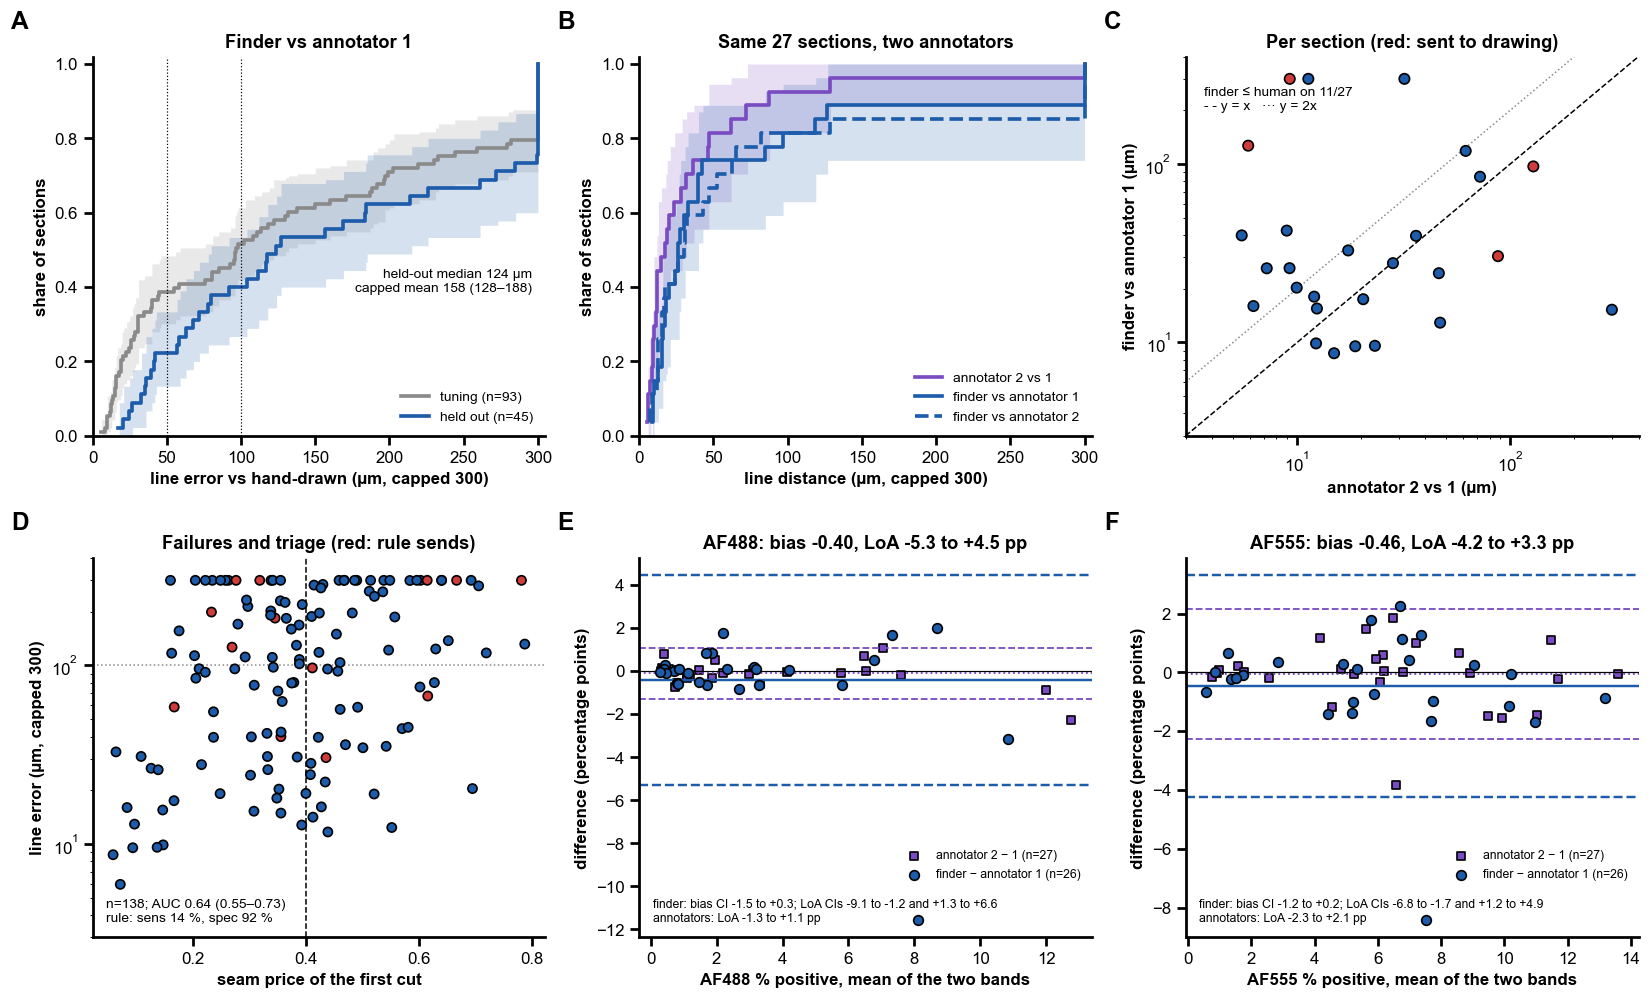

In [17]:
# Figure 2: junction detection.
fig, axes = plt.subplots(2, 3, figsize=(15, 9.2))


def ecdf(ax, values, colour, label, ls="-", band=True):
    v = np.sort(np.asarray(values, float))
    y = np.arange(1, len(v) + 1) / len(v)
    ax.step(v, y, where="post", color=colour, lw=2.4, ls=ls, label=label)
    if band:                                                     # pointwise 95 % band: section bootstrap
        grid = np.linspace(0, J_CAP, 301)
        rng_ = np.random.default_rng(SEED)
        draws = np.array([(np.sort(rng_.choice(v, len(v)))[:, None] <= grid).mean(0) for _ in range(500)])
        lo, hi = np.percentile(draws, [2.5, 97.5], axis=0)
        ax.fill_between(grid, lo, hi, step="post", color=colour, alpha=0.18, lw=0)


ax = axes[0, 0]
ecdf(ax, tune_j["error"], GREY, f"tuning (n={len(tune_j)})")
ecdf(ax, held_j["error"], AUTO_COLOUR, f"held out (n={len(held_j)})")
for x in (50, 100):
    ax.axvline(x, color="black", lw=0.8, ls=":")
ax.set_xlim(0, J_CAP + 5); ax.set_ylim(0, 1.02)
ax.set_xlabel("line error vs hand-drawn (µm, capped 300)"); ax.set_ylabel("share of sections")
ax.set_title("Finder vs annotator 1"); ax.legend(loc="lower right", fontsize=9)
ax.text(0.97, 0.38, f"held-out median {h_med[0]:.0f} µm\ncapped mean {h_cm[0]:.0f} ({h_cm[1]:.0f}–{h_cm[2]:.0f})",
        transform=ax.transAxes, ha="right", fontsize=9)

ax = axes[0, 1]
ecdf(ax, pairs_j["annotator 2 vs annotator 1"], ANNOTATOR_COLOURS["Quillan"], "annotator 2 vs 1")
ecdf(ax, pairs_j["finder vs annotator 1"], AUTO_COLOUR, "finder vs annotator 1")
ecdf(ax, pairs_j["finder vs annotator 2"], AUTO_COLOUR, "finder vs annotator 2", ls="--", band=False)
ax.set_xlim(0, J_CAP + 5); ax.set_ylim(0, 1.02)
ax.set_xlabel("line distance (µm, capped 300)"); ax.set_ylabel("share of sections")
ax.set_title(f"Same {len(pairs_j)} sections, two annotators"); ax.legend(loc="lower right", fontsize=9)

ax = axes[0, 2]
lim = (3, 400)
cl = lambda s: s.clip(lim[0], J_CAP)
ax.scatter(cl(pairs_j["annotator 2 vs annotator 1"]), cl(pairs_j["finder vs annotator 1"]), s=46,
           c=np.where(routed_2b, "#d03b3b", AUTO_COLOUR), **EDGE, zorder=3)
ax.plot(lim, lim, color="black", lw=1, ls="--"); ax.plot(lim, [2 * l for l in lim], color=GREY, lw=1, ls=":")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(*lim); ax.set_ylim(*lim)
ax.set_xlabel("annotator 2 vs 1 (µm)"); ax.set_ylabel("finder vs annotator 1 (µm)")
ax.set_title("Per section (red: sent to drawing)")
ax.text(0.04, 0.92, f"finder ≤ human on {closer}/{len(pairs_j)}\n- - y = x   ··· y = 2x", transform=ax.transAxes, fontsize=9, va="top")

ax = axes[1, 0]
sp = J["seam_price"].clip(upper=0.8)
col = np.where(rule, "#d03b3b", AUTO_COLOUR)
ax.scatter(sp, J["error"].clip(lower=3), s=36, c=col, **EDGE, zorder=3)
ax.axvline(jn.NO_SEAM_PRICE, color="black", lw=1, ls="--"); ax.axhline(J_FAIL_UM, color=GREY, lw=1, ls=":")
ax.set_yscale("log"); ax.set_ylim(3, 400)
ax.set_xlabel("seam price of the first cut"); ax.set_ylabel("line error (µm, capped 300)")
ax.set_title("Failures and triage (red: rule sends)")
ax.text(0.03, 0.04, f"n={len(J)}; AUC {auc_ci[0]:.2f} ({auc_ci[1]:.2f}–{auc_ci[2]:.2f})\nrule: sens {se_all[0]*100:.0f} %, "
        f"spec {sp_all[0]*100:.0f} %", transform=ax.transAxes, fontsize=9)

for ax, ch in zip(axes[1, 1:], CH_J):
    v, f = ba_ci(ds[ds["found"]], f"{ch} manual", f"{ch} automatic")
    h, fh_ = ba_ci(ds, f"{ch} manual", f"{ch} second")
    ax.scatter((fh_[f"{ch} manual"] + fh_[f"{ch} second"]) / 2, fh_["d"], s=34, marker="s",
               color=ANNOTATOR_COLOURS["Quillan"], **EDGE, label=f"annotator 2 − 1 (n={h['n']})", zorder=2)
    ax.scatter((f[f"{ch} manual"] + f[f"{ch} automatic"]) / 2, f["d"], s=40, color=AUTO_COLOUR, **EDGE,
               label=f"finder − annotator 1 (n={v['n']})", zorder=3)
    for key, ls in (("bias", "-"), ("low", "--"), ("high", "--")):
        ax.axhline(v[key][0], color=AUTO_COLOUR, lw=1.6, ls=ls)
        ax.axhline(h[key][0], color=ANNOTATOR_COLOURS["Quillan"], lw=1.2, ls=ls if key != "bias" else ":")
    ax.axhline(0, color="black", lw=0.8)
    ax.text(0.03, 0.04, f"finder: bias CI {v['bias'][1]:+.1f} to {v['bias'][2]:+.1f}; LoA CIs "
            f"{v['low'][1]:+.1f} to {v['low'][2]:+.1f} and {v['high'][1]:+.1f} to {v['high'][2]:+.1f}\n"
            f"annotators: LoA {h['low'][0]:+.1f} to {h['high'][0]:+.1f} pp", transform=ax.transAxes, fontsize=8)
    ax.set_xlabel(f"{ch} % positive, mean of the two bands"); ax.set_ylabel("difference (percentage points)")
    ax.set_title(f"{ch}: bias {v['bias'][0]:+.2f}, LoA {v['low'][0]:+.1f} to {v['high'][0]:+.1f} pp")
    ax.legend(loc="lower right", bbox_to_anchor=(1.0, 0.12), fontsize=8)
panel_letters(axes)
fig.tight_layout()
save(fig, "fig2_junction_detection")
plt.show()

### What section 2 showed

**The junctions used are the finder's proposal, screened by eye and redrawn by hand when wrong.** On the unselected first 30 the screening caught 4 of 5 failures and the lines it accepted lie a median 17 µm from the hand-drawn line (1 of 14 > 100 µm), about the distance between two people (17 µm). 28 % of the analysed sections were counted in a hand-drawn region. The finder alone (2a–2c) is reported for what it saves, not relied on: it fails on the hard sections, and its own flags do not spot those failures; the screening does.

Today's finder, re-run on the 138 cached sections. It matches the stored evaluation of 27 Oct on 136 of 138; two failures moved
(021-020_s6 193 → 300 µm, s29 264 → 261 µm).

| Claim | Verdict | Key numbers (95 % CI) |
|---|---|---|
| 2a. The finder alone (before screening) is accurate on held-out sections | **FAIL** (not relied on) | Held out (n = 45, 23 slides): capped mean 158 µm (128–188; slide CI 117–197), median 124 µm (80–214), 22 % within 50 µm, 40 % within 100 µm, Dice 0.53. Tuning (n = 93): 131 µm (108–154). Held out − tuning +28 µm (−11 to +66, p = 0.08), so no clear overfitting. But 37 of the 45 held-out sections are ones the reviewer rejected. On the unselected first 30: capped mean 66 µm (39–99), median 29 µm (19–41), 83 % within 100 µm. |
| 2b. The finder is within the variability between two people | **PASS with caveat** | 27 sections drawn by both people. Person vs person: median 17 µm (11–32), capped mean 39. Finder vs annotator 1: median 26 µm (17–40), capped mean 66. Paired difference: median +6 µm (−3 to +17), Wilcoxon p = 0.18. Ratio of medians 1.5 (0.86–3.2). All 27 are from the easy, unselected batch (finder median 26 µm there, against 110 µm on all 138). |
| 2c. The finder's own flags ("status fail or Damaged") spot its failures | **FAIL** (not relied on) | 72 of 138 lines are > 100 µm off; 29 are ≥ 300 µm or missing. On the 108 sections the rule was not set on, it catches 12 % of failures (6–22), with specificity 93 %. The "check" status fires on 117 of 138. Seam price AUC 0.64 (0.55–0.73). The triage actually used is review by eye. On the first 30 it caught 4 of 5 failures, and the accepted lines had median 17 µm, with 1 of 14 > 100 µm. In the run, 173 of 614 sections (28 %, 25–32) were counted in a hand-drawn region: WT3 34 %, GD1 23 % (χ² p = 0.004). |
| 2d. The finder's band gives the same % positive as the hand-drawn one | **PASS with caveat** | 26 sections, finder of 21 Oct. No bias: AF488 −0.40 pp (−1.51 to 0.31), AF555 −0.46 pp (−1.24 to 0.15). The limits of agreement are wide: AF488 −5.3 to +4.5 pp (annotators ±1.2) and AF555 −4.2 to +3.3 pp (annotators ±2.2). Without the sections triage sends to drawing (n = 23): AF488 ±2.0 pp and AF555 ±2.0 pp, no bias. The AF488 difference grows with line error (ρ 0.56, p 0.003). |

**What to report.** Report the junction as proposed by the finder, screened by eye for every section and redrawn by hand when wrong — not as an automatic result. Give:

- the held-out accuracy, with slide CIs, together with how the annotated set was selected;
- the two annotators' distance as the benchmark;
- the review's redraw rate (25 % of the sections not drawn beforehand);
- the share of each genotype counted in a hand-drawn region.

That share is uneven between genotypes, and the band source affects AF488 % positive per section. So genotype comparisons
should hold up in a sensitivity analysis with `region_by` as a covariate, or restricted to one region source.

**Limitations.**

- The 108 later sections are review rejects, so they measure the hard cases, not a random section.
- The human benchmark and the downstream test cover only the first 30 sections, and the downstream test used the finder of
  21 Oct with its positivity rule.
- No automatic flag predicts failure well enough to replace the review.

## 3. Nuclei and AF488 positivity against two independent annotators

**Claim.** The pipeline's nuclei and its AF488 call find the labelled cells a person sees, in the junction region and among the cells that crossed: the counts per section agree with hand counts, and the agreement does not depend on who counted.

**Ground truth: two annotators, different sections.** Each put one 5 µm dot on every AF488+ cell he saw, stored with the sample as a label map:

- **Quillan** ("Manual counts Quillan"): 13 sections of the run, the junction and the cells that crossed, against his own hand-drawn junction;
- **James** ("James counts"): 14 other sections, the whole section.

`notebooks/dataset/james_clicks.py` (run once per annotator: `python notebooks/dataset/james_clicks.py` and `… quillan`) places every dot like the run's cells — in or out of the run's junction region, its signed distance to the run's junction line, beside the line or not — and matches it to the nearest segmented nucleus within 7 µm, one to one. The two zones compared are the ones the paper reports: the **junction region** (the run's region; a dot or cell by its own position) and the **crossed zone** (beside the line, 2–300 µm past it, into the organoid where AF488 is not at home). James's dots far from the junction are not used here, since Quillan did not count there.

**Methods compared** (what a paper reports; validation/09 and dataset/05 compare many more):

| method | level | what it is |
|---|---|---|
| **run's rule** | cell | AF488 mean of the nucleus grown 3 µm, on the channel less its 45 µm local median, above the junction region's median + 7 robust SD (the run's `AF488 positive`) |
| **mask objects (5 SD)** | object | the classical AF488 mask (smoothed 0.5 µm, less a 20 µm Gaussian, cut at the tissue's median + 5 robust SD; `af488_masks.py`, `kmad5`): each connected piece is one labelled body, counted by its centroid |
| **old rule (raw + 3 SD)** | cell | raw AF488 mean above the region's median + 3 robust SD: the rule used before the calibration, kept as a **negative reference** |
| **retrained Cellpose (cross-val.)** | object (and cell) | Cellpose (cpsam) fine-tuned on the annotators' dots, run on the AF488 channel; each section predicted by the model of the fold it was **not** trained on (2-fold cross-validation by section); its objects counted by their centroids. Judged in **3e** |
| **retrained Cellpose (other annotator)** | object (and cell) | the same, trained on **one annotator's** sections and dots only and scored on the **other's** (James's sections by the model trained on Quillan's, and the reverse): the generalisation test (3e) |

The retrained model is added only when its files (`<annotator>_counts/methods/{objects,hits,cells}/cellpose488_retrained/`) exist for all 27 sections; until then the section runs without it and prints what is missing.

**Primary metrics, fixed before looking:** per-section Lin's CCC and the Bland–Altman bias on the ratio scale (log₂((method + 1) / (annotator + 1)), read back as ×), with 95 % CIs from 2 000 bootstraps of whole sections; cell-level recall. Precision is a lower bound (see 3c).

In [18]:
# ---------------------------------------------------------------- Settings: change these
ANNOTATORS = {"Quillan": OUT / "quillan_counts", "James": OUT / "james_counts"}   # james_clicks.py writes these
MASKS = OUT / "af488_mask"           # af488_masks.py: kmad3/5/8 cover and objects, every run section
MASK = "kmad5"                       # the mask whose objects are the body count (Gaussian 20 µm, 5 SD)
HITS_CACHE = OUT / "publication_mask_hits_kmad5.parquet"   # per dot: the kmad5 object it falls in (made below)
HIT_UM = 2.0                         # a dot within this of an object's pixel falls in it (as james_masks.py)
NUCLEUS_UM = 7.0                     # a dot "has a nucleus" when one is within this (as the 1-to-1 match)
GAP_UM, NEAR_UM = 2.0, 300.0         # crossed: beside the line, 2–300 µm past it
RUN_K, OLD_K = 7.0, 3.0
RETRAINED = "cellpose488_retrained"  # the fine-tuned Cellpose: <annotator>_counts/methods/{objects,hits,cells}/<this>/
RETRAINED_DIR = OUT / "cellpose_retrained"   # its training: folds.json (train / test sections), settings, models
RETRAINED_VARIANTS = {"retrained Cellpose (cross-val.)": "Cellpose AF488 · retrained (cross-validated)",
                      "retrained Cellpose (other annotator)": "Cellpose AF488 · retrained on the other annotator"}
COVER = 0.25                         # its cell-level call: a nucleus whose grown region it covers ≥ this share
ZONES = ["junction region", "crossed"]
# ----------------------------------------------------------------------------------------
from scipy.spatial import cKDTree
import statsmodels.formula.api as smf

sys.path.insert(0, str(ROOT / "notebooks" / "dataset"))
sys.path.insert(0, str(ROOT / "notebooks" / "validation"))

RAW, FILTERED = "AF488 mean", "AF488 mean (median filter)"
RUN_RULE, BODIES, OLD_RULE = "run's rule", "mask objects (5 SD)", "old rule (raw + 3 SD)"
RT_CV, RT_X = RETRAINED_VARIANTS
BASE_METHODS = [RUN_RULE, BODIES, OLD_RULE]     # the methods 3b–3d were planned with
METHODS = list(BASE_METHODS)                    # + the retrained Cellpose when its files exist (below)
METHOD_COLOURS = {RUN_RULE: PIPELINE_COLOUR, BODIES: "#8c4f00", OLD_RULE: GREY, RT_CV: "#8f1d5c", RT_X: "#d65088"}
CELL_EXTRA = []                                 # the retrained model's cell-level calls (3e)
WHO = list(ANNOTATORS)


def tick_label(method):
    """A method's name on two or three lines, for the x axis."""
    return method.replace("retrained Cellpose", "retrained\nCellpose").replace(" (", "\n(")


def short(name):
    return name.split("Asssembloid_")[-1]


def robust(values):
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]
    centre = float(np.median(v))
    return centre, float(1.4826 * np.median(np.abs(v - centre)))


def info_of(name):
    return json.loads((RUN / "cells" / f"{name}.json").read_text(encoding="utf-8"))


def in_zone(frame, zone):
    """Rows (cells, dots or objects with region / beside / away) in *zone*."""
    if zone == "junction region":
        return frame["region"].to_numpy(bool)
    away = frame["away"].to_numpy(float)
    return frame["beside"].to_numpy(bool) & (away > GAP_UM) & (away <= NEAR_UM)


# ---------------------------------------------------------------- Both annotators' sections, dots and cells
rows, DOTS, CELLS, OBJECTS = [], {}, {}, {}
for who, folder in ANNOTATORS.items():
    clicks = pd.read_parquet(folder / "clicks.parquet")
    for name, d in clicks.groupby("name", sort=True):
        c = pd.read_parquet(folder / "cells" / f"{name}.parquet")
        info = info_of(name)
        # AF488's home side: the side with most of the run's AF488+ cells (as dataset/04 and 05); away > 0 = past it.
        pos = c["AF488 positive"].to_numpy(bool) & c["beside"].to_numpy(bool)
        sign = -1.0 if pos.sum() >= 5 and np.median(c.loc[pos, "d"]) > 0 else 1.0
        c["away"] = c["d"] * sign
        d = d.assign(away=d["d"] * sign).reset_index(drop=True)
        region = c["region"].to_numpy(bool)
        c[RUN_RULE] = c["AF488 positive"].to_numpy(bool)
        c[OLD_RULE] = c[RAW].to_numpy(float) > (lambda m, s: m + OLD_K * s)(*robust(c.loc[region, RAW]))
        c["recomputed run rule"] = c[FILTERED].to_numpy(float) > (lambda m, s: m + RUN_K * s)(*robust(c.loc[region, FILTERED]))
        o = pd.read_parquet(MASKS / name / "objects.parquet")
        o = o[o["mask"] == MASK]
        OBJECTS[name] = pd.DataFrame({"object": o["Object"].to_numpy(np.int64),
                                      "y": o["Centroid Y (µm)"].to_numpy(float), "x": o["Centroid X (µm)"].to_numpy(float),
                                      "region": o["In region"].fillna(False).to_numpy(bool),
                                      "beside": o["Beside the junction line"].fillna(False).to_numpy(bool),
                                      "away": o["Distance to the junction line (µm)"].to_numpy(float) * sign})
        DOTS[name], CELLS[name] = d, c
        rows.append({"name": name, "annotator": who, "length (mm)": info["junction_length_um"] / 1000,
                     "region by": info.get("region_by", ""), "sign": sign})
hand_sections = pd.DataFrame(rows).merge(design[["name", "Genotype", "slide"]], on="name", how="left").set_index("name")
names = list(hand_sections.index)
assert not hand_sections.index.duplicated().any(), "a section counted by both annotators"
mismatch = sum(int((c["recomputed run rule"] != c[RUN_RULE]).sum()) for c in CELLS.values())


# ---------------------------------------------------------------- Which mask object each dot falls in
def mask_hits():
    """Per dot of both annotators, the kmad5 object it falls in (nearest object pixel within HIT_UM), 0 for none.

    The mask is recomputed exactly as af488_masks.py (classical_vs_cellpose.classical_masks); each recomputed
    object is mapped to the stored one of af488_mask/<name>/objects.parquet by its centroid (≤ 1 µm), so a
    dot's object is one the counts use. ~20 s a section."""
    import classical_vs_cellpose as cv
    from james_masks import hits_of
    from skimage.measure import label, regionprops_table

    out = []
    for name in names:
        info = info_of(name)
        af488, nuclear, voxel = cv.read_planes(Path(info["file"]))
        tissue = cv.tissue_mask(nuclear)
        del nuclear
        masks, _meta = cv.classical_masks(af488, tissue, voxel)
        del af488, tissue
        labelled = label(masks[MASK], connectivity=2)
        del masks
        # Each recomputed object is the stored one whose centroid is within 1 µm of its own (0: none).
        props = regionprops_table(labelled, properties=("label", "centroid"))
        mine = np.column_stack([props["centroid-0"], props["centroid-1"]]) * voxel
        dist, near = cKDTree(OBJECTS[name][["y", "x"]].to_numpy(float)).query(mine)
        stored = np.zeros(int(labelled.max()) + 1, np.int64)
        stored[props["label"]] = np.where(dist <= 1.0, OBJECTS[name]["object"].to_numpy()[near], 0)
        d = DOTS[name]
        hit = stored[hits_of(labelled, d[["y", "x"]].to_numpy(float) / voxel, HIT_UM / voxel)]
        out.append(pd.DataFrame({"name": name, "dot": d["dot"].to_numpy(), "object": hit}))
        print(f"  {short(name)}: {len(d)} dots, {np.mean(hit > 0):.0%} in a {MASK} object; "
              f"{int((stored[1:] > 0).sum())} of {len(stored) - 1} recomputed objects = stored ({len(OBJECTS[name])})",
              flush=True)
    return pd.concat(out, ignore_index=True)


if HITS_CACHE.exists():
    hits = pd.read_parquet(HITS_CACHE)
else:
    print(f"computing the {MASK} mask of {len(names)} sections (once; cached in {HITS_CACHE.name}) …")
    hits = mask_hits()
    hits.to_parquet(HITS_CACHE, index=False)
for name in names:
    DOTS[name]["object"] = DOTS[name]["dot"].map(hits[hits["name"] == name].set_index("dot")["object"]).fillna(0).astype(int).to_numpy()
# Every object-level method: its objects per section, and per dot the object it falls in (0: none).
OBJ_TABLES = {BODIES: OBJECTS}
OBJ_HITS = {BODIES: {n: DOTS[n]["object"].to_numpy() for n in names}}


def retrained_missing():
    """What of the retrained Cellpose's files is not there yet (empty: everything is)."""
    missing = []
    for kind in ("objects", "hits", "cells"):
        for who in WHO:
            folder = ANNOTATORS[who] / "methods" / kind / RETRAINED
            gone = [n for n in names if hand_sections.at[n, "annotator"] == who and not (folder / f"{n}.parquet").exists()]
            if gone:
                missing.append(f"{kind}/{RETRAINED} for {who}: {len(gone)} of "
                               f"{int((hand_sections.annotator == who).sum())} sections missing")
    return missing


def load_retrained():
    """Objects, dot hits and cell calls of both retrained variants, every section; their columns checked first."""
    for n in names:
        folder = ANNOTATORS[hand_sections.at[n, "annotator"]] / "methods"
        o = pd.read_parquet(folder / "objects" / RETRAINED / f"{n}.parquet")
        h = pd.read_parquet(folder / "hits" / RETRAINED / f"{n}.parquet").set_index("dot").reindex(DOTS[n]["dot"].to_numpy())
        c = pd.read_parquet(folder / "cells" / RETRAINED / f"{n}.parquet")
        c = c.assign(Label=c["Label"].astype(np.int64)).set_index("Label")
        for method, variant in RETRAINED_VARIANTS.items():
            for what, ok in (("objects' method", variant in set(o["method"])), ("hits column", variant in h),
                             ("cells column", f"cover {variant}" in c)):
                if not ok:
                    raise KeyError(f"{short(n)}: no {what} {variant!r}")
            v = o[o["method"] == variant]
            OBJ_TABLES.setdefault(method, {})[n] = pd.DataFrame({
                "object": v["object"].to_numpy(np.int64), "y": v["y"].to_numpy(float), "x": v["x"].to_numpy(float),
                "region": v["region"].fillna(False).to_numpy(bool), "beside": v["beside"].fillna(False).to_numpy(bool),
                "away": v["d"].to_numpy(float) * hand_sections.at[n, "sign"]})
            hit = h[variant].fillna(0).to_numpy(np.int64)
            OBJ_HITS.setdefault(method, {})[n] = np.where(np.isin(hit, v["object"].to_numpy()), hit, 0)
            cover = CELLS[n]["label"].map(c[f"cover {variant}"]).to_numpy(float)
            CELLS[n][f"{method} · cells"] = np.nan_to_num(cover, nan=0.0) >= COVER


def fold_check():
    """From folds.json: every fold's train and test sections, whether any section is tested by a model trained on
    it, and the sections never tested. Accepts any nesting of {…train…: [names], …test…: [names]}."""
    path = RETRAINED_DIR / "folds.json"
    if not path.exists():
        return f"{path.name} not found in {RETRAINED_DIR}: the no-leak check cannot be made here"
    folds = []

    def walk(node, where):
        if isinstance(node, dict):
            train = next((v for k, v in node.items() if "train" in str(k).lower() and isinstance(v, list)), None)
            test = next((v for k, v in node.items() if "test" in str(k).lower() and isinstance(v, list)), None)
            if train is not None and test is not None:
                folds.append((str(node.get("method", where)), {str(t) for t in train}, {str(t) for t in test}))
                return
            for k, v in node.items():
                walk(v, f"{where}/{k}")
        elif isinstance(node, list):
            for i, v in enumerate(node):
                walk(v, f"{where}[{i}]")

    walk(json.loads(path.read_text(encoding="utf-8")), "")
    if not folds:
        return f"{path.name}: no fold with train and test lists found"
    leaks = [(w, sorted(tr & te)) for w, tr, te in folds if tr & te]
    per_model = []
    for model in dict.fromkeys(w for w, _tr, _te in folds):      # each variant: every section tested exactly once
        times = pd.Series([t for w, _tr, te in folds if w == model for t in te]).value_counts()
        tested = {n: int(times.get(n, 0) + times.get(short(n), 0)) for n in names}
        per_model.append(f"{model}: {sum(v == 1 for v in tested.values())} of {len(names)} sections tested once, "
                         f"{sum(v == 0 for v in tested.values())} never, {sum(v > 1 for v in tested.values())} more than once")
    return (f"{len(folds)} trainings in {path.name}; sections both trained on and tested by one model: "
            f"{sum(len(l) for _w, l in leaks)} ({'none' if not leaks else leaks}); " + "; ".join(per_model))


RETRAINED_MISSING = retrained_missing()
if RETRAINED_MISSING:
    print("retrained Cellpose left out (re-run once its training script has written everything):\n  "
          + "\n  ".join(RETRAINED_MISSING))
else:
    try:
        load_retrained()
        METHODS += list(RETRAINED_VARIANTS)
        CELL_EXTRA = [f"{m} · cells" for m in RETRAINED_VARIANTS]
        print(f"retrained Cellpose: both variants on all {len(names)} sections; " + fold_check())
    except (KeyError, OSError, ValueError) as error:      # a file still being written, or another layout
        RETRAINED_MISSING = [f"files present but not readable as expected: {error}"]
        for table in (OBJ_TABLES, OBJ_HITS):
            for method in RETRAINED_VARIANTS:
                table.pop(method, None)
        print("retrained Cellpose left out: " + RETRAINED_MISSING[0])

# James's own lookup (james_masks.py, the same mask) as a check of the recomputation.
jh = OUT / "james_counts" / "methods" / "hits" / "mask"
same = [np.mean((pd.read_parquet(jh / f"{n}.parquet").set_index("dot")["mask · Gaussian 20 µm · 5 SD"]
                 .reindex(DOTS[n]["dot"]).to_numpy() > 0) == (DOTS[n]["object"].to_numpy() > 0))
        for n in names if hand_sections.at[n, "annotator"] == "James" and (jh / f"{n}.parquet").exists()]

print(", ".join(f"{who}: {int((hand_sections.annotator == who).sum())} sections "
                f"({', '.join(f'{g} {int(((hand_sections.annotator == who) & (hand_sections.Genotype == g)).sum())}' for g in GENOTYPES)}; "
                f"{hand_sections.loc[hand_sections.annotator == who, 'slide'].nunique()} slides), "
                f"{sum(len(DOTS[n]) for n in hand_sections.index[hand_sections.annotator == who])} dots" for who in WHO))
by_hand = (hand_sections["region by"] == "by hand").groupby(hand_sections["annotator"]).sum()
print("region drawn by hand: " + ", ".join(f"{w} {int(by_hand[w])}" for w in WHO))
print(f"the run's rule recomputed: {mismatch} cells called differently (0 expected)")
if same:
    print(f"dot in a {MASK} object, recomputed vs james_masks.py on James's sections: {np.mean(same):.2%} alike")

retrained Cellpose: both variants on all 27 sections; 4 trainings in folds.json; sections both trained on and tested by one model: 0 (none); Cellpose AF488 · retrained (cross-validated): 27 of 27 sections tested once, 0 never, 0 more than once; Cellpose AF488 · retrained on the other annotator: 27 of 27 sections tested once, 0 never, 0 more than once
Quillan: 13 sections (WT3 8, GD1 5; 11 slides), 843 dots, James: 14 sections (WT3 7, GD1 7; 11 slides), 3377 dots
region drawn by hand: Quillan 13, James 3
the run's rule recomputed: 0 cells called differently (0 expected)
dot in a kmad5 object, recomputed vs james_masks.py on James's sections: 100.00% alike


### 3a. Nuclear segmentation is not the bottleneck

A cell-level method can only call a cell Cellpose segmented. Per annotator, the share of his dots with a **segmented nucleus within 7 µm** (any nucleus; the one-to-one match of `james_clicks.py`, which also forbids two dots on one nucleus, is given beside it) — the ceiling on any cell-level recall. If it is high while the run's rule finds far fewer of the dots (3c), the loss is in the AF488 call, not in the nuclei. 95 % CIs: 2 000 bootstraps of whole sections, the share recomputed as total dots with a nucleus ÷ total dots.

**Pre-specified:** PASS when the share is ≥ 85 % with its lower CI bound ≥ 80 % for both annotators in both zones.

sections  dots  nucleus ≤ 7 µm  CI low  CI high  matched 1 to 1  1:1 CI low  1:1 CI high  distance, median (µm)
annotator zone                                                                                                                            
Quillan   all dots               13   843           0.875   0.815    0.933           0.865       0.809        0.917                  3.120
          junction region        13   318           0.931   0.888    0.973           0.918       0.885        0.953                  2.936
          crossed                13   271           0.959   0.923    0.986           0.945       0.916        0.968                  2.928
James     all dots               14  3377           0.886   0.841    0.921           0.885       0.840        0.919                  2.612
          junction region        14   169           0.911   0.874    0.947           0.911       0.874        0.947                  2.592
          crossed                14   137           0.942   0.903    0.980           0.942       0.903        0.980                  2.425
both      all dots               27  4220           0.884   0.846    0.914           0.881       0.843        0.911                  2.717
          junction region        27   487           0.924   0.894    0.955           0.916       0.891        0.942                  2.862
          crossed                27   408           0.953   0.925    0.977           0.944       0.921        0.965                  2.759

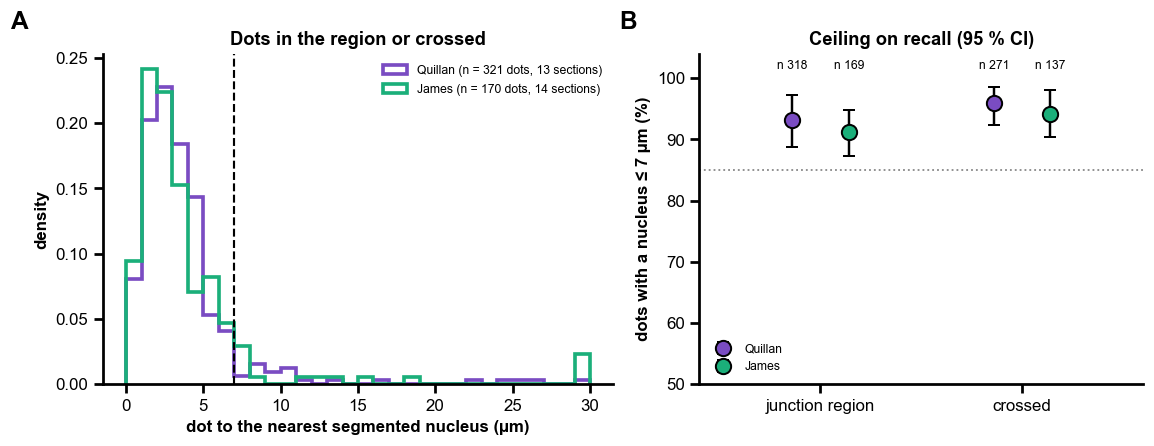

[PASS] 3a. Nuclear segmentation is not the bottleneck
    Quillan junction region: 93% [89%, 97%]; Quillan crossed: 96% [92%, 99%]; James junction region: 91% [87%, 95%]; James crossed: 94% [90%, 98%]


In [19]:
def nearest_nucleus(name):
    c, d = CELLS[name], DOTS[name]
    dist, _ = cKDTree(c[["y", "x"]].to_numpy(float)).query(d[["y", "x"]].to_numpy(float))
    return dist


for name in names:
    DOTS[name]["nucleus µm"] = nearest_nucleus(name)
alldots = pd.concat([DOTS[n].assign(annotator=hand_sections.at[n, "annotator"]) for n in names], ignore_index=True)
alldots["region zone"] = np.concatenate([in_zone(DOTS[n], "junction region") for n in names])
alldots["crossed zone"] = np.concatenate([in_zone(DOTS[n], "crossed") for n in names])
alldots["within"] = alldots["nucleus µm"] <= NUCLEUS_UM


def share(column):
    return lambda f: f[column].sum() / max(len(f), 1)


ceiling_rows = []
for who in [*WHO, "both"]:
    for zone, flag in (("all dots", None), ("junction region", "region zone"), ("crossed", "crossed zone")):
        f = alldots if who == "both" else alldots[alldots["annotator"] == who]
        f = f if flag is None else f[f[flag]]
        est, lo, hi = boot_ci(f, share("within"), groups="name")
        m, mlo, mhi = boot_ci(f, share("matched"), groups="name")
        ceiling_rows.append({"annotator": who, "zone": zone, "sections": f["name"].nunique(), "dots": len(f),
                             "nucleus ≤ 7 µm": est, "CI low": lo, "CI high": hi,
                             "matched 1 to 1": m, "1:1 CI low": mlo, "1:1 CI high": mhi,
                             "distance, median (µm)": f["nucleus µm"].median()})
ceiling = pd.DataFrame(ceiling_rows).set_index(["annotator", "zone"])
display(ceiling.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
bins = np.arange(0, 30.5, 1)
for who in WHO:
    f = alldots[(alldots["annotator"] == who) & (alldots["region zone"] | alldots["crossed zone"])]
    ax.hist(f["nucleus µm"].clip(upper=30), bins=bins, density=True, histtype="step", lw=2.4,
            color=ANNOTATOR_COLOURS[who], label=f"{who} (n = {len(f)} dots, {f['name'].nunique()} sections)")
ax.axvline(NUCLEUS_UM, color="black", ls="--", lw=1.4)
ax.set_xlabel("dot to the nearest segmented nucleus (µm)")
ax.set_ylabel("density")
ax.set_title("Dots in the region or crossed")
ax.legend(fontsize=8, loc="upper right")
ax = axes[1]
xs = {"junction region": 0, "crossed": 1}
for k, who in enumerate(WHO):
    for zone, x in xs.items():
        r = ceiling.loc[(who, zone)]
        ax.errorbar(x + (k - 0.5) * 0.28, r["nucleus ≤ 7 µm"] * 100,
                    yerr=[[100 * (r["nucleus ≤ 7 µm"] - r["CI low"])], [100 * (r["CI high"] - r["nucleus ≤ 7 µm"])]],
                    fmt="o", ms=10, color=ANNOTATOR_COLOURS[who], mec="black", mew=1.3, ecolor="black", capsize=4,
                    lw=1.6, label=who if zone == "junction region" else None)
        ax.text(x + (k - 0.5) * 0.28, 101.5, f"n {int(r['dots'])}", ha="center", fontsize=8)
ax.axhline(85, color=GREY, ls=":", lw=1.2)
ax.set_xticks(list(xs.values()), list(xs))
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(50, 104)
ax.set_ylabel("dots with a nucleus ≤ 7 µm (%)")
ax.set_title("Ceiling on recall (95 % CI)")
ax.legend(fontsize=8, loc="lower left")
panel_letters(axes)
fig.tight_layout()
save(fig, "pos_a_nucleus_ceiling")
plt.show()

zone_rows = ceiling.drop(index="all dots", level="zone").drop(index="both", level="annotator")
ok_a = bool((zone_rows["nucleus ≤ 7 µm"] >= 0.85).all() and (zone_rows["CI low"] >= 0.80).all())
verdict("3a. Nuclear segmentation is not the bottleneck", "PASS" if ok_a else "PASS with caveat",
        "; ".join(f"{who} {zone}: {ceiling.at[(who, zone), 'nucleus ≤ 7 µm']:.0%} "
                  f"[{ceiling.at[(who, zone), 'CI low']:.0%}, {ceiling.at[(who, zone), 'CI high']:.0%}]"
                  for who in WHO for zone in ZONES),
        "share of hand dots with a segmented nucleus ≤ 7 µm, per annotator, section-bootstrap 95 % CI")

**Verdict 3a — PASS.** A segmented nucleus lies within 7 µm of 93 % [89, 97] of Quillan's dots in the junction region and 96 % [92, 99] of those that crossed; for James 91 % [87, 95] and 94 % [90, 98] (section-bootstrap 95 % CIs; 487 and 408 dots pooled, median distance 2.9 µm). The one-to-one match gives almost the same shares (92 % and 94 % pooled). The run's rule finds only 41–58 % of the dots (3c), so the loss is in the AF488 call, not in the nuclei. **Report:** "≥ 91 % of hand-marked AF488+ cells had a segmented nucleus within 7 µm (both annotators, both zones; 95 % CI lower bound ≥ 87 %)."

### 3b. Per-section counts against each annotator

Per section and zone, the annotator's dots against each method's AF488+ cells (cell level, counted by their centres) or objects (mask objects, by their centroids). Plain counts, not per mm: both sides come from the same section and the same zone, so the junction length cancels.

Per method, zone and annotator, and **pooled** over the 27 sections (annotator kept as a column):

- **Lin's CCC** — the same number per section (1 only on the 1 : 1 line);
- **Bland–Altman on the ratio scale** — y = log₂((method + 1) / (annotator + 1)); the **bias** (mean, read back as ×: 1 = the same count) with its 95 % CI, and the **95 % limits of agreement** (bias ± 1.96 SD, as ×): 95 % of sections fall between them;
- **Spearman ρ** — the same ranking of sections;
- **CCC on log₂(count + 1)** — a sensitivity analysis: counts span 2–50 per section, so the plain CCC is carried by the few largest sections; on the log scale every section weighs alike (the scale the Bland–Altman uses).

CIs: 2 000 bootstraps of whole sections (pooled: of the 27). 13–14 sections per annotator is few: read the CIs, not the points.

**Pre-specified:** a method agrees with the hand counts (PASS) when, pooled, the bias CI lies within 0.67–1.5× and the CCC's lower CI bound is ≥ 0.5, in both zones; PASS with caveat when the bias passes but the limits of agreement are wider than half-to-twice (0.5–2×).

**How to read the figure:** one column per method, top: method count (y) against the annotator's (x), one dot per section coloured by annotator, the dashed line 1 : 1; bottom: the Bland–Altman plot on the ratio scale — thick line the pooled bias, dashed the limits of agreement, dotted 0 (the same count).

sections  hand, median  method, median   CCC  CCC low  CCC high  CCC log  CCC log low  CCC log high  bias ×  bias × low  bias × high  LoA × low  \
zone            method                               annotator                                                                                                                                                    
junction region run's rule                           Quillan          13          23.0            27.0  0.43     0.27      0.55     0.50         0.16          0.71    1.28        0.83         2.02       0.23   
                                                     James            14           8.0             9.0  0.39     0.21      0.64     0.56         0.33          0.71    1.02        0.66         1.52       0.20   
                                                     pooled           27          14.0            10.0  0.49     0.35      0.59     0.63         0.41          0.76    1.14        0.83         1.54       0.22   
                mask objects (5 SD)                  Quillan          13          23.0            27.0  0.42     0.26      0.83     0.63         0.37          0.73    1.21        0.87         1.74       0.33   
                                                     James            14           8.0            10.0  0.57     0.21      0.66     0.57         0.15          0.74    0.97        0.68         1.41       0.24   
                                                     pooled           27          14.0            12.0  0.51     0.41      0.79     0.70         0.54          0.78    1.08        0.84         1.40       0.29   
                old rule (raw + 3 SD)                Quillan          13          23.0           152.0 -0.00    -0.03      0.10     0.04        -0.08          0.18    5.36        2.71         9.92       0.45   
                                                     James            14           8.0            87.0  0.00    -0.03      0.05     0.10        -0.04          0.32    6.66        3.34        13.90       0.43   
                                                     pooled           27          14.0           112.0  0.01    -0.02      0.05     0.11        -0.03          0.27    6.00        3.69         9.60       0.46   
                retrained Cellpose (cross-val.)      Quillan          13          23.0             9.0  0.55     0.21      0.76     0.47         0.20          0.71    0.42        0.31         0.54       0.14   
                                                     James            14           8.0             3.0  0.30     0.17      0.65     0.43         0.15          0.65    0.48        0.35         0.67       0.13   
                                                     pooled           27          14.0             6.0  0.52     0.26      0.74     0.51         0.32          0.67    0.45        0.36         0.56       0.14   
                retrained Cellpose (other annotator) Quillan          13          23.0             5.0  0.47     0.16      0.66     0.34         0.15          0.54    0.29        0.20         0.42       0.07   
                                                     James            14           8.0             3.0  0.45     0.25      0.73     0.46         0.17          0.70    0.49        0.33         0.71       0.11   
                                                     pooled           27          14.0             4.0  0.49     0.26      0.65     0.41         0.23          0.58    0.38        0.28         0.51       0.08   
crossed         run's rule                           Quillan          13          18.0            26.0  0.39     0.26      0.47     0.48         0.13          0.67    1.36        0.86         2.15       0.24   
                                                     James            14           7.0             8.0  0.38     0.21      0.61     0.54         0.30          0.68    1.05        0.69         1.56       0.22   
                                                     po

hand counts per section (region / crossed):


annotator             James                                                                                                                                                         Quillan                        \
name            019-018_s16 020-019_s9 028-027_s9 032-031_s25 032-031_s9 034-033_s25 037-036_s3 038-037_s11 038-037_s9 039-038_s1 051-050_s3 052-051_s15 057-056_s10 057-056_s22 020-019_s4 026-025_s4 026-025_s8   
zone                                                                                                                                                                                                                
junction region           7          5         18          23         12          15          8           8         47          5          5          11           2           3         14         31         50   
crossed                   6          4         17          17         10          12          5           8         35          5          5           8           2           3          8         31         50   

annotator                                                                                                                            
name            028-027_s12 031-030_s7 033-032_s12 034-033_s13 034-033_s17 039-038_s5 045-044_s15 048-047_s6 052-051_s14 054-053_s7  
zone                                                                                                                                 
junction region           3         23          49          31          31         24          13         20          19         10  
crossed                   3         21          32          28          25         17          13         18          15         10

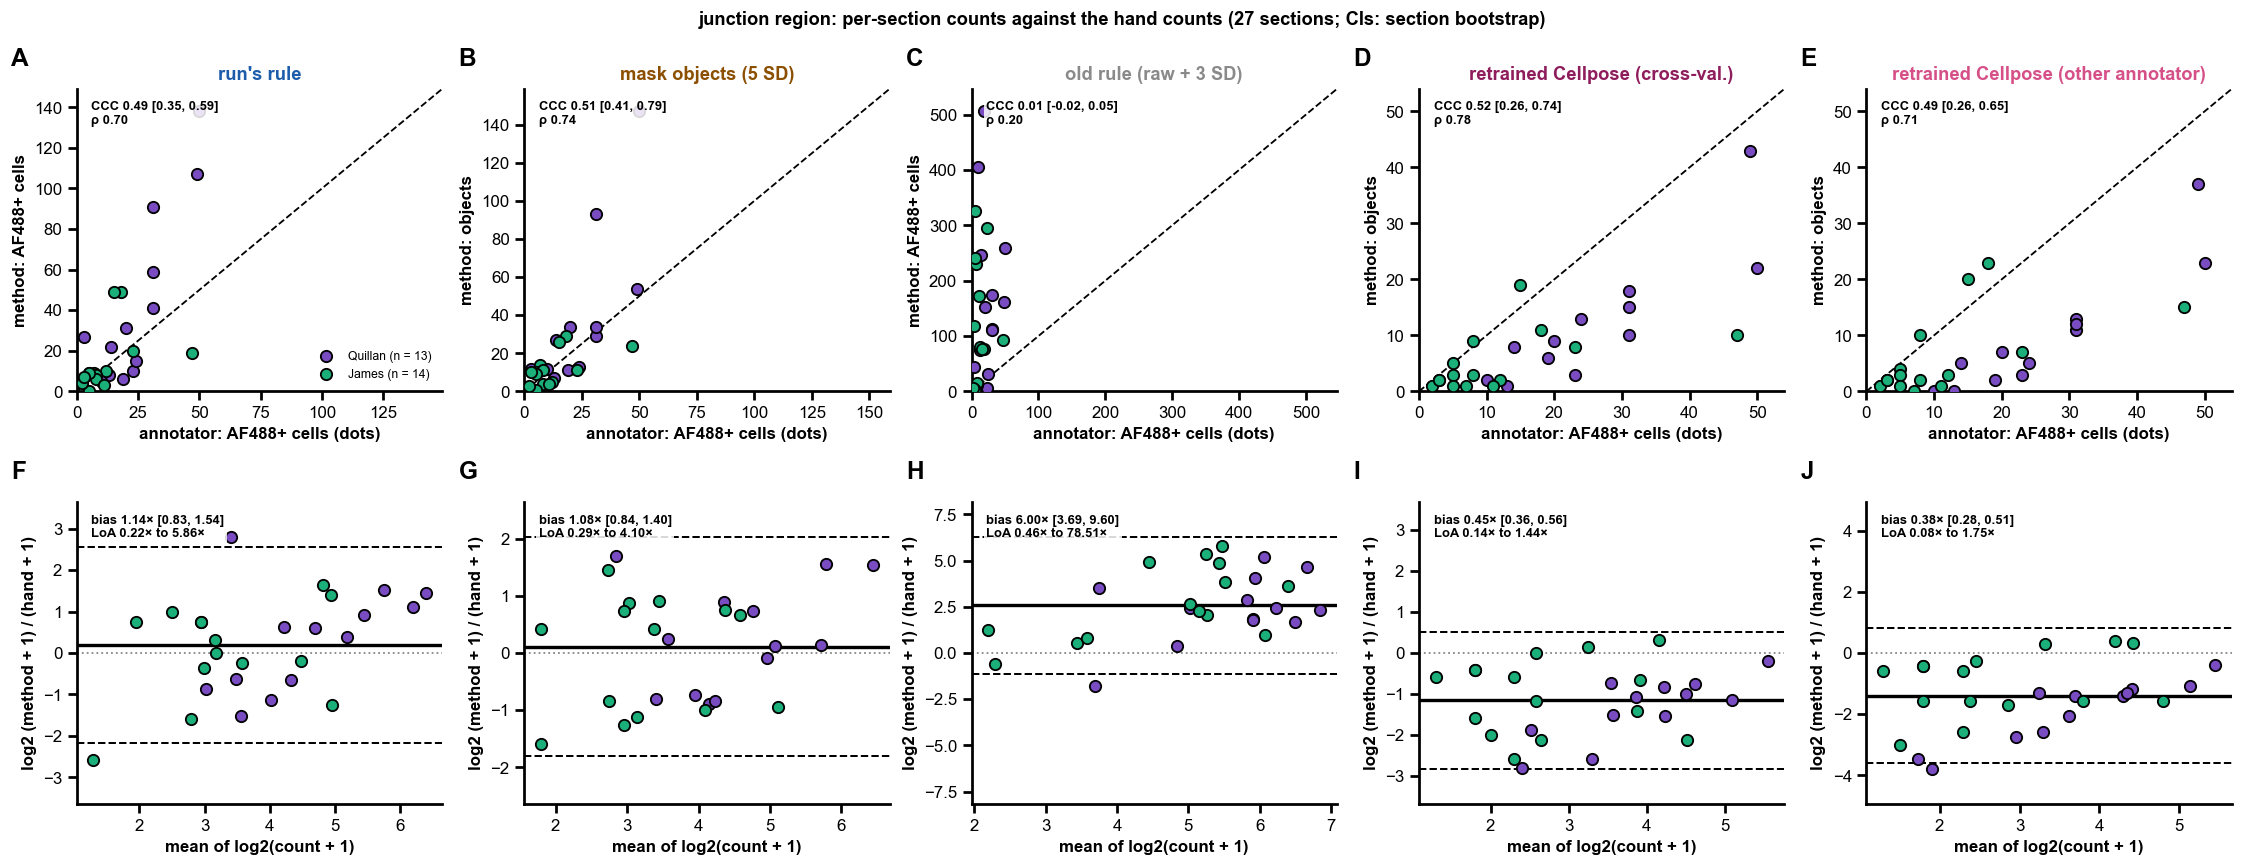

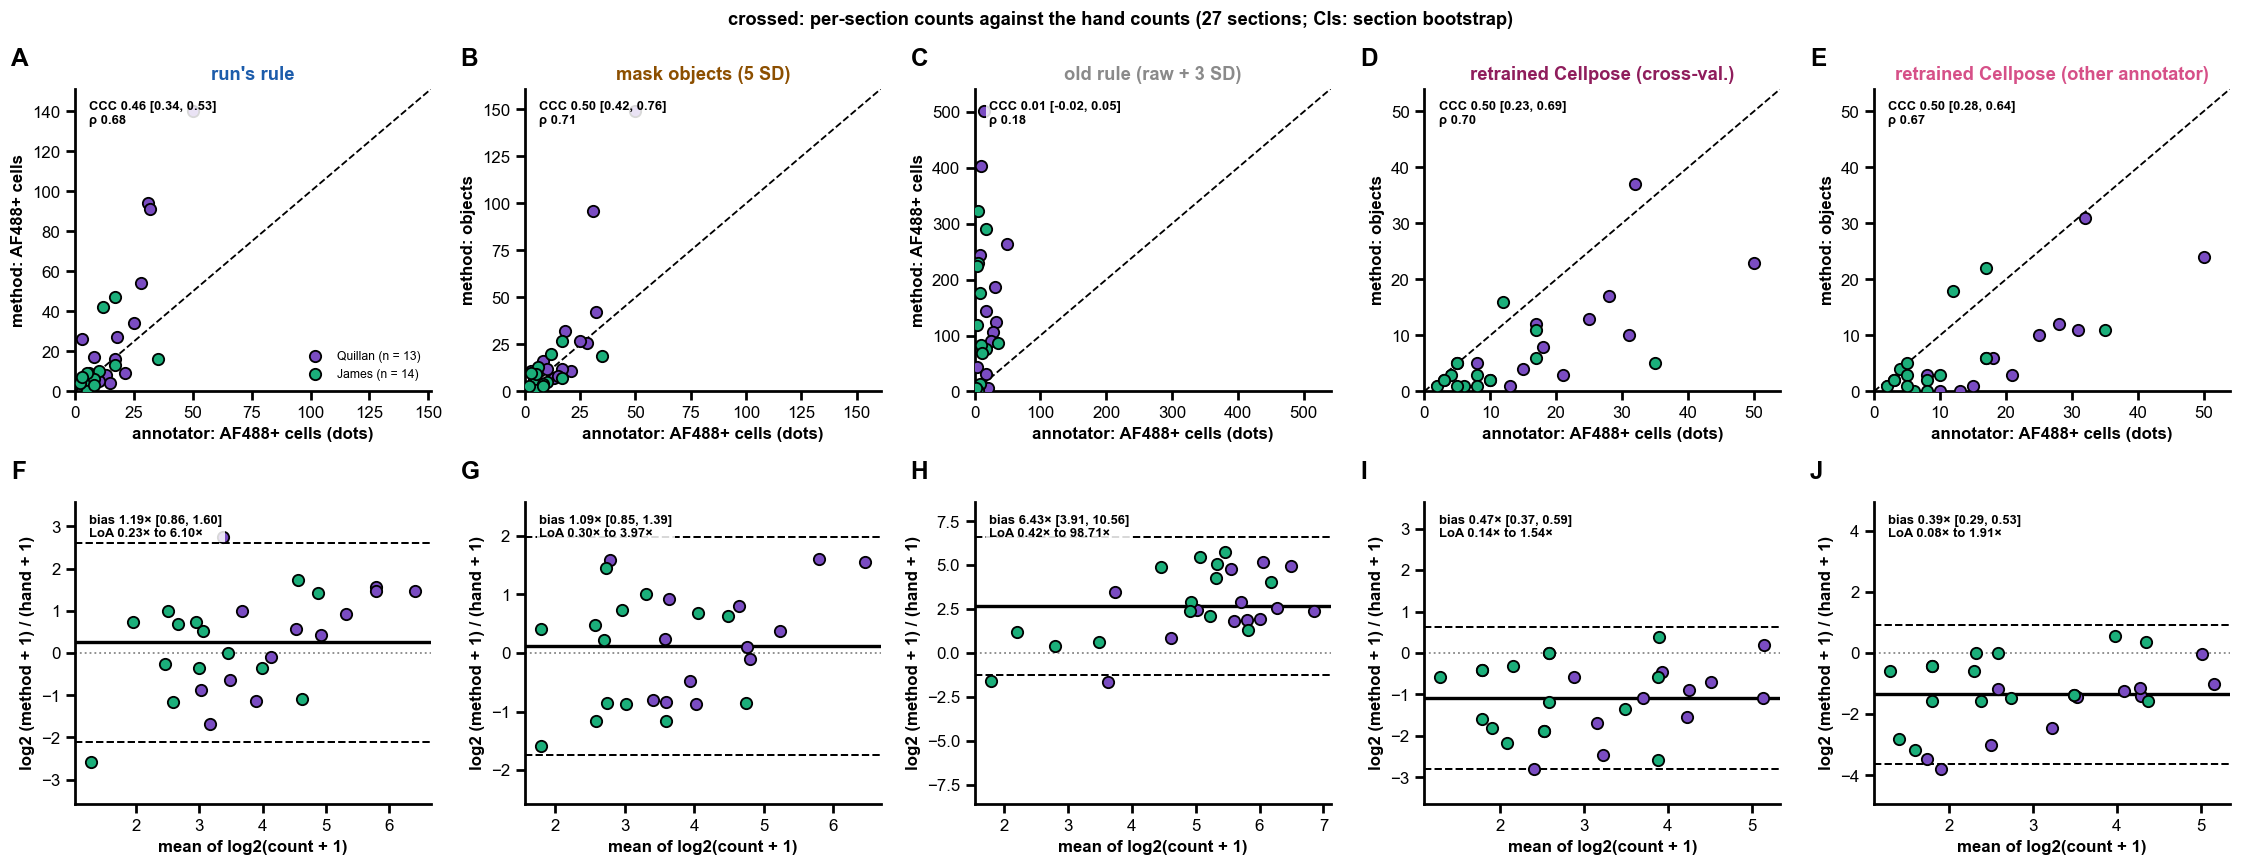

[FAIL] 3b. Per-section counts agree with the hand counts: run's rule
    junction region: CCC 0.49 [0.35, 0.59], bias 1.14× [0.83, 1.54], LoA 0.22–5.86×, ρ 0.70, CCC on log₂ 0.63 [0.41, 0.76]; crossed: CCC 0.46 [0.34, 0.53], bias 1.19× [0.86, 1.60], LoA 0.23–6.10×, ρ 0.68, CCC on log₂ 0.61 [0.38, 0.75]
[FAIL] 3b. Per-section counts agree with the hand counts: mask objects (5 SD)
    junction region: CCC 0.51 [0.41, 0.79], bias 1.08× [0.84, 1.40], LoA 0.29–4.10×, ρ 0.74, CCC on log₂ 0.70 [0.54, 0.78]; crossed: CCC 0.50 [0.42, 0.76], bias 1.09× [0.85, 1.39], LoA 0.30–3.97×, ρ 0.71, CCC on log₂ 0.70 [0.51, 0.79]
[FAIL] 3b. Per-section counts agree with the hand counts: old rule (raw + 3 SD)
    junction region: CCC 0.01 [-0.02, 0.05], bias 6.00× [3.69, 9.60], LoA 0.46–78.51×, ρ 0.20, CCC on log₂ 0.11 [-0.03, 0.27]; crossed: CCC 0.01 [-0.02, 0.05], bias 6.43× [3.91, 10.56], LoA 0.42–98.71×, ρ 0.18, CCC on log₂ 0.10 [-0.03, 0.25]
[FAIL] 3b. Per-section counts agree with the hand counts: ret

In [20]:
def count_of(name, method, zone):
    if method in OBJ_TABLES:
        return int(in_zone(OBJ_TABLES[method][name], zone).sum())
    c = CELLS[name]
    return int((c[method].to_numpy(bool) & in_zone(c, zone)).sum())


counts = pd.DataFrame([{"name": n, "annotator": hand_sections.at[n, "annotator"], "Genotype": hand_sections.at[n, "Genotype"],
                        "zone": zone, "hand": int(in_zone(DOTS[n], zone).sum()),
                        **{m: count_of(n, m, zone) for m in METHODS}}
                       for n in names for zone in ZONES])


def boot_rows(frame, statistic, n=N_BOOT, seed=SEED):
    """statistic(frame) and its percentile 95 % CI over bootstraps of the frame's rows (one row = one section)."""
    rng = np.random.default_rng(seed)
    est = statistic(frame)
    draws = np.array([statistic(frame.iloc[rng.integers(0, len(frame), len(frame))]) for _ in range(n)], float)
    return est, *np.nanpercentile(draws, [2.5, 97.5])


def log_ratio(f, method):
    return np.log2((f[method].to_numpy(float) + 1) / (f["hand"].to_numpy(float) + 1))


agree_rows = []
for zone in ZONES:
    for method in METHODS:
        for who in [*WHO, "pooled"]:
            f = counts[counts["zone"] == zone]
            f = f if who == "pooled" else f[f["annotator"] == who]
            c, clo, chi = boot_rows(f, lambda g: ccc(g["hand"], g[method]))
            lc, lclo, lchi = boot_rows(f, lambda g: ccc(np.log2(g["hand"] + 1), np.log2(g[method] + 1)))
            b, blo, bhi = boot_rows(f, lambda g: log_ratio(g, method).mean())
            ba = bland_altman(f["hand"], f[method], log=True)
            rho = stats.spearmanr(f["hand"], f[method])
            agree_rows.append({"zone": zone, "method": method, "annotator": who, "sections": len(f),
                               "hand, median": f["hand"].median(), "method, median": f[method].median(),
                               "CCC": c, "CCC low": clo, "CCC high": chi,
                               "CCC log": lc, "CCC log low": lclo, "CCC log high": lchi,
                               "bias ×": 2 ** b, "bias × low": 2 ** blo, "bias × high": 2 ** bhi,
                               "LoA × low": 2 ** ba["low"], "LoA × high": 2 ** ba["high"],
                               "Spearman ρ": rho.statistic, "ρ p": rho.pvalue})
agreement = pd.DataFrame(agree_rows).set_index(["zone", "method", "annotator"])
display(agreement.round(2))
print("hand counts per section (region / crossed):")
display(counts.pivot_table(index=["annotator", "name"], columns="zone", values="hand")[ZONES]
        .rename(index=short, level="name").astype(int).T)


def agreement_figure(zone):
    f = counts[counts["zone"] == zone]
    fig, axes = plt.subplots(2, len(METHODS), figsize=(4.1 * len(METHODS), 8.0), squeeze=False)
    for j, method in enumerate(METHODS):
        a = agreement.loc[(zone, method, "pooled")]
        ax = axes[0, j]
        top = max(f["hand"].max(), f[method].max(), 1) * 1.08
        ax.plot([0, top], [0, top], color="black", ls="--", lw=1.2, zorder=1)
        for who in WHO:
            g = f[f["annotator"] == who]
            ax.scatter(g["hand"], g[method], s=55, color=ANNOTATOR_COLOURS[who], edgecolor="black", linewidth=1.2,
                       zorder=3, label=f"{who} (n = {len(g)})")
        ax.set_xlim(0, top)
        ax.set_ylim(0, top)
        ax.set_xlabel("annotator: AF488+ cells (dots)")
        ax.set_ylabel(f"method: {'objects' if method in OBJ_TABLES else 'AF488+ cells'}")
        ax.set_title(method, color=METHOD_COLOURS[method])
        ax.text(0.04, 0.96, f"CCC {a['CCC']:.2f} [{a['CCC low']:.2f}, {a['CCC high']:.2f}]\nρ {a['Spearman ρ']:.2f}",
                transform=ax.transAxes, va="top", fontsize=8.5, fontweight="bold", zorder=5,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
        ax = axes[1, j]
        ba = bland_altman(f["hand"], f[method], log=True)
        ax.axhline(0, color=GREY, lw=1.2, ls=":")
        ax.axhline(ba["bias"], color="black", lw=2.2)
        for lim in (ba["low"], ba["high"]):
            ax.axhline(lim, color="black", lw=1.3, ls="--")
        for who in WHO:
            here = (f["annotator"] == who).to_numpy()
            ax.scatter(ba["mean"][here], ba["diff"][here], s=55, color=ANNOTATOR_COLOURS[who], edgecolor="black",
                       linewidth=1.2, zorder=3)
        span = max(abs(ba["low"]), abs(ba["high"]), np.abs(ba["diff"]).max()) * 1.3
        ax.set_ylim(-span, span)
        ax.set_xlabel("mean of log2(count + 1)")
        ax.set_ylabel("log2 (method + 1) / (hand + 1)")
        ax.text(0.04, 0.96, f"bias {a['bias ×']:.2f}× [{a['bias × low']:.2f}, {a['bias × high']:.2f}]\n"
                            f"LoA {a['LoA × low']:.2f}× to {a['LoA × high']:.2f}×",
                transform=ax.transAxes, va="top", fontsize=8.5, fontweight="bold",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
    axes[0, 0].legend(fontsize=8, loc="lower right")
    panel_letters(axes)
    fig.suptitle(f"{zone}: per-section counts against the hand counts ({len(names)} sections; CIs: section bootstrap)",
                 fontsize=12, fontweight="bold")
    fig.tight_layout()
    return fig


for zone, figure in (("junction region", "pos_b_agreement_region"), ("crossed", "pos_b_agreement_crossed")):
    fig = agreement_figure(zone)
    save(fig, figure)
    plt.show()


def passes(method):
    p = agreement.xs("pooled", level="annotator").xs(method, level="method")
    bias_ok = ((p["bias × low"] >= 0.67) & (p["bias × high"] <= 1.5)).all()
    ccc_ok = (p["CCC low"] >= 0.5).all()
    loa_ok = ((p["LoA × low"] >= 0.5) & (p["LoA × high"] <= 2.0)).all()
    return bias_ok, ccc_ok, loa_ok


def summary_b(method):
    p = agreement.xs("pooled", level="annotator").xs(method, level="method")
    return "; ".join(f"{z}: CCC {p.at[z, 'CCC']:.2f} [{p.at[z, 'CCC low']:.2f}, {p.at[z, 'CCC high']:.2f}], "
                     f"bias {p.at[z, 'bias ×']:.2f}× [{p.at[z, 'bias × low']:.2f}, {p.at[z, 'bias × high']:.2f}], "
                     f"LoA {p.at[z, 'LoA × low']:.2f}–{p.at[z, 'LoA × high']:.2f}×, ρ {p.at[z, 'Spearman ρ']:.2f}, "
                     f"CCC on log₂ {p.at[z, 'CCC log']:.2f} [{p.at[z, 'CCC log low']:.2f}, {p.at[z, 'CCC log high']:.2f}]"
                     for z in ZONES)


for method in METHODS:
    bias_ok, ccc_ok, loa_ok = passes(method)
    result = ("PASS" if loa_ok else "PASS with caveat") if (bias_ok and ccc_ok) else "FAIL"
    verdict(f"3b. Per-section counts agree with the hand counts: {method}", result, summary_b(method),
            "pooled CCC and ratio-scale Bland–Altman (bias and LoA as ×) per zone, CIs by section bootstrap")

**Verdict 3b — FAIL as a per-section counter; no systematic bias, sections ranked alike.** Pooled over 27 sections, the **run's rule** has no detectable bias — 1.14× [0.83, 1.54] in the region, 1.19× [0.86, 1.60] crossed — and ranks the sections like the annotators (Spearman ρ 0.70 and 0.68), but the per-section numbers scatter widely: CCC 0.49 [0.35, 0.59] and 0.46 [0.34, 0.53] (0.63 and 0.61 on log₂ counts), and 95 % of sections fall between **0.22× and 5.9×** the hand count. The **mask objects** are a little closer (bias 1.08× [0.84, 1.40], CCC 0.51 [0.41, 0.79], log CCC 0.70 [0.54, 0.78], LoA 0.29–4.1×) but miss the pre-specified bar too. The **old rule** (raw + 3 SD) does not follow the hand counts at all: 6.0× [3.7, 9.6] too many, CCC 0.01, ρ 0.20 — the calibration is what makes the pipeline usable. Without an inter-rater benchmark on shared sections (3d) it is unknown how much of the 0.2–6× spread two people would show themselves. **Report:** the pooled bias with CI, LoA and CCC per zone, and state that per-section counts are not interchangeable with hand counts; base conclusions on group-level comparisons (many sections, mixed model), where an unbiased but noisy count is adequate. (The retrained Cellpose's rows, when present, are judged in 3e against criteria of their own.)

### 3c. Cell by cell: precision, recall and F1

As validation/09 and dataset/05 define them, per zone, pooled over each annotator's sections:

- **cell-level methods** (the run's rule, the old rule): TP = called cells in the zone with a dot matched to them (one to one, ≤ 7 µm); FP = called cells in the zone without one; FN = dots in the zone whose cell is not called, plus dots with no nucleus matched (which no cell-level method can find). Precision = TP / (TP + FP), recall = TP / (TP + FN).
- **object-level methods** (the mask objects, and the retrained Cellpose's objects): recall = dots in the zone that fall in an object (the dot's pixel, or the nearest object pixel within 2 µm) ÷ dots in the zone; precision = objects in the zone (by centroid) holding at least one dot ÷ objects in the zone.

F1 = 2 · P · R / (P + R). 95 % CIs: 2 000 bootstraps of whole sections (the pooled ratios recomputed on each draw).

**Two caveats, stated in the paper.** (1) **Precision is a lower bound**: an annotator misses cells, and a real AF488+ cell without a dot counts as a false positive. Recall is the safer number. (2) **Object precision is more lenient** than cell precision: one object holding three dotted cells counts once as a hit, and an object is not held to the 7 µm, one-to-one match. The object and cell rows are therefore not directly comparable; compare each across annotators.

**Pre-specified:** the run's rule passes when its recall's lower CI bound is ≥ 0.5 against both annotators in both zones and its F1 is clearly above the old rule's (CIs not overlapping).

positives  dots  precision  precision low  precision high  recall  recall low  recall high    F1  F1 low  F1 high
zone            method                                       annotator                                                                                                                   
junction region run's rule                                   Quillan          560   318       0.32           0.27            0.42    0.57        0.47         0.64  0.41    0.37     0.46
                                                             James            202   170       0.35           0.27            0.45    0.41        0.28         0.60  0.38    0.32     0.43
                                                             pooled           762   488       0.33           0.29            0.40    0.51        0.41         0.60  0.40    0.37     0.43
                mask objects (5 SD)                          Quillan          485   318       0.40           0.26            0.65    0.75        0.64         0.84  0.52    0.40     0.66
                                                             James            161   169       0.56           0.45            0.68    0.58        0.44         0.77  0.57    0.49     0.62
                                                             pooled           646   487       0.44           0.32            0.62    0.69        0.58         0.78  0.53    0.44     0.63
                old rule (raw + 3 SD)                        Quillan         2285   318       0.09           0.04            0.16    0.62        0.51         0.70  0.15    0.08     0.25
                                                             James           1748   170       0.05           0.02            0.09    0.46        0.33         0.65  0.08    0.04     0.16
                                                             pooled          4033   488       0.07           0.04            0.11    0.57        0.46         0.65  0.12    0.08     0.18
                retrained Cellpose (cross-val.)              Quillan          152   318       0.82           0.75            0.90    0.46        0.35         0.55  0.59    0.50     0.65
                                                             James             76   169       0.83           0.71            0.95    0.37        0.24         0.56  0.51    0.38     0.65
                                                             pooled           228   487       0.82           0.76            0.90    0.43        0.34         0.52  0.57    0.48     0.63
                retrained Cellpose (other annotator)         Quillan          120   318       0.79           0.71            0.93    0.38        0.26         0.48  0.51    0.40     0.58
                                                             James             92   169       0.71           0.63            0.80    0.38        0.24         0.59  0.50    0.37     0.63
                                                             pooled           212   487       0.75           0.70            0.84    0.38        0.29         0.47  0.51    0.42     0.57
                retrained Cellpose (cross-val.) · cells      Quillan          486   318       0.27           0.23            0.34    0.41        0.31         0.50  0.33    0.28     0.37
                                                             James            197   170       0.31           0.25            0.39    0.36        0.24         0.53  0.33    0.27     0.39
                                                             pooled           683   488       0.28           0.25            0.34    0.39        0.30         0.47  0.33    0.29     0.36
                retrained Cellpose (other annotator) · cells Quillan          386   318       0.28           0.23            0.36    0.34        0.24         0.41  0.30    0.25     0.34
                                                             James            146   170       0.39           0.35            0.49    0.34        0.19         0.54  0.

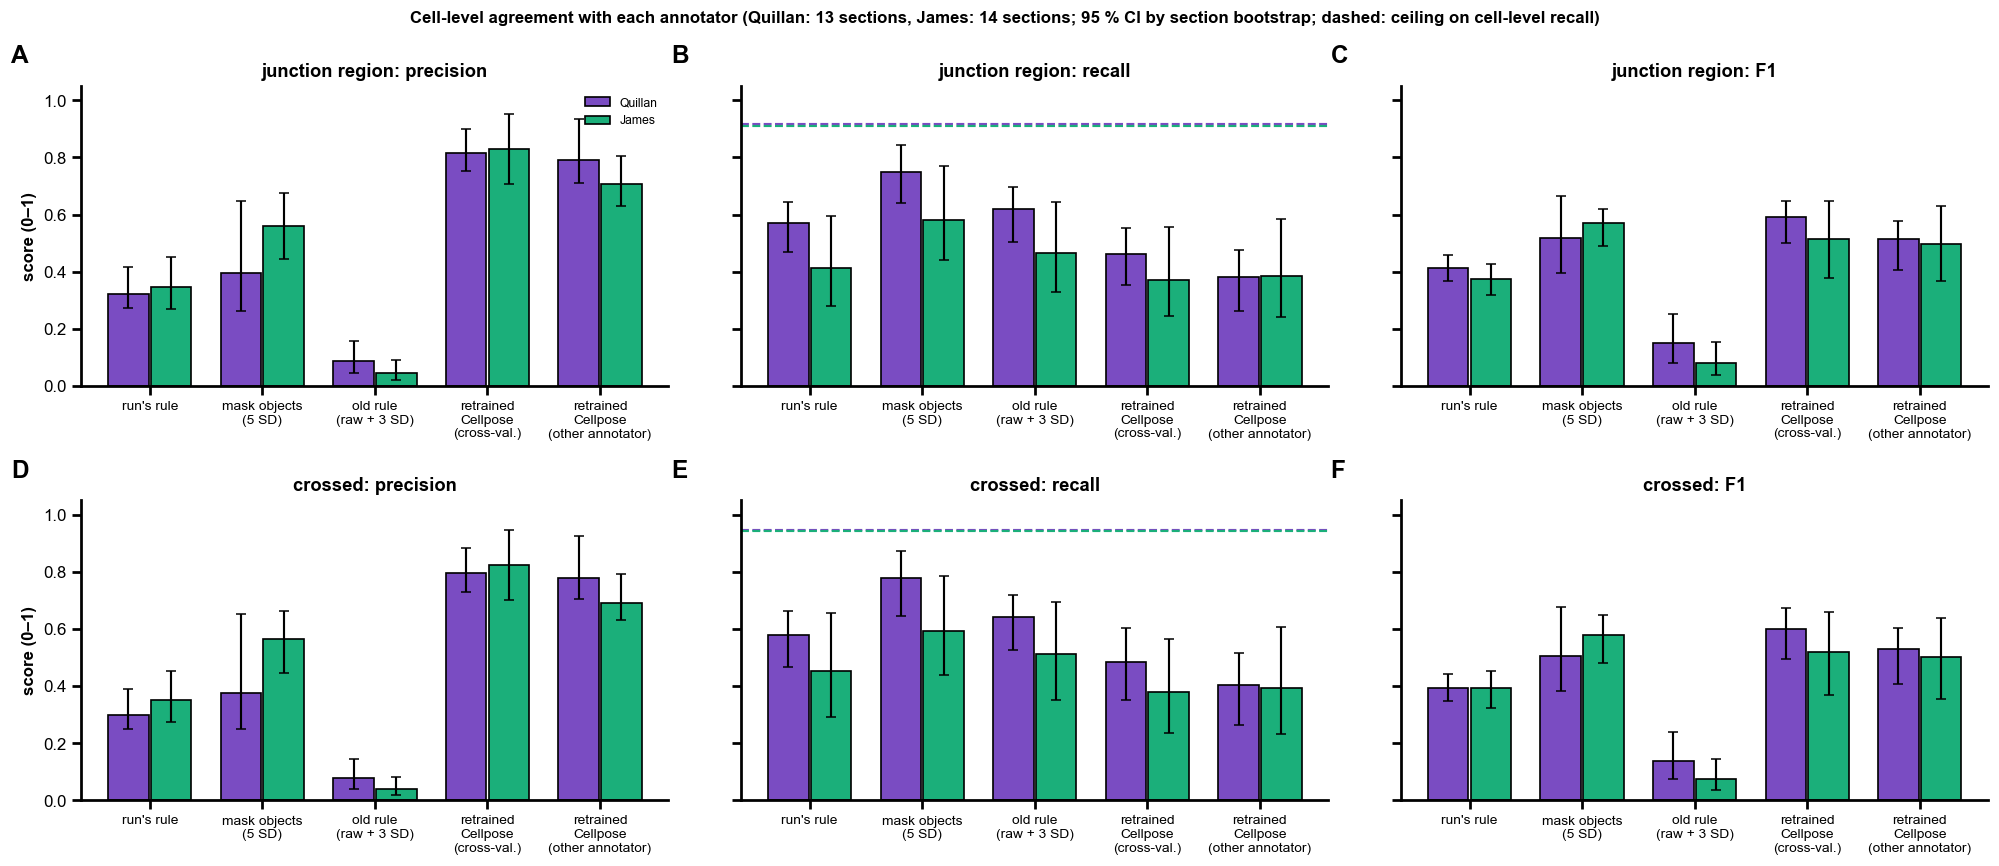

[PASS with caveat] 3c. Cell-level recall and F1 of the run's rule
    Quillan junction region: P 0.32, R 0.57 [0.47, 0.64], F1 0.41; Quillan crossed: P 0.30, R 0.58 [0.47, 0.66], F1 0.39; James junction region: P 0.35, R 0.41 [0.28, 0.60], F1 0.38; James crossed: P 0.35, R 0.45 [0.29, 0.66], F1 0.39; old rule F1 Quillan junction region 0.15, Quillan crossed 0.14, James junction region 0.08, James crossed 0.08


In [21]:
def tally_of(name, method, zone):
    d = DOTS[name]
    d_here = in_zone(d, zone)
    if method in OBJ_TABLES:
        o, hit = OBJ_TABLES[method][name], OBJ_HITS[method][name]
        o_here = in_zone(o, zone)
        held = np.isin(o["object"].to_numpy(), hit[hit > 0])
        return {"positives": int(o_here.sum()), "with a dot": int((o_here & held).sum()),
                "dots": int(d_here.sum()), "found": int((d_here & (hit > 0)).sum())}
    c = CELLS[name]
    here, clicked = in_zone(c, zone), c["clicked"].to_numpy(bool)
    called = c[method].to_numpy(bool) & here
    tp = int((called & clicked).sum())
    fn = int((clicked & here & ~called).sum()) + int((d_here & ~d["matched"].to_numpy(bool)).sum())
    return {"positives": int(called.sum()), "with a dot": tp, "dots": tp + fn, "found": tp}


tally = pd.DataFrame([{"name": n, "annotator": hand_sections.at[n, "annotator"], "zone": zone, "method": m,
                       **tally_of(n, m, zone)} for n in names for zone in ZONES for m in METHODS + CELL_EXTRA])


def precision(t):
    return t["with a dot"].sum() / max(t["positives"].sum(), 1)


def recall(t):
    return t["found"].sum() / max(t["dots"].sum(), 1)


def f1_of(t):
    p, r = precision(t), recall(t)
    return 2 * p * r / (p + r) if p + r > 0 else 0.0


prf_rows = []
for zone in ZONES:
    for method in METHODS + CELL_EXTRA:
        for who in [*WHO, "pooled"]:
            t = tally[(tally["zone"] == zone) & (tally["method"] == method)]
            t = t if who == "pooled" else t[t["annotator"] == who]
            row = {"zone": zone, "method": method, "annotator": who, "positives": int(t["positives"].sum()),
                   "dots": int(t["dots"].sum())}
            for label, fn in (("precision", precision), ("recall", recall), ("F1", f1_of)):
                est, lo, hi = boot_rows(t, fn)
                row.update({label: est, f"{label} low": lo, f"{label} high": hi})
            prf_rows.append(row)
prf = pd.DataFrame(prf_rows).set_index(["zone", "method", "annotator"])
display(prf.round(2))

fig, axes = plt.subplots(len(ZONES), 3, figsize=(2.6 * len(METHODS) + 5.2, 4.0 * len(ZONES)), sharey=True, squeeze=False)
for i, zone in enumerate(ZONES):
    for j, measure in enumerate(("precision", "recall", "F1")):
        ax = axes[i, j]
        for k, who in enumerate(WHO):
            for x, method in enumerate(METHODS):
                r = prf.loc[(zone, method, who)]
                ax.bar(x + (k - 0.5) * 0.38, r[measure], width=0.36, color=ANNOTATOR_COLOURS[who], **EDGE,
                       label=who if x == 0 else None)
                ax.errorbar(x + (k - 0.5) * 0.38, r[measure], yerr=[[r[measure] - r[f"{measure} low"]],
                                                                    [r[f"{measure} high"] - r[measure]]],
                            color="black", capsize=3, lw=1.4)
        if measure == "recall":
            for k, who in enumerate(WHO):
                ax.axhline(ceiling.at[(who, zone), "matched 1 to 1"], color=ANNOTATOR_COLOURS[who], ls="--", lw=1.4)
        ax.set_xticks(range(len(METHODS)), [tick_label(m) for m in METHODS], fontsize=9)
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{zone}: {measure}")
        if j == 0:
            ax.set_ylabel("score (0–1)")
axes[0, 0].legend(fontsize=8, loc="upper right")
n_txt = ", ".join(f"{who}: {int((hand_sections.annotator == who).sum())} sections" for who in WHO)
fig.suptitle(f"Cell-level agreement with each annotator ({n_txt}; 95 % CI by section bootstrap; "
             "dashed: ceiling on cell-level recall)", fontsize=11, fontweight="bold")
panel_letters(axes, x=-0.12)
fig.tight_layout()
save(fig, "pos_c_precision_recall")
plt.show()

rec = prf.xs(RUN_RULE, level="method").drop(index="pooled", level="annotator")
f1_run, f1_old = prf.xs(RUN_RULE, level="method"), prf.xs(OLD_RULE, level="method")
recall_ok = bool((rec["recall low"] >= 0.5).all())
f1_better = bool((f1_run["F1 low"] > f1_old["F1 high"]).all())
verdict("3c. Cell-level recall and F1 of the run's rule", "PASS" if recall_ok and f1_better else "PASS with caveat",
        "; ".join(f"{who} {z}: P {prf.at[(z, RUN_RULE, who), 'precision']:.2f}, "
                  f"R {prf.at[(z, RUN_RULE, who), 'recall']:.2f} [{prf.at[(z, RUN_RULE, who), 'recall low']:.2f}, "
                  f"{prf.at[(z, RUN_RULE, who), 'recall high']:.2f}], F1 {prf.at[(z, RUN_RULE, who), 'F1']:.2f}"
                  for who in WHO for z in ZONES)
        + "; old rule F1 " + ", ".join(f"{w} {z} {v:.2f}" for w in WHO for z in ZONES
                                        for v in [prf.at[(z, OLD_RULE, w), "F1"]]),
        "precision (a lower bound), recall, F1 per annotator with section-bootstrap CIs; object precision more lenient")

**Verdict 3c — PASS with caveat.** The run's rule: Quillan, region P 0.32, R 0.57 [0.47, 0.64], F1 0.41 [0.37, 0.46]; crossed P 0.30, R 0.58 [0.47, 0.66], F1 0.39. James, region P 0.35, R 0.41 [0.28, 0.60], F1 0.38 [0.32, 0.43]; crossed P 0.35, R 0.45 [0.29, 0.66], F1 0.39. F1 is the same against both annotators and clearly above the old rule's (0.08–0.15, CIs apart), but recall against James has a lower CI bound under 0.5, so the pre-specified bar is not met. The mask objects reach F1 0.52–0.58 (recall 0.58–0.78) — but their precision is more lenient (one object holding several dots counts once). **Caveats to state:** precision is a lower bound (annotators miss cells, so 560 rule positives in Quillan's regions against 318 dots partly reflects cells he did not mark); recall is the trustworthy number; about half the hand-marked cells are below the rule's threshold, so the rule picks the brightest labelled cells. (The retrained Cellpose's rows: 3e.)

### 3d. Do the two annotators agree with each other?

**Limitation, stated plainly:** the two annotators counted **different sections** (13 and 14, none in common), so their inter-rater agreement — the benchmark a method should be held to — cannot be measured here. What can be checked:

1. **Counting style.** Per section, dots per mm of junction in the region, crossed dots per mm, and the share of the dots within 300 µm of the line (beside it) that lie on the far side (crossed). The same numbers from the run's rule on the same sections show whether a difference is the annotator or his sections (and the ratio annotator ÷ run's rule cancels the sections' own label density). Compared with Mann–Whitney; CIs of the medians by section bootstrap.
2. **Is each method's bias the same against both?** On the per-section log₂ ratio of 3b: per method and zone, James's bias less Quillan's (as ×, bootstrap CI resampling sections within each annotator; Welch p), and one linear mixed model per zone, log₂ ratio ~ method × annotator + (1 | section), whose interaction terms ask whether the annotator effect differs between methods (Wald χ²).

**Pre-specified:** PASS with caveat at best (no shared sections); the caveat is lifted only by a re-count of shared sections. "Consistent" when no method's bias differs between annotators by more than 1.5× (CI) and the interaction is not significant.

,Quillan median,Quillan low,Quillan high,James median,James low,James high,Mann–Whitney p
measure,,,,,,,
"dots per mm, region",19.951,10.866,26.866,10.614,5.091,21.092,0.126
crossed dots per mm,16.090,9.464,21.037,8.651,4.364,18.489,0.126
share crossed (dots ≤ 300 µm),0.500,0.448,0.633,0.156,0.130,0.300,0.000
"run's rule per mm, region",21.379,11.681,44.329,10.010,6.247,23.109,0.152
run's rule share crossed,0.212,0.144,0.243,0.143,0.075,0.242,0.467
"dots ÷ run's rule, region",0.656,0.463,1.562,0.900,0.600,1.286,0.645


bias vs Quillan ×  bias vs James ×  James ÷ Quillan ×    low   high  Welch p
zone            method                                                                                                            
junction region run's rule                                        1.279            1.017              0.795  0.419  1.422    0.489
                mask objects (5 SD)                               1.210            0.974              0.805  0.485  1.298    0.417
                old rule (raw + 3 SD)                             5.356            6.658              1.243  0.474  3.412    0.674
                retrained Cellpose (cross-val.)                   0.416            0.481              1.158  0.751  1.801    0.529
                retrained Cellpose (other annotator)              0.291            0.489              1.681  0.959  2.965    0.082
crossed         run's rule                                        1.360            1.050              0.772  0.407  1.419    0.433
                mask objects (5 SD)                               1.244            0.959              0.771  0.469  1.245    0.314
                old rule (raw + 3 SD)                             5.977            6.873              1.150  0.399  3.306    0.799
                retrained Cellpose (cross-val.)                   0.441            0.498              1.131  0.719  1.764    0.608
                retrained Cellpose (other annotator)              0.309            0.494              1.597  0.923  2.835    0.134

method × annotator, the three planned methods:


,annotator effect on the run's rule ×,low,high,p annotator,interaction Wald χ²,df,p interaction,section SD (log₂)
junction region,0.795,0.376,1.683,0.549,1.508,2.0,0.470,0.921
crossed,0.772,0.356,1.674,0.512,1.097,2.0,0.578,0.910


method × annotator, with the retrained Cellpose:


,annotator effect on the run's rule ×,low,high,p annotator,interaction Wald χ²,df,p interaction,section SD (log₂)
junction region,0.795,0.409,1.546,0.499,5.611,4.0,0.230,0.783
crossed,0.772,0.388,1.535,0.460,4.768,4.0,0.312,0.781


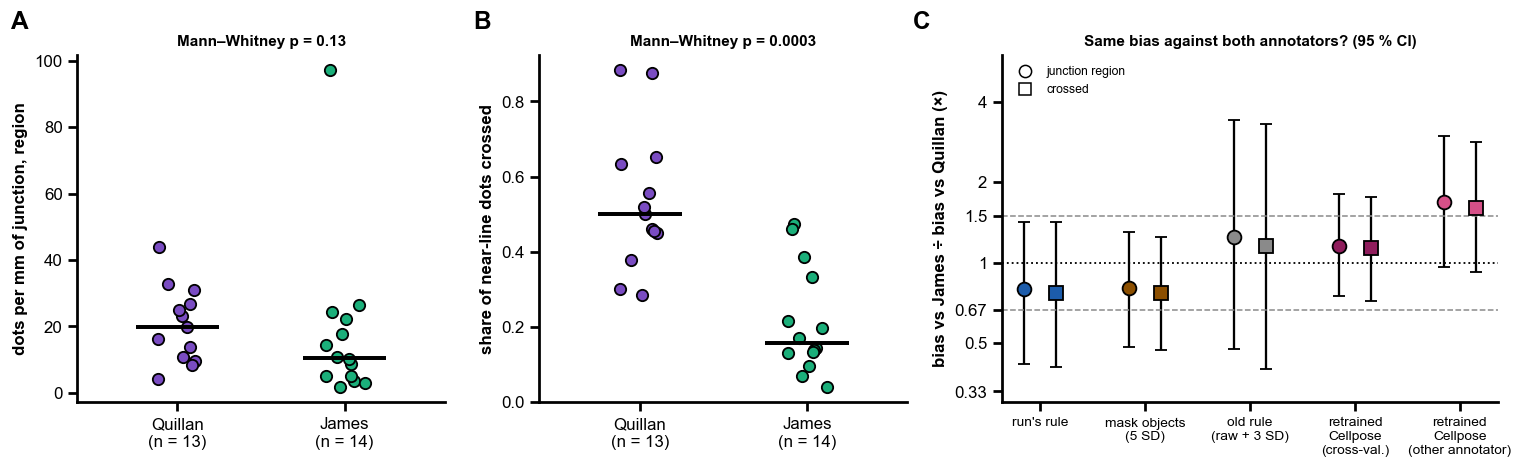

[PASS with caveat] 3d. The methods' bias is the same against both annotators
    no shared sections (inter-rater agreement not measurable); run's rule James ÷ Quillan junction region: 0.80× [0.42, 1.42]; run's rule James ÷ Quillan crossed: 0.77× [0.41, 1.42]; method × annotator interaction p junction region 0.47, crossed 0.58; not shown consistent by the pre-specified rule


In [22]:
style_rows = []
for n in names:
    d, c, length = DOTS[n], CELLS[n], hand_sections.at[n, "length (mm)"]
    near_d = d["beside"].to_numpy(bool) & (np.abs(d["away"].to_numpy(float)) <= NEAR_UM)
    pos = c[RUN_RULE].to_numpy(bool)
    near_c = c["beside"].to_numpy(bool) & (np.abs(c["away"].to_numpy(float)) <= NEAR_UM) & pos
    style_rows.append({
        "name": n, "annotator": hand_sections.at[n, "annotator"], "Genotype": hand_sections.at[n, "Genotype"],
        "dots per mm, region": in_zone(d, "junction region").sum() / length,
        "crossed dots per mm": in_zone(d, "crossed").sum() / length,
        "share crossed (dots ≤ 300 µm)": in_zone(d, "crossed")[near_d].mean() if near_d.any() else np.nan,
        "run's rule per mm, region": (pos & in_zone(c, "junction region")).sum() / length,
        "run's rule share crossed": in_zone(c, "crossed")[near_c].mean() if near_c.any() else np.nan})
style = pd.DataFrame(style_rows).set_index("name")
style["dots ÷ run's rule, region"] = (style["dots per mm, region"] + 1 / style.index.map(hand_sections["length (mm)"])) / (
    style["run's rule per mm, region"] + 1 / style.index.map(hand_sections["length (mm)"]))
STYLE = ["dots per mm, region", "crossed dots per mm", "share crossed (dots ≤ 300 µm)", "run's rule per mm, region",
         "run's rule share crossed", "dots ÷ run's rule, region"]
style_table = []
for measure in STYLE:
    row = {"measure": measure}
    for who in WHO:
        f = style[style["annotator"] == who][[measure]].dropna()
        est, lo, hi = boot_rows(f, lambda g: g[measure].median())
        row.update({f"{who} median": est, f"{who} low": lo, f"{who} high": hi})
    a, b = (style.loc[style["annotator"] == w, measure].dropna() for w in WHO)
    row["Mann–Whitney p"] = stats.mannwhitneyu(a, b).pvalue
    style_table.append(row)
style_table = pd.DataFrame(style_table).set_index("measure")
display(style_table.round(3))

# Each method's bias against James less against Quillan, per zone.
diff_rows = []
rng = np.random.default_rng(SEED)
for zone in ZONES:
    f = counts[counts["zone"] == zone]
    for method in METHODS:
        q, j = (log_ratio(f[f["annotator"] == w], method) for w in ("Quillan", "James"))
        draws = [rng.choice(j, len(j)).mean() - rng.choice(q, len(q)).mean() for _ in range(N_BOOT)]
        lo, hi = np.percentile(draws, [2.5, 97.5])
        diff_rows.append({"zone": zone, "method": method, "bias vs Quillan ×": 2 ** q.mean(), "bias vs James ×": 2 ** j.mean(),
                          "James ÷ Quillan ×": 2 ** (j.mean() - q.mean()), "low": 2 ** lo, "high": 2 ** hi,
                          "Welch p": stats.ttest_ind(j, q, equal_var=False).pvalue})
bias_diff = pd.DataFrame(diff_rows).set_index(["zone", "method"])
display(bias_diff.round(3))

def interaction(methods):
    """Per zone: log₂ ratio ~ method × annotator + (1 | section); the interaction's Wald χ² over all its terms."""
    long = counts.melt(id_vars=["name", "annotator", "zone", "hand"], value_vars=methods, var_name="method",
                       value_name="count")
    long["lr"] = np.log2((long["count"] + 1) / (long["hand"] + 1))
    long["method"] = pd.Categorical(long["method"], methods)
    out = {}
    for zone in ZONES:
        g = long[long["zone"] == zone]
        fit = smf.mixedlm("lr ~ C(method) * C(annotator, Treatment('Quillan'))", g, groups=g["name"]).fit(reml=True)
        terms = [t for t in fit.params.index if ":" in t]
        b, V = fit.params[terms].to_numpy(), fit.cov_params().loc[terms, terms].to_numpy()
        wald = float(b @ np.linalg.solve(V, b))
        annot = "C(annotator, Treatment('Quillan'))[T.James]"
        out[zone] = {"annotator effect on the run's rule ×": 2 ** fit.params[annot],
                     "low": 2 ** fit.conf_int().loc[annot, 0], "high": 2 ** fit.conf_int().loc[annot, 1],
                     "p annotator": fit.pvalues[annot], "interaction Wald χ²": wald, "df": len(terms),
                     "p interaction": stats.chi2.sf(wald, len(terms)),
                     "section SD (log₂)": float(np.sqrt(fit.cov_re.iloc[0, 0]))}
    return pd.DataFrame(out).T


mixed = interaction(BASE_METHODS)          # the pre-specified test, on the methods it was planned with
print("method × annotator, the three planned methods:")
display(mixed.round(3))
if METHODS != BASE_METHODS:                # and with the retrained Cellpose added (its own reading in 3e)
    mixed_all = interaction(METHODS)
    print("method × annotator, with the retrained Cellpose:")
    display(mixed_all.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.35]})
for ax, measure, label in ((axes[0], "dots per mm, region", "dots per mm of junction, region"),
                           (axes[1], "share crossed (dots ≤ 300 µm)", "share of near-line dots crossed")):
    jitter = np.random.default_rng(SEED)
    for k, who in enumerate(WHO):
        v = style.loc[style["annotator"] == who, measure].dropna()
        ax.scatter(k + jitter.uniform(-0.12, 0.12, len(v)), v, s=55, color=ANNOTATOR_COLOURS[who], edgecolor="black",
                   linewidth=1.2, zorder=3)
        ax.hlines(v.median(), k - 0.25, k + 0.25, color="black", lw=2.6, zorder=4)
    ax.set_xticks(range(len(WHO)), [f"{w}\n(n = {int((hand_sections.annotator == w).sum())})" for w in WHO])
    ax.set_xlim(-0.6, len(WHO) - 0.4)
    ax.set_ylabel(label)
    ax.set_title(f"Mann–Whitney p = {style_table.at[measure, 'Mann–Whitney p']:.2g}", fontsize=10)
ax = axes[2]
for i, zone in enumerate(ZONES):
    for x, method in enumerate(METHODS):
        r = bias_diff.loc[(zone, method)]
        pos = x + (i - 0.5) * 0.3
        ax.errorbar(pos, r["James ÷ Quillan ×"], yerr=[[r["James ÷ Quillan ×"] - r["low"]], [r["high"] - r["James ÷ Quillan ×"]]],
                    fmt="o" if i == 0 else "s", ms=9, color=METHOD_COLOURS[method], mec="black", mew=1.2, ecolor="black",
                    capsize=4, lw=1.5, label=zone if x == 0 else None)
ax.axhline(1, color="black", lw=1.2, ls=":")
for lim in (1 / 1.5, 1.5):
    ax.axhline(lim, color=GREY, lw=1, ls="--")
ax.set_yscale("log", base=2)
ax.set_ylim(0.3, 6)
ax.set_yticks([0.33, 0.5, 2 / 3, 1, 1.5, 2, 4], ["0.33", "0.5", "0.67", "1", "1.5", "2", "4"])
ax.minorticks_off()
ax.set_xticks(range(len(METHODS)), [tick_label(m) for m in METHODS], fontsize=9)
ax.set_ylabel("bias vs James ÷ bias vs Quillan (×)")
ax.set_title("Same bias against both annotators? (95 % CI)", fontsize=10)
handles = [mpl.lines.Line2D([], [], marker=mk, ls="", mfc="white", mec="black", ms=8, label=z)
           for mk, z in zip("os", ZONES)]
ax.legend(handles=handles, fontsize=8, loc="upper left")
panel_letters(axes)
fig.tight_layout()
save(fig, "pos_d_annotators")
plt.show()

worst = bias_diff["James ÷ Quillan ×"].apply(lambda v: max(v, 1 / v))
planned = bias_diff.loc[(slice(None), BASE_METHODS), :]
consistent = bool(((planned["low"] >= 1 / 1.5) & (planned["high"] <= 1.5)).all() and (mixed["p interaction"] >= 0.05).all())
verdict("3d. The methods' bias is the same against both annotators", "PASS with caveat",
        f"no shared sections (inter-rater agreement not measurable); "
        + "; ".join(f"run's rule James ÷ Quillan {z}: {bias_diff.at[(z, RUN_RULE), 'James ÷ Quillan ×']:.2f}× "
                    f"[{bias_diff.at[(z, RUN_RULE), 'low']:.2f}, {bias_diff.at[(z, RUN_RULE), 'high']:.2f}]"
                    for z in ZONES)
        + "; method × annotator interaction p " + ", ".join(f"{z} {p:.2f}" for z, p in mixed["p interaction"].items())
        + f"; {'consistent' if consistent else 'not shown consistent'} by the pre-specified rule",
        "the limitation (different sections), each annotator's style, and the annotator × method test; "
        "a re-count of shared sections by both is the missing benchmark")

**Verdict 3d — PASS with caveat (limitation).** The two annotators counted **different sections**, so inter-rater agreement — the benchmark for 3b — is not measured; a re-count of shared sections by both is the missing piece. **Counting style:** similar density in the region (median 20 [11, 27] vs 11 [5, 21] dots per mm, p 0.13; and relative to the run's rule on the same sections 0.66× vs 0.90×, p 0.65), but a very different emphasis: of the dots within 300 µm of the line, **50 % [45, 63] of Quillan's are on the crossed side, against 16 % [13, 30] of James's** (p 0.0003), while the run's rule finds the same share on both sets of sections (21 % vs 14 %, p 0.47) — Quillan concentrated on the cells that crossed, James counted the whole section. Note also that all 13 of Quillan's sections have a hand-drawn region, against 3 of James's 14. **Bias against each:** every method counts relatively less against James than against Quillan by about the same factor (run's rule 0.80× [0.42, 1.42] region, 0.77× [0.41, 1.41] crossed; mask objects 0.81× and 0.77×); the method × annotator interaction is not significant (mixed model, p 0.47 region, 0.58 crossed) — but the CIs are too wide (± 1.5× not excluded) to call the biases equal. **Report:** as a limitation, with the style difference, and that the methods' ranking is the same against both annotators. The pre-specified interaction test is on the three planned methods; the one with the retrained Cellpose added is shown beside it and read in 3e.

### 3e. A Cellpose model fine-tuned on the annotators' clicks counts like them

**Claim.** Fine-tuned on the annotators' own dots, Cellpose on the AF488 channel counts the AF488+ cells of a section like the annotators do, finds the cells they marked better than the run's rule, and does so for an annotator whose clicks it never saw.

**How the model was made** (its own training script; `run_analysis_20261028\cellpose_retrained\`: training sets, models, `folds.json`, training curves, `settings.json`). A dot is a point, not an outline, so the training masks are **grown from the dots** on the AF488 plane, one cell outline per dot; Cellpose (cpsam) is fine-tuned on those with the repo's training engine (`microscopy_viewer.cellpose_training`). Two variants:

- **cross-validated** — the 27 annotated sections are split in two **by section**; each half is predicted by the model trained on the other half (2-fold cross-validation);
- **trained on the other annotator** — James's 14 sections are predicted by a model trained on Quillan's 13 sections and dots only, and Quillan's by one trained on James's only. This is the **generalisation test**: the model never saw the scoring annotator's clicks, nor his sections, so it asks whether what it learned from one person holds for another — what a reader of the paper needs to know before trusting it on sections nobody counted.

**Only held-out predictions are scored.** Every section here is counted by a model that did **not** train on it; the fold file is checked below (no section in both the training and the test set of one model, every section tested once). A model scored on its own training sections would measure memory, not counting.

**Pre-specified (set before the model's results were seen).** For the cross-validated model, pooled over the 27 sections:

1. **Counts** — the bar of 3b: in both zones, the ratio-scale bias CI within 0.67–1.5× and the CCC's lower CI bound ≥ 0.5 (its objects counted by their centroids, as the mask objects);
2. **Cells** — its F1 above the run's rule's in both zones, at the **cell level** (a nucleus counts as called when the model's objects cover ≥ 25 % of its grown region; TP, FP and FN exactly as for the run's rule, so both precisions are of the same strict kind): the paired section-bootstrap 95 % CI of F1(model) − F1(run's rule) lies above 0. The object-level F1 is shown beside it, but its precision is the **lenient object kind** of 3c (one object holding several dots counts once), so it is not used for the verdict.

PASS when 1 and 2 hold; PASS with caveat when one of them does; FAIL when neither. **Generalisation:** the same two criteria for the model trained on the other annotator, pooled over the 27 sections (each counted by the model trained on the other person); each annotator on his own is shown too (13–14 sections: read the CIs).

held-out check: 4 trainings in folds.json; sections both trained on and tested by one model: 0 (none); Cellpose AF488 · retrained (cross-validated): 27 of 27 sections tested once, 0 never, 0 more than once; Cellpose AF488 · retrained on the other annotator: 27 of 27 sections tested once, 0 never, 0 more than once


sections   CCC  CCC low  CCC high  bias ×  bias × low  bias × high  LoA × low  LoA × high  counts pass  precision (cells)  recall (cells)  F1 (cells)  \
model                                scored on zone                                                                                                                                                                     
retrained Cellpose (cross-val.)      pooled    junction region        27  0.52     0.26      0.74    0.45        0.36         0.56       0.14        1.44        False               0.28            0.39        0.33   
                                               crossed                27  0.50     0.23      0.69    0.47        0.37         0.59       0.14        1.54        False               0.27            0.41        0.32   
                                     Quillan   junction region        13  0.55     0.21      0.76    0.42        0.31         0.54       0.14        1.21        False               0.27            0.41        0.33   
                                               crossed                13  0.50     0.22      0.70    0.44        0.32         0.59       0.14        1.41        False               0.26            0.43        0.32   
                                     James     junction region        14  0.30     0.17      0.65    0.48        0.35         0.67       0.13        1.72        False               0.31            0.36        0.33   
                                               crossed                14  0.23     0.07      0.66    0.50        0.36         0.69       0.14        1.73        False               0.30            0.37        0.33   
retrained Cellpose (other annotator) pooled    junction region        27  0.49     0.26      0.65    0.38        0.28         0.51       0.08        1.75        False               0.31            0.34        0.32   
                                               crossed                27  0.50     0.28      0.64    0.39        0.29         0.53       0.08        1.91        False               0.30            0.36        0.33   
                                     Quillan   junction region        13  0.47     0.16      0.66    0.29        0.20         0.42       0.07        1.25        False               0.28            0.34        0.30   
                                               crossed                13  0.47     0.19      0.62    0.31        0.20         0.46       0.07        1.46        False               0.27            0.36        0.31   
                                     James     junction region        14  0.45     0.25      0.73    0.49        0.33         0.71       0.11        2.10        False               0.39            0.34        0.36   
                                               crossed                14  0.47     0.24      0.75    0.49        0.33         0.72       0.11        2.26        False               0.39            0.36        0.37   

                                                                F1 (cells) low  F1 (cells) high  F1 (objects, lenient)  F1 run's rule  F1 gain  F1 gain low  F1 gain high  F1 better  
model                                scored on zone                                                                                                                                   
retrained Cellpose (cross-val.)      pooled    junction region            0.29             0.36                   0.57           0.40    -0.07        -0.11         -0.04      False  
                                               crossed                    0.28             0.36                   0.58           0.39    -0.07        -0.11         -0.04      False  
                                     Quillan   junction region            0.28             0.37                   0.59           0.41    -0.09        -0.14         -0.05      False  
                                               crossed                    0.27             0.37               

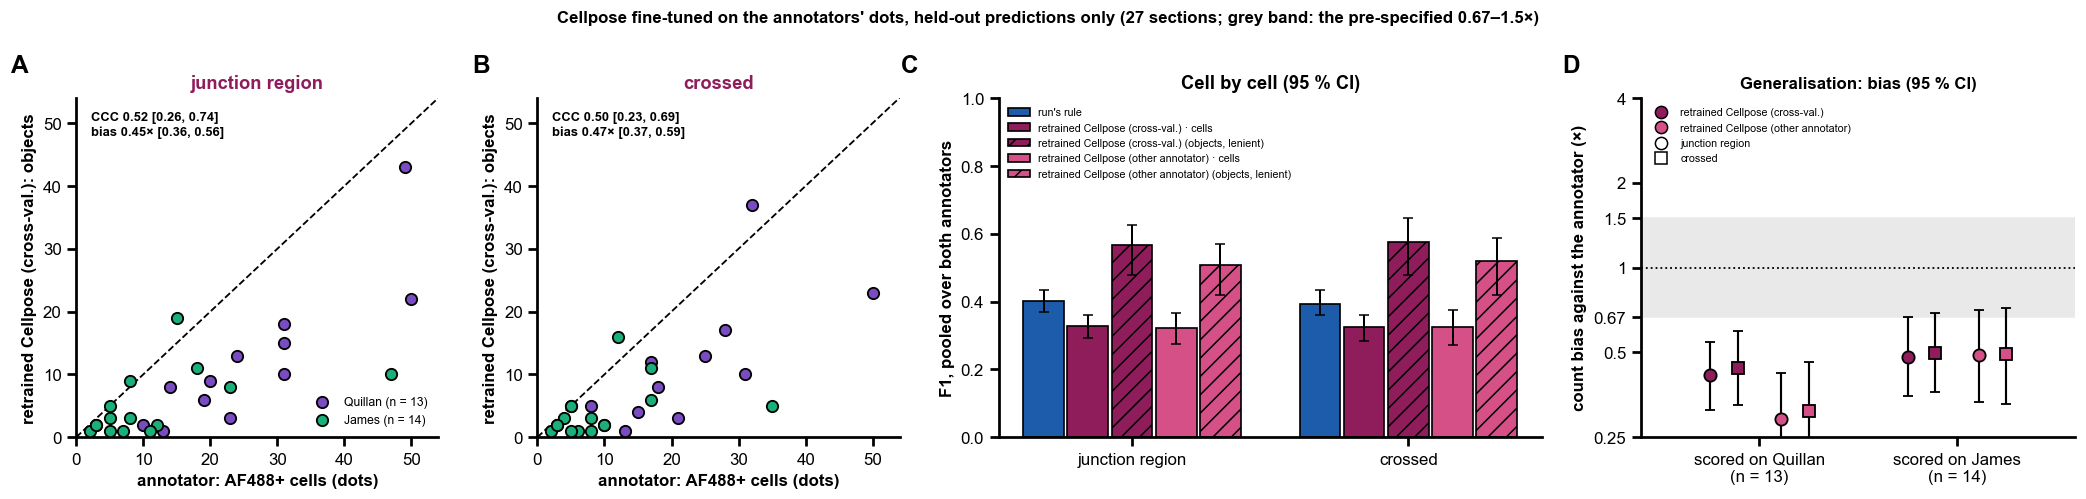

[FAIL] 3e. A Cellpose model fine-tuned on the annotators' clicks counts like them (cross-validated)
    counts fail, cell F1 not shown better than the run's rule; junction region: CCC 0.52 [0.26, 0.74], bias 0.45× [0.36, 0.56], LoA 0.14–1.44×, cell F1 0.33 vs run's rule 0.40 (gain -0.07 [-0.11, -0.04]), object F1 (lenient) 0.57; crossed: CCC 0.50 [0.23, 0.69], bias 0.47× [0.37, 0.59], LoA 0.14–1.54×, cell F1 0.32 vs run's rule 0.39 (gain -0.07 [-0.11, -0.04]), object F1 (lenient) 0.58
[FAIL] 3e. … and generalises to an annotator whose clicks it never saw (trained on the other)
    counts fail, cell F1 not shown better; junction region: CCC 0.49 [0.26, 0.65], bias 0.38× [0.28, 0.51], LoA 0.08–1.75×, cell F1 0.32 vs run's rule 0.40 (gain -0.08 [-0.12, -0.04]), object F1 (lenient) 0.51; crossed: CCC 0.50 [0.28, 0.64], bias 0.39× [0.29, 0.53], LoA 0.08–1.91×, cell F1 0.33 vs run's rule 0.39 (gain -0.07 [-0.12, -0.02]), object F1 (lenient) 0.52; scored on Quillan alone: FAIL; scored on Jame

In [23]:
RUN_F1 = "F1 run's rule"
RT_TITLE = "3e. A Cellpose model fine-tuned on the annotators' clicks counts like them"
if RETRAINED_MISSING:
    print("3e not evaluated yet — " + "; ".join(RETRAINED_MISSING))
    verdict(RT_TITLE, "not evaluated", "the retrained Cellpose's files are missing: " + "; ".join(RETRAINED_MISSING),
            "re-run the notebook once cellpose488_retrained is written for all 27 sections")
else:
    print("held-out check:", fold_check())

    def f1_gain(method, zone, who="pooled", n=N_BOOT, seed=SEED):
        """F1(method) − F1(run's rule) in *zone*, and its paired 95 % CI: the same sections drawn for both."""
        t = tally[tally["zone"] == zone]
        t = t if who == "pooled" else t[t["annotator"] == who]
        a, b = (t[t["method"] == m].set_index("name") for m in (method, RUN_RULE))
        keys = a.index.to_numpy()
        rng = np.random.default_rng(seed)
        draws = []
        for _ in range(n):
            pick = keys[rng.integers(0, len(keys), len(keys))]
            draws.append(f1_of(a.loc[pick]) - f1_of(b.loc[pick]))
        return f1_of(a) - f1_of(b), *np.percentile(draws, [2.5, 97.5])

    rt_rows = []
    for method in RETRAINED_VARIANTS:
        for who in ["pooled", *WHO]:
            for zone in ZONES:
                a, gain = agreement.loc[(zone, method, who)], f1_gain(f"{method} · cells", zone, who)
                cell, obj, run = (prf.loc[(zone, m, who)] for m in (f"{method} · cells", method, RUN_RULE))
                rt_rows.append({
                    "model": method, "scored on": who, "zone": zone, "sections": int(a["sections"]),
                    "CCC": a["CCC"], "CCC low": a["CCC low"], "CCC high": a["CCC high"],
                    "bias ×": a["bias ×"], "bias × low": a["bias × low"], "bias × high": a["bias × high"],
                    "LoA × low": a["LoA × low"], "LoA × high": a["LoA × high"],
                    "counts pass": bool(a["bias × low"] >= 0.67 and a["bias × high"] <= 1.5 and a["CCC low"] >= 0.5),
                    "precision (cells)": cell["precision"], "recall (cells)": cell["recall"],
                    "F1 (cells)": cell["F1"], "F1 (cells) low": cell["F1 low"], "F1 (cells) high": cell["F1 high"],
                    "F1 (objects, lenient)": obj["F1"], RUN_F1: run["F1"],
                    "F1 gain": gain[0], "F1 gain low": gain[1], "F1 gain high": gain[2], "F1 better": bool(gain[1] > 0)})
    retrained = pd.DataFrame(rt_rows).set_index(["model", "scored on", "zone"])
    display(retrained.round(2))

    # ------------------------------------------------------------ Figure: counts, F1 and the generalisation test
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.5, 1.2]})
    for ax, zone in zip(axes[:2], ZONES):
        f = counts[counts["zone"] == zone]
        top = max(f["hand"].max(), f[RT_CV].max(), 1) * 1.08
        ax.plot([0, top], [0, top], color="black", ls="--", lw=1.2, zorder=1)
        for who in WHO:
            g = f[f["annotator"] == who]
            ax.scatter(g["hand"], g[RT_CV], s=55, color=ANNOTATOR_COLOURS[who], edgecolor="black", linewidth=1.2,
                       zorder=3, label=f"{who} (n = {len(g)})")
        r = retrained.loc[(RT_CV, "pooled", zone)]
        ax.text(0.04, 0.96, f"CCC {r['CCC']:.2f} [{r['CCC low']:.2f}, {r['CCC high']:.2f}]\n"
                            f"bias {r['bias ×']:.2f}× [{r['bias × low']:.2f}, {r['bias × high']:.2f}]",
                transform=ax.transAxes, va="top", fontsize=8.5, fontweight="bold", zorder=5,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
        ax.set_xlim(0, top)
        ax.set_ylim(0, top)
        ax.set_xlabel("annotator: AF488+ cells (dots)")
        ax.set_ylabel("retrained Cellpose (cross-val.): objects")
        ax.set_title(f"{zone}", color=METHOD_COLOURS[RT_CV])
    axes[0].legend(fontsize=8, loc="lower right")
    ax = axes[2]
    bars = [(RUN_RULE, RUN_RULE, None), (f"{RT_CV} · cells", RT_CV, None), (RT_CV, RT_CV, "//"),
            (f"{RT_X} · cells", RT_X, None), (RT_X, RT_X, "//")]
    width = 0.8 / len(bars)
    for i, zone in enumerate(ZONES):
        for k, (method, colour_of, hatch) in enumerate(bars):
            r = prf.loc[(zone, method, "pooled")]
            x = i + (k - (len(bars) - 1) / 2) * width
            ax.bar(x, r["F1"], width=width * 0.92, color=METHOD_COLOURS[colour_of], hatch=hatch, **EDGE,
                   label=(f"{method}" + (" (objects, lenient)" if hatch else "")) if i == 0 else None)
            ax.errorbar(x, r["F1"], yerr=[[r["F1"] - r["F1 low"]], [r["F1 high"] - r["F1"]]], color="black",
                        capsize=3, lw=1.3)
    ax.set_xticks(range(len(ZONES)), ZONES)
    ax.set_ylim(0, 1.0)
    ax.set_ylabel("F1, pooled over both annotators")
    ax.set_title("Cell by cell (95 % CI)")
    ax.legend(fontsize=7, loc="upper left", ncol=1)
    ax = axes[3]
    ax.axhspan(0.67, 1.5, color="#e9e9e9", zorder=0)
    ax.axhline(1, color="black", lw=1.2, ls=":")
    for k, who in enumerate(WHO):
        for j, method in enumerate(RETRAINED_VARIANTS):
            for i, zone in enumerate(ZONES):
                r = retrained.loc[(method, who, zone)]
                x = k + (j - 0.5) * 0.36 + (i - 0.5) * 0.14
                ax.errorbar(x, r["bias ×"], yerr=[[r["bias ×"] - r["bias × low"]], [r["bias × high"] - r["bias ×"]]],
                            fmt="o" if i == 0 else "s", ms=8, color=METHOD_COLOURS[method], mec="black", mew=1.2,
                            ecolor="black", capsize=3, lw=1.4)
    ax.set_yscale("log", base=2)
    ax.set_ylim(0.25, 4)
    ax.set_yticks([0.25, 0.5, 2 / 3, 1, 1.5, 2, 4], ["0.25", "0.5", "0.67", "1", "1.5", "2", "4"])
    ax.minorticks_off()
    ax.set_xticks(range(len(WHO)), [f"scored on {w}\n(n = {int((hand_sections.annotator == w).sum())})" for w in WHO])
    ax.set_xlim(-0.6, len(WHO) - 0.4)
    ax.set_ylabel("count bias against the annotator (×)")
    ax.set_title("Generalisation: bias (95 % CI)", fontsize=11)
    handles = [mpl.lines.Line2D([], [], marker="o", ls="", mfc=METHOD_COLOURS[m], mec="black", ms=8, label=m)
               for m in RETRAINED_VARIANTS]
    handles += [mpl.lines.Line2D([], [], marker=mk, ls="", mfc="white", mec="black", ms=8, label=z) for mk, z in zip("os", ZONES)]
    ax.legend(handles=handles, fontsize=7, loc="upper left")
    panel_letters(axes)
    fig.suptitle(f"Cellpose fine-tuned on the annotators' dots, held-out predictions only ({len(names)} sections; "
                 "grey band: the pre-specified 0.67–1.5×)", fontsize=11, fontweight="bold")
    fig.tight_layout()
    save(fig, "pos_e_retrained")
    plt.show()

    def judged(method, who="pooled"):
        """The two pre-specified criteria for *method* scored on *who*, and the verdict they give."""
        r = retrained.loc[(method, who)]
        counts_ok, f1_ok = bool(r["counts pass"].all()), bool(r["F1 better"].all())
        return counts_ok, f1_ok, "PASS" if counts_ok and f1_ok else "PASS with caveat" if counts_ok or f1_ok else "FAIL"

    def evidence(method, who="pooled"):
        r = retrained.loc[(method, who)]
        return "; ".join(f"{z}: CCC {r.at[z, 'CCC']:.2f} [{r.at[z, 'CCC low']:.2f}, {r.at[z, 'CCC high']:.2f}], "
                         f"bias {r.at[z, 'bias ×']:.2f}× [{r.at[z, 'bias × low']:.2f}, {r.at[z, 'bias × high']:.2f}], "
                         f"LoA {r.at[z, 'LoA × low']:.2f}–{r.at[z, 'LoA × high']:.2f}×, cell F1 {r.at[z, 'F1 (cells)']:.2f} "
                         f"vs run's rule {r.at[z, RUN_F1]:.2f} (gain {r.at[z, 'F1 gain']:+.2f} "
                         f"[{r.at[z, 'F1 gain low']:+.2f}, {r.at[z, 'F1 gain high']:+.2f}]), "
                         f"object F1 (lenient) {r.at[z, 'F1 (objects, lenient)']:.2f}" for z in ZONES)

    counts_cv, f1_cv, result_cv = judged(RT_CV)
    verdict(RT_TITLE + " (cross-validated)", result_cv,
            f"counts {'pass' if counts_cv else 'fail'}, cell F1 {'better' if f1_cv else 'not shown better'} than the "
            f"run's rule; " + evidence(RT_CV),
            "pooled CCC, ratio-scale bias and LoA, and the paired F1 gain over the run's rule, per zone, section-bootstrap "
            "CIs; held-out predictions only (2-fold cross-validation by section)")
    counts_x, f1_x, result_x = judged(RT_X)
    per_who = "; ".join(f"scored on {w} alone: {judged(RT_X, w)[2]}" for w in WHO)
    verdict("3e. … and generalises to an annotator whose clicks it never saw (trained on the other)", result_x,
            f"counts {'pass' if counts_x else 'fail'}, cell F1 {'better' if f1_x else 'not shown better'}; "
            + evidence(RT_X) + f"; {per_who}",
            "the cross-annotator result is the generalisation claim: report it beside the cross-validated one")

**Verdict 3e — FAIL, both variants (5 Nov 2026).** The fine-tuned model is **precise but finds only about half the cells**, so it undercounts. Cross-validated (each section scored by the fold model that never saw it): junction region CCC 0.52 [0.26, 0.74], bias **0.45×** [0.36, 0.56], LoA 0.14–1.44×; crossed CCC 0.50 [0.23, 0.69], bias 0.47× [0.37, 0.59]. Its cell-level F1 is *lower* than the run's rule's (0.33 vs 0.40 in the region, paired gain −0.07 [−0.11, −0.04]; crossed 0.32 vs 0.39). Its object-level F1 (0.57–0.58) and precision (0.72–0.93) are high, but that precision is the lenient kind. Trained on one annotator and scored on the other (the generalisation test): worse — bias 0.38–0.39×, CCC 0.49–0.50, cell F1 0.32–0.33 — and it fails against each annotator separately. A plausible reason: the training masks were grown from dots, unclicked labelled cells were taught as background, and 27 sections (1 011 training tiles in all) are few; the model learned to call only the brightest, clearest bodies. **Report:** if mentioned, as a negative result — fine-tuning on point annotations did not improve on the calibrated mask; the mask objects remain the counting method (bias ~1.1×, 3b).

## 4. The biological result and its robustness

**Claim.** WT3 assembloids have more AF488+ (labelled) cells that crossed the junction than GD1, and the crossed cells take a different route (nearer the organoid's surface), robustly to the analysis choices.

**Pre-specified primary outcome: AF488+ cells crossed per mm of junction line**, counted by the pipeline's rule (median-filtered AF488 mean > median + 7 robust SD of the junction region's cells), WT3 against GD1. *Honest note:* this outcome is declared primary here, before the tests below, but after the exploratory notebooks `dataset/03`–`04` had looked at it; it is not pre-registered. Everything else is **secondary**, with the Holm correction across the secondary family (the five secondary outcomes under both counting methods and the primary outcome under the second method: 11 tests).

**Two counting methods.**
- **pipeline rule** — Cellpose nuclei (grown 6 µm) called AF488+ by the run's rule (median filter 45 µm, median + 7 SD);
- **body count** — the AF488 mask's own connected objects (AF488 less its local background, Gaussian 20 µm, thresholded at median + 5 robust SD; `af488_mask/<sample>/objects.parquet`, mask `kmad5`), no nuclei involved. An object's distance to the edge is that of the nearest segmented cell (cells lie ~10 µm apart).

**Outcomes per section** (as `dataset/04`; *crossed* = 2–300 µm past the line, beside it, on the side where AF488 is not at home):
1. crossed per mm of junction (**primary**, fold WT3 / GD1 on log(1 + y));
2. AF488+ in the junction region per mm (fold);
3. crossed cells' mean distance to the organoid edge (µm, difference WT3 − GD1);
4. the same ÷ the organoid's local half-width at that depth (0 = surface, 1 = middle);
5. crossed cells' mean distance past the line (µm);
6. the same ÷ the assembloid length across the line.
Outcomes 3–6 need at least `MIN_EDGE` crossed cells in a section.

**Model.** Mixed model `y ~ genotype + experiment`, slide as a random intercept (sections of a slide can come from one assembloid), REML; 95 % Wald CI.

In [24]:
def slim(name):
    """The kept cells of one section: from the cache of dataset/03, else read from the run and cached."""
    target = CACHE / f"{name}.parquet"
    if target.exists():
        return pd.read_parquet(target)
    keep = {"Label": "label", "Centroid Y (µm)": "y", "Centroid X (µm)": "x", "In region": "region",
            "Distance to the junction line (µm)": "d", "Beside the junction line": "beside",
            "Distance to the tissue edge (µm)": "edge", f"{CHANNEL} mean": f"{CHANNEL} mean",
            f"{CHANNEL} mean (median filter)": f"{CHANNEL} mean (median filter)", f"{CHANNEL} positive": f"{CHANNEL} positive"}
    table = pacsv.read_csv(RUN / "cells" / f"{name}.csv",
                           convert_options=pacsv.ConvertOptions(include_columns=list(keep))).to_pandas().rename(columns=keep)
    table = table[table["region"] | (table["beside"] & (table["d"].abs() <= KEEP_UM))].reset_index(drop=True)
    CACHE.mkdir(parents=True, exist_ok=True)
    table.to_parquet(target, index=False)
    return table


USE = ["label", "y", "x", "region", "d", "beside", "edge", f"{CHANNEL} mean", f"{CHANNEL} mean (median filter)",
       f"{CHANNEL} positive"]
cells = {name: slim(name)[USE] for name in sections.index}
for name, c in cells.items():          # AF488's home: the side with most of the run's positives (dataset/04)
    pos = c[f"{CHANNEL} positive"].to_numpy(bool) & c["beside"].to_numpy(bool)
    sign = -1.0 if pos.sum() >= 5 and np.median(c.loc[pos, "d"]) > 0 else 1.0
    c["away"] = c["d"] * sign
    sections.at[name, "sign"] = sign
scales = pd.read_csv(OUT / "section_scales.csv").set_index("name")     # written by dataset/04
sections["assembloid length (µm)"] = scales["assembloid length (µm)"]

RAW, FILTERED = f"{CHANNEL} mean", f"{CHANNEL} mean (median filter)"
RULES = {   # the nine rules of dataset/04
    "raw · median + 3 SD": (RAW, 3.0), "raw · median + 5 SD": (RAW, 5.0), "raw · median + 7 SD": (RAW, 7.0),
    "median filter · median + 3 SD": (FILTERED, 3.0), "median filter · median + 5 SD": (FILTERED, 5.0),
    "median filter · median + 7 SD (run)": (FILTERED, 7.0),
    "AF488 mask · 3 SD": ("mask", "kmad3"), "AF488 mask · 5 SD": ("mask", "kmad5"), "AF488 mask · 8 SD": ("mask", "kmad8"),
}
RULE_NAMES = list(RULES)
COVER = 0.25          # a mask rule calls a cell when the mask covers this share of its grown region
PIPELINE, BODY = "median filter · median + 7 SD (run)", "body count · mask objects 5 SD"
OBJECT_METHODS = {"body count · mask objects 3 SD": "kmad3", BODY: "kmad5", "body count · mask objects 8 SD": "kmad8"}
METHODS = {PIPELINE: "pipeline rule (median filter + 7 SD)", BODY: "body count (mask objects, 5 SD)"}
for name, c in cells.items():
    cover = pd.read_parquet(MASKS / name / "cells.parquet").set_index("Label")
    for column in cover.columns:
        c[column] = c["label"].map(cover[column]).to_numpy()


def robust(values):
    v = np.asarray(values, np.float64)
    v = v[np.isfinite(v)]
    centre = float(np.median(v)) if v.size else np.nan
    return centre, float(np.median(np.abs(v - centre)) * 1.4826) if v.size else np.nan


def positive(c, rule):
    value, k = RULES[rule]
    if value == "mask":
        return (c[f"cover {k}"].fillna(0) >= COVER).to_numpy()
    centre, sd = robust(c.loc[c["region"], value])
    return (c[value] > centre + k * sd).to_numpy()


check = sum(int((positive(cells[n], PIPELINE) != cells[n][f"{CHANNEL} positive"]).sum()) for n in sections.index)
print(f"{len(cells)} sections loaded; the run's rule recomputed: {check} cells called differently (0 expected)")

614 sections loaded; the run's rule recomputed: 0 cells called differently (0 expected)


In [25]:
WIDTH_EDGES = np.arange(0, NEAR_UM + 25.0, 25.0)     # the organoid's half-width in 25 µm steps past the line
WIDTH_MIN_CELLS = 20


def half_widths(away, beside, edge):
    """Per 25 µm step past the line: the 99th percentile of the beside cells' distance to the edge (dataset/04)."""
    step = np.digitize(away, WIDTH_EDGES) - 1
    out = np.full(len(WIDTH_EDGES) - 1, np.nan)
    for k in range(len(out)):
        here = beside & (step == k) & (edge > 0)
        if here.sum() >= WIDTH_MIN_CELLS:
            out[k] = np.percentile(edge[here], 99)
    return out


def width_at(away, widths):
    step = np.digitize(away, WIDTH_EDGES) - 1
    ok = (step >= 0) & (step < len(widths))
    out = np.full(len(away), np.nan)
    out[ok] = widths[step[ok]]
    return out


def section_outcomes(n_crossed, n_home, n_region, depth, side, relative, s):
    enough = n_crossed >= MIN_EDGE
    near = n_crossed + n_home
    return {"crossed": n_crossed, "home": n_home, "in junction": n_region,
            "crossed per mm": n_crossed / s["length (mm)"], "home per mm": n_home / s["length (mm)"],
            "in junction per mm": n_region / s["length (mm)"],
            "share crossed": n_crossed / near if near >= MIN_SHARE else np.nan,
            "edge (µm)": side.mean() if enough else np.nan,
            "edge ÷ half-width": np.nanmean(relative) if np.isfinite(relative).sum() >= MIN_EDGE else np.nan,
            "past line (µm)": depth.mean() if enough else np.nan,
            "past line ÷ assembloid length": depth.mean() / s["assembloid length (µm)"] if enough else np.nan}


records = []
for name, s in sections.iterrows():
    c = cells[name]
    away, beside, edge = c["away"].to_numpy(), c["beside"].to_numpy(bool), c["edge"].to_numpy(float)
    crossed_zone = beside & (away > GAP_UM) & (away <= NEAR_UM)
    home_zone = beside & (away < -GAP_UM) & (away >= -NEAR_UM)
    region = c["region"].to_numpy(bool)
    widths = half_widths(away, beside, edge)
    relative_all = np.clip(edge / width_at(away, widths), 0, 1)
    base = {"name": name, "Genotype": s["Genotype"], "Experiment": s["Experiment"], "slide": s["slide"]}
    for rule in RULE_NAMES:
        pos = positive(c, rule)
        x = pos & crossed_zone
        records.append({**base, "method": rule, **section_outcomes(int(x.sum()), int((pos & home_zone).sum()),
                                                                   int((pos & region).sum()), away[x], edge[x],
                                                                   relative_all[x], s)})
    # the mask's own objects; each object's edge distance is that of the nearest segmented cell
    o = pd.read_parquet(MASKS / name / "objects.parquet")
    tree = cKDTree(c[["y", "x"]].to_numpy())
    for method, mask in OBJECT_METHODS.items():
        om = o[o["mask"] == mask]
        o_away = om["Distance to the junction line (µm)"].to_numpy(float) * s["sign"]
        o_beside = om["Beside the junction line"].to_numpy(bool)
        x = o_beside & (o_away > GAP_UM) & (o_away <= NEAR_UM)
        h = o_beside & (o_away < -GAP_UM) & (o_away >= -NEAR_UM)
        if x.any():
            _, nearest = tree.query(om.loc[x, ["Centroid Y (µm)", "Centroid X (µm)"]].to_numpy())
            o_edge = edge[nearest]
        else:
            o_edge = np.array([])
        o_rel = np.clip(o_edge / width_at(o_away[x], widths), 0, 1) if x.any() else np.array([])
        records.append({**base, "method": method, **section_outcomes(int(x.sum()), int(h.sum()),
                                                                     int(om["In region"].to_numpy(bool).sum()),
                                                                     o_away[x], o_edge, o_rel, s)})
obs = pd.DataFrame(records)
covs = sections[["QC ok", "hand-drawn region", "Quality good", "Folded (yes)", "length (mm)", "cells in section",
                 f"{CHANNEL} background"]]
obs = obs.join(covs, on="name")
ALL_METHODS = RULE_NAMES + list(OBJECT_METHODS)
print(f"{len(obs)} rows: {len(sections)} sections × {len(ALL_METHODS)} methods")

7368 rows: 614 sections × 12 methods


In [26]:
OUTCOMES = {   # outcome → (kind, axis label); "fold" on log(1 + y), "difference" as is
    "crossed per mm": ("fold", "AF488+ crossed\n(per mm of junction)"),
    "in junction per mm": ("fold", "AF488+ in the junction region\n(per mm of junction)"),
    "edge (µm)": ("difference", "crossed: mean distance\nto the organoid edge (µm)"),
    "edge ÷ half-width": ("difference", "crossed: distance to the edge\n÷ local half-width"),
    "past line (µm)": ("difference", "crossed: mean distance\npast the line (µm)"),
    "past line ÷ assembloid length": ("difference", "crossed: distance past the line\n÷ assembloid length"),
    "home per mm": ("fold", "AF488+ at home, 2–300 µm\n(per mm of junction)"),
    "share crossed": ("logit", "share crossed\ncrossed ÷ (crossed + home)"),
}
PRIMARY = "crossed per mm"


def transform(y, kind):
    y = pd.to_numeric(y, errors="coerce")
    if kind == "fold":
        return np.log1p(y)
    if kind == "logit":
        return np.log((y + 0.01) / (1 - y + 0.01))
    return y


def mixed(frame, column, kind, extra=""):
    """WT3 against GD1: mixed model, slide random, experiment fixed (+ *extra* terms). Fold (or odds ratio) or difference."""
    d = frame.copy()
    d["y"] = transform(d[column], kind)
    d = d.dropna(subset=["y"])
    fit = smf.mixedlm(f"y ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)" + extra, d,
                      groups=d["slide"]).fit(reml=True)
    est, (lo, hi) = fit.params[TERM], fit.conf_int().loc[TERM]
    if kind in ("fold", "logit"):
        est, lo, hi = np.exp(est), np.exp(lo), np.exp(hi)
    return {"effect": est, "CI low": lo, "CI high": hi, "p": fit.pvalues[TERM], "sections": len(d),
            "slides": d["slide"].nunique()}


def effect_text(e, kind):
    if kind == "fold":
        return f"{e['effect']:.2f}× ({e['CI low']:.2f}–{e['CI high']:.2f})"
    if kind == "logit":
        return f"OR {e['effect']:.2f} ({e['CI low']:.2f}–{e['CI high']:.2f})"
    digits = 1 if "µm" in e["outcome"] else 3
    return f"{e['effect']:+.{digits}f} ({e['CI low']:+.{digits}f} to {e['CI high']:+.{digits}f})"


MAIN_OUTCOMES = list(OUTCOMES)[:6]
rows = []
for method in METHODS:
    frame = obs[obs["method"] == method]
    for outcome in MAIN_OUTCOMES:
        kind = OUTCOMES[outcome][0]
        means = frame.groupby("Genotype")[outcome].mean()
        rows.append({"method": METHODS[method], "outcome": outcome, "kind": kind,
                     "WT3 mean": means["WT3"], "GD1 mean": means["GD1"], **mixed(frame, outcome, kind)})
primary = pd.DataFrame(rows)
primary["role"] = np.where((primary["method"] == METHODS[PIPELINE]) & (primary["outcome"] == PRIMARY), "primary",
                           "secondary")
second = primary["role"] == "secondary"
primary.loc[second, "p (Holm)"] = multipletests(primary.loc[second, "p"], method="holm")[1]
primary.loc[~second, "p (Holm)"] = primary.loc[~second, "p"]
primary["effect (95 % CI)"] = [effect_text(r, r["kind"]) for _, r in primary.iterrows()]
primary["sig. after Holm"] = primary["p (Holm)"].map(stars)
print("WT3 against GD1 (fold WT3 / GD1 for counts; WT3 − GD1 for distances); mixed model, slide random, experiment fixed")
display(primary.set_index(["method", "outcome"])[["role", "WT3 mean", "GD1 mean", "effect (95 % CI)", "p", "p (Holm)",
                                                  "sig. after Holm", "sections", "slides"]].round(4))

C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


WT3 against GD1 (fold WT3 / GD1 for counts; WT3 − GD1 for distances); mixed model, slide random, experiment fixed


role  WT3 mean  GD1 mean           effect (95 % CI)       p  p (Holm) sig. after Holm  sections  slides
method                               outcome                                                                                                                                    
pipeline rule (median filter + 7 SD) crossed per mm                   primary   44.9191   10.7144          2.70× (1.66–4.39)  0.0001    0.0001             ***       614      36
                                     in junction per mm             secondary   52.5118   11.6714          3.14× (1.92–5.12)  0.0000    0.0001             ***       614      36
                                     edge (µm)                      secondary  227.2794  295.9599    -70.5 (-110.9 to -30.0)  0.0006    0.0051              **       556      36
                                     edge ÷ half-width              secondary    0.4978    0.5501  -0.056 (-0.101 to -0.010)  0.0166    0.0182               *       555      36
                                     past line (µm)                 secondary   95.1107  112.8542      -17.4 (-28.3 to -6.5)  0.0018    0.0080              **       556      36
                                     past line ÷ assembloid length  secondary    0.0488    0.0613  -0.013 (-0.021 to -0.005)  0.0009    0.0062              **       556      36
body count (mask objects, 5 SD)      crossed per mm                 secondary   29.6807   11.6589          1.86× (1.28–2.71)  0.0011    0.0064              **       614      36
                                     in junction per mm             secondary   37.0436   12.5816          2.32× (1.48–3.63)  0.0002    0.0022              **       614      36
                                     edge (µm)                      secondary  234.0689  304.4118    -70.9 (-108.1 to -33.7)  0.0002    0.0019              **       574      36
                                     edge ÷ half-width              secondary    0.5037    0.5625  -0.062 (-0.100 to -0.023)  0.0016    0.0080              **       574      36
                                     past line (µm)                 secondary  109.5013  124.4524      -14.3 (-25.0 to -3.5)  0.0091    0.0182               *       574      36
                                     past line ÷ assembloid length  secondary    0.0553    0.0675  -0.013 (-0.022 to -0.005)  0.0016    0.0080              **       574      36

**The publication figure.** Bars = mean ± SEM of the sections per genotype; small dots = sections; large black-edged diamonds = slide means (the unit of replication). p from the mixed model (Holm-adjusted for the secondary outcomes; the primary panel A unadjusted). Counts on a symlog axis. One figure per counting method (the body count as the supplementary one).

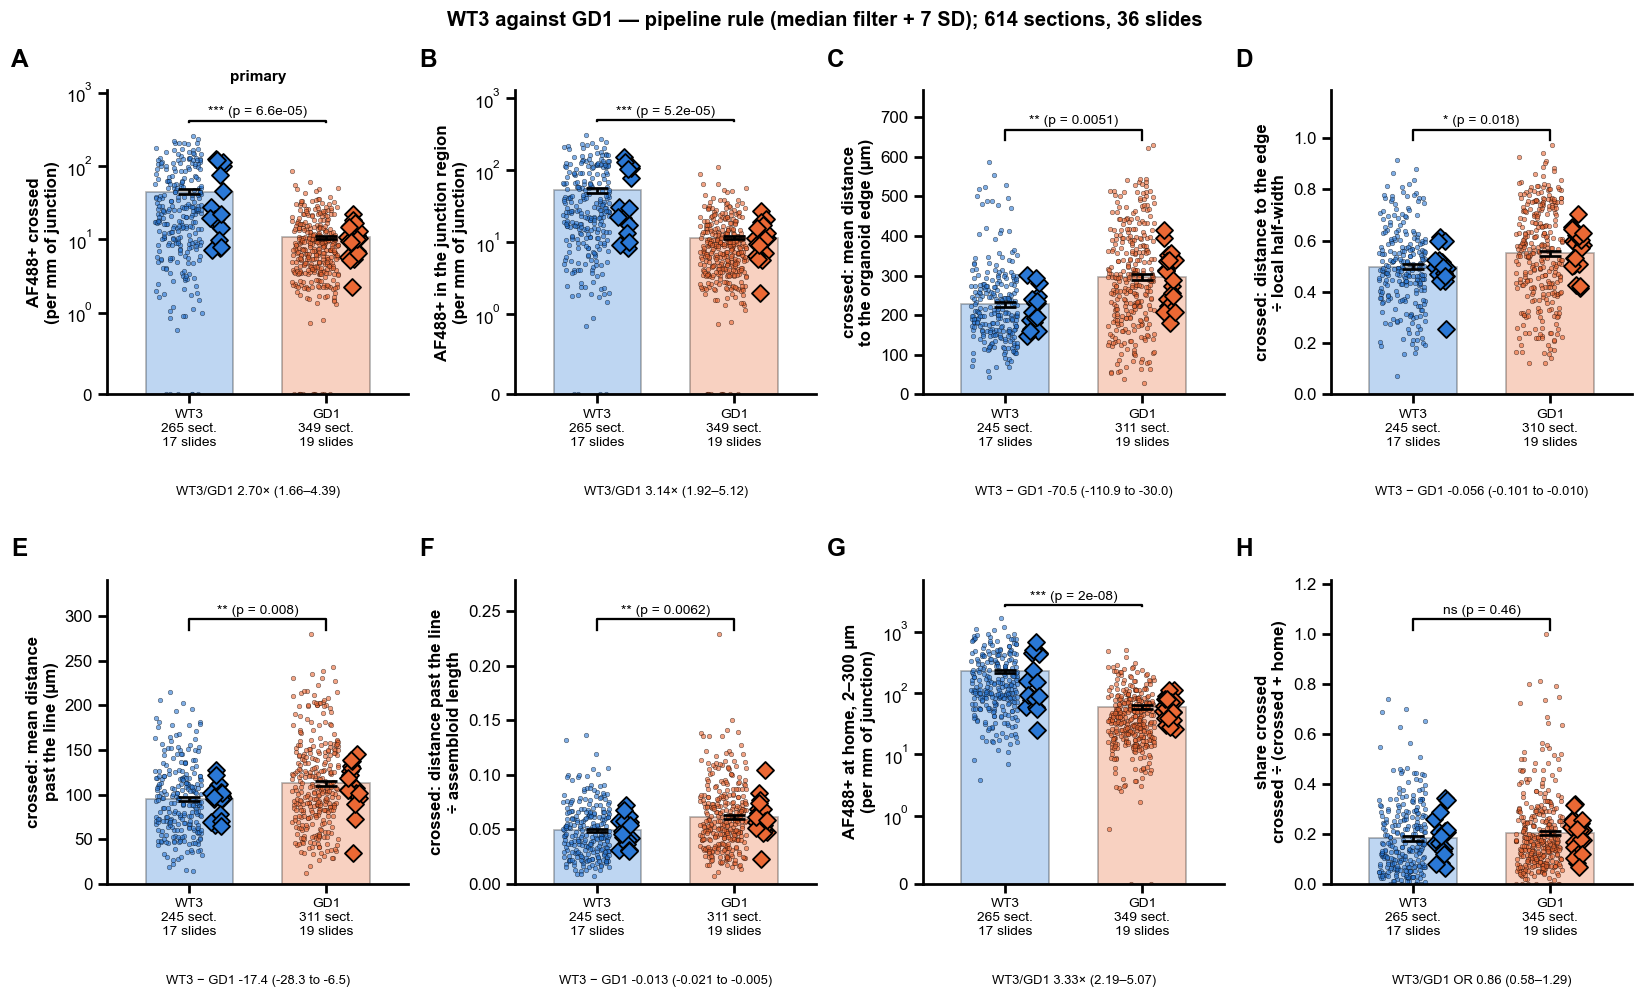

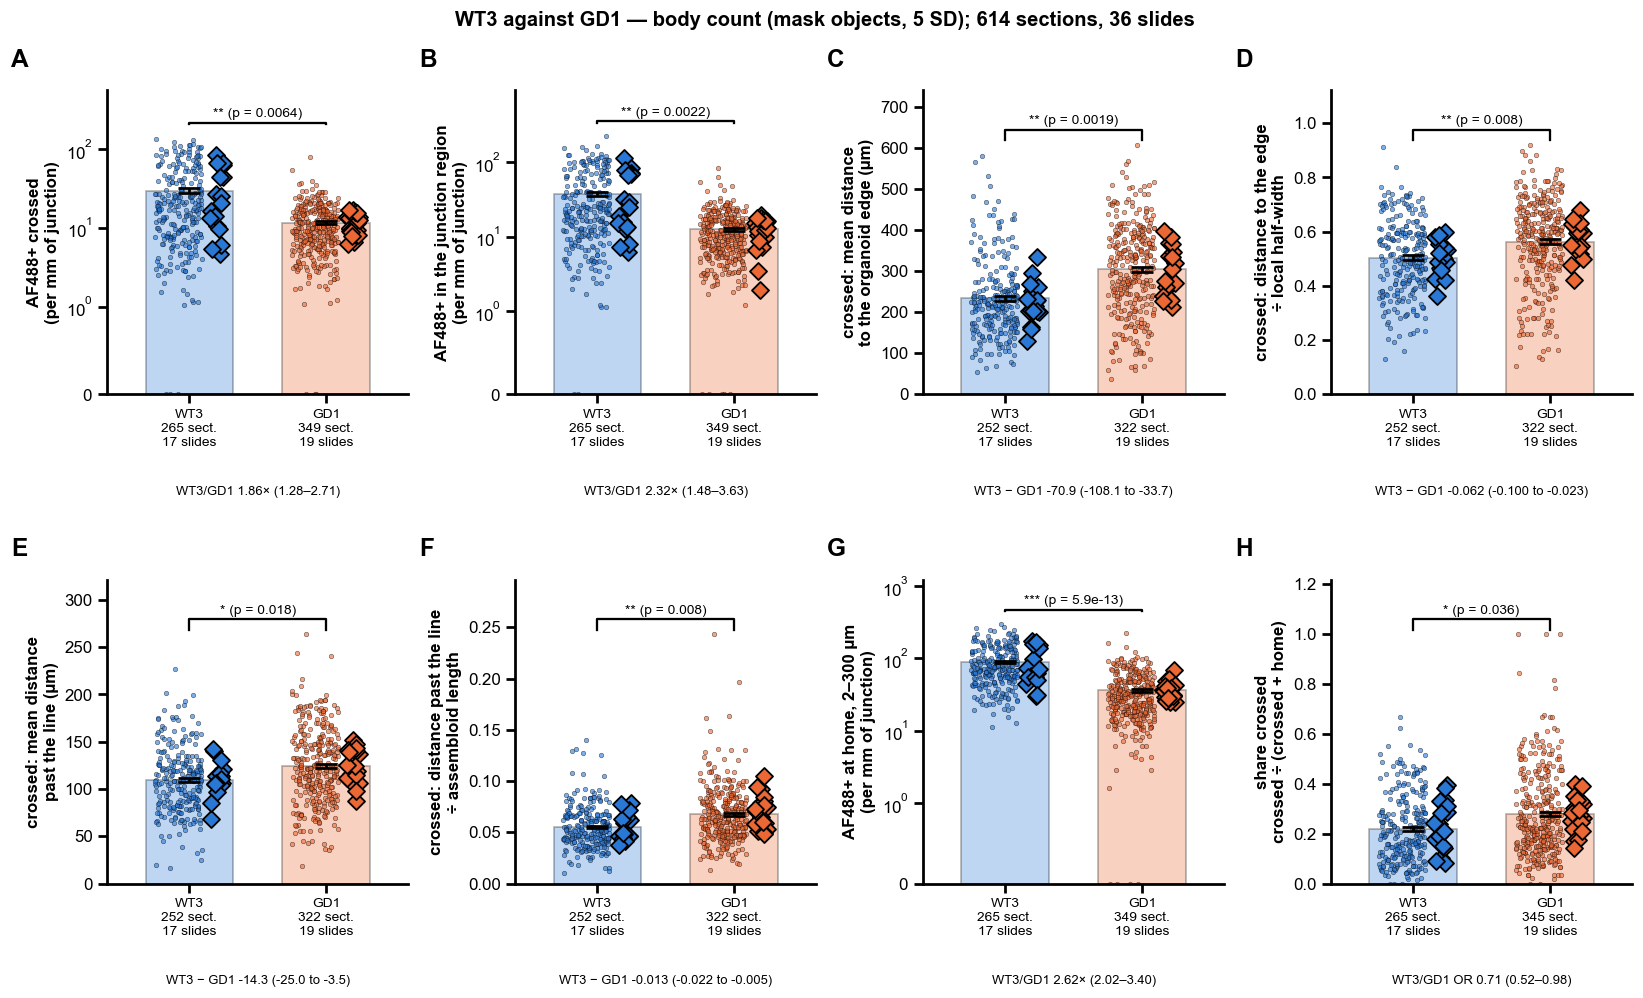

In [27]:
def bars_dots_slides(ax, frame, column, p=None, log=False, seed=SEED):
    """Bar = mean ± SEM of sections; dots = sections; diamonds = slide means; bracket with the p."""
    rng = np.random.default_rng(seed)
    top = 0.0
    for k, g in enumerate(GENOTYPES):
        part = frame[frame["Genotype"] == g]
        y = pd.to_numeric(part[column], errors="coerce").dropna()
        if not len(y):
            continue
        slide_y = part.groupby("slide")[column].mean().dropna()
        top = max(top, y.max())
        ax.bar(k, y.mean(), width=0.64, color=GENOTYPE_COLOURS[g], alpha=0.3, zorder=1, **EDGE)
        ax.errorbar(k, y.mean(), yerr=y.std(ddof=1) / np.sqrt(len(y)), color="black", capsize=7, capthick=1.8,
                    lw=1.8, zorder=5)
        ax.scatter(k - 0.08 + rng.uniform(-0.17, 0.17, len(y)), y, s=9, color=GENOTYPE_COLOURS[g], alpha=0.6, zorder=2,
                   edgecolor="black", linewidth=0.35)
        ax.scatter(k + 0.2 + rng.uniform(-0.05, 0.05, len(slide_y)), slide_y, s=62, marker="D",
                   color=GENOTYPE_COLOURS[g], zorder=4, edgecolor="black", linewidth=1.2)
    n_sec = [int(pd.to_numeric(frame.loc[frame["Genotype"] == g, column], errors="coerce").notna().sum()) for g in GENOTYPES]
    n_sl = [frame[frame["Genotype"] == g].dropna(subset=[column])["slide"].nunique() for g in GENOTYPES]
    ax.set_xticks(range(2), [f"{g}\n{a} sect.\n{b} slides" for g, a, b in zip(GENOTYPES, n_sec, n_sl)], fontsize=9)
    ax.set_xlim(-0.6, 1.6)
    if log:
        ax.set_yscale("symlog", linthresh=1)
    lo = min(0.0, float(pd.to_numeric(frame[column], errors="coerce").min()))
    ax.set_ylim(bottom=lo)
    if p is not None:
        y0 = top * (1.6 if log else 1.06)
        ax.plot([0, 0, 1, 1], [y0 * 0.96, y0, y0, y0 * 0.96], color="black", lw=1.5)
        ax.text(0.5, y0 * (1.08 if log else 1.01), f"{stars(p)} (p = {p:.2g})", ha="center", va="bottom", fontsize=9)
        ax.set_ylim(top=y0 * (2.6 if log else 1.15))


def method_figure(method, name):
    frame = obs[obs["method"] == method]
    panels = MAIN_OUTCOMES + ["home per mm", "share crossed"]
    fig, axes = plt.subplots(2, 4, figsize=(15, 9.4))
    for ax, outcome in zip(axes.flat, panels):
        kind = OUTCOMES[outcome][0]
        hit = primary[(primary["method"] == METHODS[method]) & (primary["outcome"] == outcome)]
        e = hit.iloc[0] if len(hit) else pd.Series({**mixed(frame, outcome, kind), "outcome": outcome})
        p = e["p (Holm)"] if len(hit) else e["p"]
        bars_dots_slides(ax, frame, outcome, p=p, log=kind == "fold")
        ax.set_ylabel(OUTCOMES[outcome][1])
        ax.text(0.5, -0.33, ("WT3/GD1 " if kind != "difference" else "WT3 − GD1 ") + effect_text(
            {**e, "outcome": outcome}, kind), transform=ax.transAxes, ha="center", fontsize=8.5)
    axes[0, 0].set_title("primary" if method == PIPELINE else "", fontsize=10)
    panel_letters(axes, x=-0.32)
    fig.suptitle(f"WT3 against GD1 — {METHODS[method]}; {frame['name'].nunique()} sections, "
                 f"{frame['slide'].nunique()} slides", fontweight="bold")
    fig.tight_layout()
    save(fig, name)
    plt.show()


method_figure(PIPELINE, "biology_pipeline_rule")
method_figure(BODY, "biology_body_count")

In [28]:
_p = primary.set_index(["method", "outcome"])
_pr = _p.loc[(METHODS[PIPELINE], PRIMARY)]
_bo = _p.loc[(METHODS[BODY], PRIMARY)]
verdict("Primary: more AF488+ cells crossed per mm in WT3 (pipeline rule)",
        "PASS" if _pr["p"] < 0.05 and _bo["p (Holm)"] < 0.05 else "PASS with caveat" if _pr["p"] < 0.05 else "FAIL",
        f"WT3/GD1 {_pr['effect']:.2f}× (95 % CI {_pr['CI low']:.2f}–{_pr['CI high']:.2f}), p {_pr['p']:.2g}, "
        f"{int(_pr['sections'])} sections / {int(_pr['slides'])} slides; body count {_bo['effect']:.2f}× "
        f"({_bo['CI low']:.2f}–{_bo['CI high']:.2f}), Holm p {_bo['p (Holm)']:.2g}",
        "the fold with its CI from the mixed model (slide random, experiment fixed); the body count as confirmation")
_sec = primary[primary["role"] == "secondary"]
verdict("Secondary outcomes after Holm (11 tests)",
        "PASS with caveat",
        "; ".join(f"{r['outcome']} [{'pipe' if r['method'] == METHODS[PIPELINE] else 'body'}] {r['effect (95 % CI)']} "
                  f"Holm p {r['p (Holm)']:.2g}" for _, r in _sec.iterrows()),
        "the Holm-adjusted p's; only those surviving Holm as findings, the others as trends")

[PASS] Primary: more AF488+ cells crossed per mm in WT3 (pipeline rule)
    WT3/GD1 2.70× (95 % CI 1.66–4.39), p 6.6e-05, 614 sections / 36 slides; body count 1.86× (1.28–2.71), Holm p 0.0064
[PASS with caveat] Secondary outcomes after Holm (11 tests)
    in junction per mm [pipe] 3.14× (1.92–5.12) Holm p 5.2e-05; edge (µm) [pipe] -70.5 (-110.9 to -30.0) Holm p 0.0051; edge ÷ half-width [pipe] -0.056 (-0.101 to -0.010) Holm p 0.018; past line (µm) [pipe] -17.4 (-28.3 to -6.5) Holm p 0.008; past line ÷ assembloid length [pipe] -0.013 (-0.021 to -0.005) Holm p 0.0062; crossed per mm [body] 1.86× (1.28–2.71) Holm p 0.0064; in junction per mm [body] 2.32× (1.48–3.63) Holm p 0.0022; edge (µm) [body] -70.9 (-108.1 to -33.7) Holm p 0.0019; edge ÷ half-width [body] -0.062 (-0.100 to -0.023) Holm p 0.008; past line (µm) [body] -14.3 (-25.0 to -3.5) Holm p 0.018; past line ÷ assembloid length [body] -0.013 (-0.022 to -0.005) Holm p 0.008


**Verdict — primary and secondary outcomes. Primary: PASS. Secondary: PASS** (all 11 survive Holm). The caveat is the size of the distance effects.

| outcome | pipeline rule (median filter + 7 SD) | body count (mask objects, 5 SD) |
|---|---|---|
| **crossed per mm (primary)** | **2.70× (1.66–4.39), p 7 × 10⁻⁵** | 1.86× (1.28–2.71), Holm p 0.006 |
| in the junction region per mm | 3.14× (1.92–5.12), Holm p 5 × 10⁻⁵ | 2.32× (1.48–3.63), Holm p 0.002 |
| crossed: distance to the edge | −70 µm (−111 to −30), Holm p 0.005 | −71 µm (−108 to −34), Holm p 0.002 |
| crossed: edge ÷ local half-width | −0.056 (−0.101 to −0.010), Holm p 0.018 | −0.062 (−0.100 to −0.023), Holm p 0.008 |
| crossed: distance past the line | −17 µm (−28 to −7), Holm p 0.008 | −14 µm (−25 to −4), Holm p 0.018 |
| crossed: past the line ÷ assembloid length | −0.013 (−0.021 to −0.005), Holm p 0.006 | −0.013 (−0.022 to −0.005), Holm p 0.008 |

WT3 / GD1 fold for the counts and WT3 − GD1 for the distances, 95 % CI. Mixed model with slide random and experiment fixed; 614 sections and 36 slides (556–574 sections for the distance outcomes, which need ≥ 3 crossed cells).

- **Counts.** WT3 has about 2.7× (pipeline rule) or 1.9× (body count) more AF488+ cells per mm past the line, and 2.3–3.1× more in the junction region. Means per mm: pipeline 45 against 11; body count 30 against 12.
- **Route.** WT3's crossed cells lie about 70 µm nearer the organoid edge (227 µm against 296 µm). Divided by the organoid's local half-width, the difference is smaller: 0.50 against 0.55, where all cells past the line sit at 0.59. This is the same with both methods.
- **Depth.** GD1's crossed cells reach slightly further past the line: 15–17 µm, or 0.013 assembloid lengths. The effect is small, and at slide level the pipeline's µm version is borderline (Welch p 0.07).
- **What to report.** The primary outcome is declared, not pre-registered: it was chosen after the exploratory notebooks dataset/03–04. Report the primary fold with its CI, the secondary outcomes with Holm-adjusted p, and the body count as an independent count of the same thing (no nuclei, no SD rule on cells).

### Robustness

**(i) Leave one slide out, leave one experiment out.** The primary outcome's fold refitted 36 times without one slide, and 3 times without one experiment, for both counting methods. A result that flips or loses its CI when one unit goes is carried by that unit.

leave one slide out — primary outcome:


,fold_min,fold_max,lowest_CI_low,p_max,significant
method,,,,,
"body count (mask objects, 5 SD)",1.739,2.021,1.210,0.003,36/36
pipeline rule (median filter + 7 SD),2.485,2.980,1.543,0.000,36/36


leave one experiment out — primary outcome:


effect  CI low  CI high      p  sections  slides
method                               left out                                                       
pipeline rule (median filter + 7 SD) (none)          2.697   1.657    4.390  0.000       614      36
                                     experiment 10   3.362   1.691    6.685  0.001       392      24
                                     experiment 8    3.640   2.040    6.493  0.000       423      25
                                     experiment 9    1.568   1.011    2.430  0.044       413      23
body count (mask objects, 5 SD)      (none)          1.864   1.284    2.707  0.001       614      36
                                     experiment 10   2.504   1.573    3.986  0.000       392      24
                                     experiment 8    2.131   1.388    3.274  0.001       423      25
                                     experiment 9    1.195   0.783    1.822  0.409       413      23

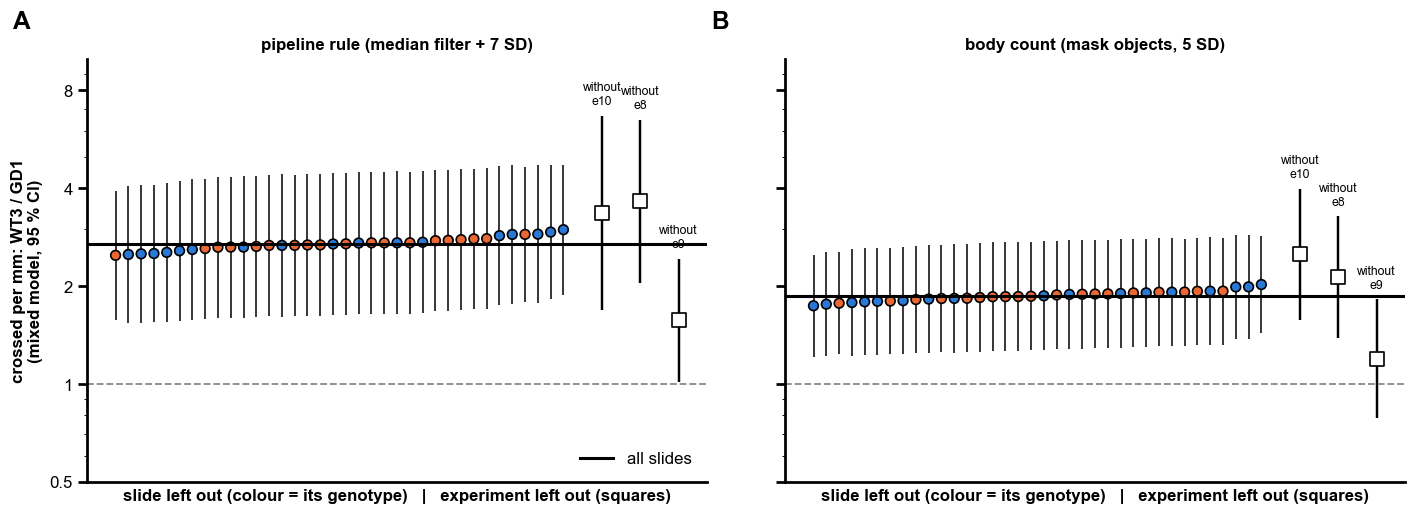

In [29]:
rows = []
for method in METHODS:
    frame = obs[obs["method"] == method]
    rows.append({"method": METHODS[method], "left out": "(none)", "kind": "all", **mixed(frame, PRIMARY, "fold")})
    for slide in sorted(frame["slide"].unique()):
        rows.append({"method": METHODS[method], "left out": slide, "kind": "slide",
                     **mixed(frame[frame["slide"] != slide], PRIMARY, "fold")})
    for e in sorted(frame["Experiment"].unique()):
        rows.append({"method": METHODS[method], "left out": f"experiment {e}", "kind": "experiment",
                     **mixed(frame[frame["Experiment"] != e], PRIMARY, "fold")})
loo = pd.DataFrame(rows)
loso = loo[loo["kind"] == "slide"].groupby("method").agg(
    fold_min=("effect", "min"), fold_max=("effect", "max"), lowest_CI_low=("CI low", "min"), p_max=("p", "max"),
    significant=("p", lambda p: f"{int((p < 0.05).sum())}/{len(p)}"))
print("leave one slide out — primary outcome:")
display(loso.round(3))
print("leave one experiment out — primary outcome:")
display(loo[loo["kind"] != "slide"].set_index(["method", "left out"])[["effect", "CI low", "CI high", "p", "sections",
                                                                        "slides"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, method in zip(axes, METHODS):
    part = loo[loo["method"] == METHODS[method]]
    sl = part[part["kind"] == "slide"].sort_values("effect").reset_index(drop=True)
    ex = part[part["kind"] == "experiment"].reset_index(drop=True)
    xs = np.arange(len(sl))
    ax.vlines(xs, sl["CI low"], sl["CI high"], color="black", lw=1, zorder=1)
    ax.scatter(xs, sl["effect"], s=40, color=[GENOTYPE_COLOURS[x.split(" ")[0]] for x in sl["left out"]], zorder=2, **EDGE)
    for k, r in ex.iterrows():
        x = len(sl) + 2 + k * 3
        ax.vlines(x, r["CI low"], r["CI high"], color="black", lw=1.6)
        ax.scatter(x, r["effect"], s=90, marker="s", color="white", zorder=2, **EDGE)
        ax.text(x, r["CI high"] * 1.06, r["left out"].replace("experiment ", "without\ne"), ha="center", va="bottom",
                fontsize=8)
    ax.axhline(part.loc[part["kind"] == "all", "effect"].iloc[0], color="black", lw=2, label="all slides")
    ax.axhline(1, color=GREY, lw=1.2, ls="--")
    ax.set_yscale("log")
    ax.set_ylim(0.5, 10)
    ax.set_yticks([0.5, 1, 2, 4, 8])
    ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
    ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xticks([])
    ax.set_xlabel("slide left out (colour = its genotype)   |   experiment left out (squares)")
    ax.set_title(METHODS[method], fontsize=11)
axes[0].set_ylabel("crossed per mm: WT3 / GD1\n(mixed model, 95 % CI)")
axes[0].legend(loc="lower right")
panel_letters(axes, x=-0.12)
fig.tight_layout()
save(fig, "biology_leave_one_out")
plt.show()

**(ii) Slide-level analysis** — the conservative check: each slide's mean (of log(1 + y) for counts) is one observation, n = 17 WT3 and 19 GD1 slides. Mann-Whitney (no adjustment), Welch's t-test, and an ordinary regression on the slide means with experiment (n = 36). The fold from the t-test is the ratio of the slides' geometric means of (1 + y).

In [30]:
rows = []
for method in METHODS:
    frame = obs[obs["method"] == method].copy()
    for outcome in MAIN_OUTCOMES:
        kind = OUTCOMES[outcome][0]
        frame["t"] = transform(frame[outcome], kind)
        sl = frame.dropna(subset=["t"]).groupby("slide").agg(t=("t", "mean"), Genotype=("Genotype", "first"),
                                                              Experiment=("Experiment", "first"))
        a, b = sl.loc[sl["Genotype"] == OTHER, "t"], sl.loc[sl["Genotype"] == REFERENCE, "t"]
        welch = stats.ttest_ind(a, b, equal_var=False)
        diff = a.mean() - b.mean()
        se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
        dof = se ** 4 / ((a.var(ddof=1) / len(a)) ** 2 / (len(a) - 1) + (b.var(ddof=1) / len(b)) ** 2 / (len(b) - 1))
        lo, hi = diff - stats.t.ppf(0.975, dof) * se, diff + stats.t.ppf(0.975, dof) * se
        ols = smf.ols(f"t ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)", sl).fit()
        f = np.exp if kind == "fold" else (lambda v: v)
        rows.append({"method": METHODS[method], "outcome": outcome, "slides WT3/GD1": f"{len(a)}/{len(b)}",
                     "effect (Welch)": f(diff), "CI low": f(lo), "CI high": f(hi), "Welch p": welch.pvalue,
                     "Mann-Whitney p": stats.mannwhitneyu(a, b).pvalue,
                     "effect (OLS + experiment)": f(ols.params[TERM]), "OLS p": ols.pvalues[TERM]})
slide_level = pd.DataFrame(rows).set_index(["method", "outcome"])
display(slide_level.round(4))

slides WT3/GD1  effect (Welch)    CI low  CI high  Welch p  Mann-Whitney p  effect (OLS + experiment)   OLS p
method                               outcome                                                                                                                                    
pipeline rule (median filter + 7 SD) crossed per mm                         17/19          2.6418    1.4280   4.8875   0.0035          0.0085                     2.6798  0.0007
                                     in junction per mm                     17/19          3.0782    1.6728   5.6645   0.0009          0.0015                     3.1300  0.0001
                                     edge (µm)                              17/19        -74.2716 -114.1706 -34.3725   0.0006          0.0017                   -74.8889  0.0008
                                     edge ÷ half-width                      17/19         -0.0688   -0.1242  -0.0135   0.0163          0.0175                    -0.0683  0.0180
                                     past line (µm)                         17/19        -14.1631  -29.5618   1.2356   0.0702          0.0288                   -14.6185  0.0511
                                     past line ÷ assembloid length          17/19         -0.0119   -0.0223  -0.0016   0.0249          0.0312                    -0.0123  0.0115
body count (mask objects, 5 SD)      crossed per mm                         17/19          1.8496    1.1225   3.0478   0.0184          0.0337                     1.8695  0.0033
                                     in junction per mm                     17/19          2.3086    1.3359   3.9896   0.0043          0.0085                     2.3333  0.0011
                                     edge (µm)                              17/19        -72.2926 -109.6772 -34.9081   0.0004          0.0006                   -72.9611  0.0005
                                     edge ÷ half-width                      17/19         -0.0741   -0.1174  -0.0307   0.0014          0.0015                    -0.0736  0.0017
                                     past line (µm)                         17/19        -14.9200  -27.2256  -2.6144   0.0190          0.0123                   -15.0415  0.0210
                                     past line ÷ assembloid length          17/19         -0.0143   -0.0241  -0.0046   0.0052          0.0078                    -0.0146  0.0048

**(iii) Direction across positivity methods.** The primary and secondary outcomes under the nine rules of `dataset/04` (raw and median-filtered mean at median + 3 / 5 / 7 SD; the AF488 mask covering ≥ 25 % of a cell at 3 / 5 / 8 SD) and the three body counts (mask objects at 3 / 5 / 8 SD): the share of methods giving the same sign as the pipeline rule, and the share also significant (mixed model, p < 0.05). The forest shows crossed per mm, at home per mm and the share crossed.

C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(


C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 7.259694
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regr

C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(


C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 14.794070
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


... (7 outputs left out)

C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\qfavey\.conda\envs\napari-env-q\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,9 rules: same sign,9 rules: same sign and p < 0.05,12 methods: same sign and p < 0.05,range of effects (9 rules)
crossed per mm,9/9,8/9,11/12,1.45 to 3.46
in junction per mm,9/9,8/9,11/12,1.65 to 3.93
edge (µm),9/9,9/9,12/12,-105.92 to -57.49
edge ÷ half-width,9/9,8/9,10/12,-0.11 to -0.04
past line (µm),9/9,5/9,7/12,-20.18 to -3.64
past line ÷ assembloid length,9/9,8/9,10/12,-0.02 to -0.00
home per mm,9/9,9/9,12/12,2.80 to 5.95
share crossed,7/9,3/9,5/12,0.31 to 1.38


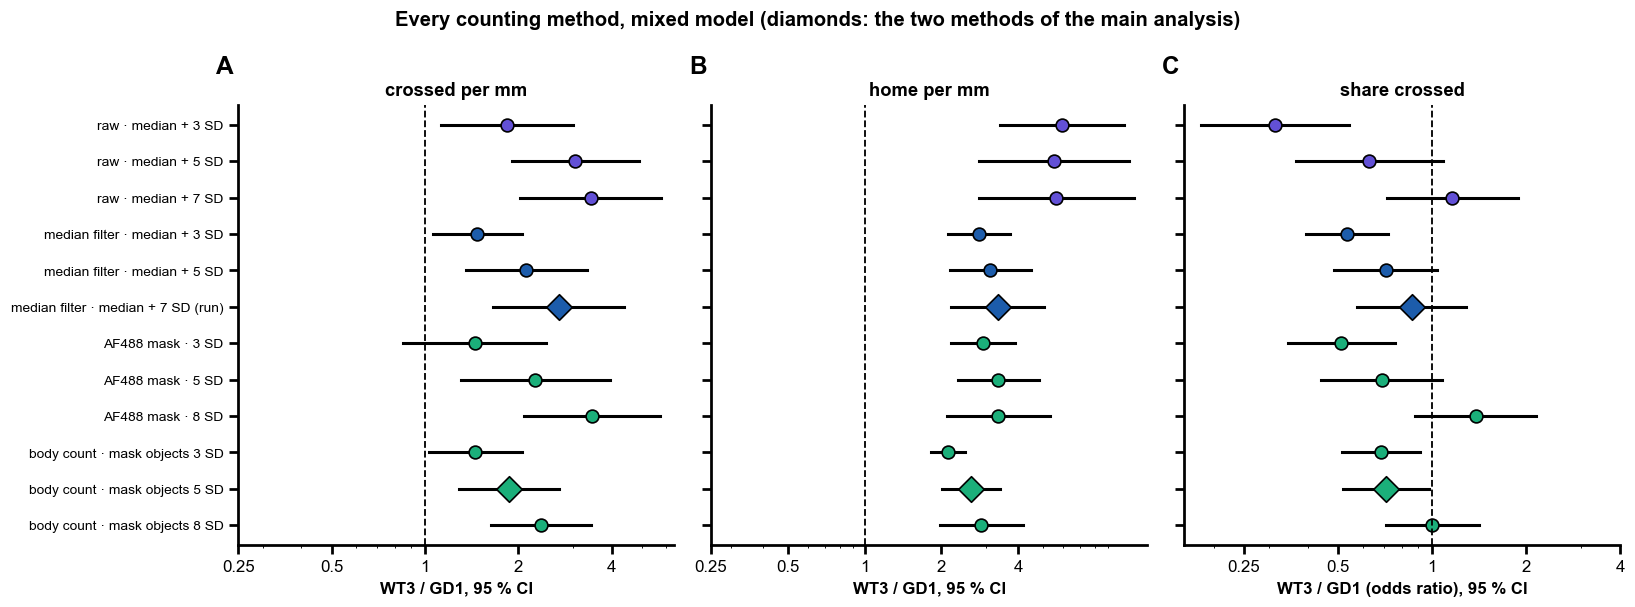

In [31]:
rows = []
for method in ALL_METHODS:
    frame = obs[obs["method"] == method]
    for outcome in OUTCOMES:
        rows.append({"method": method, "outcome": outcome, **mixed(frame, outcome, OUTCOMES[outcome][0])})
by_method = pd.DataFrame(rows)


def same_direction(outcome, methods):
    part = by_method[(by_method["outcome"] == outcome) & by_method["method"].isin(methods)]
    ref = by_method[(by_method["outcome"] == outcome) & (by_method["method"] == PIPELINE)].iloc[0]
    centre = 0 if OUTCOMES[outcome][0] == "difference" else 1
    same = np.sign(part["effect"] - centre) == np.sign(ref["effect"] - centre)
    return same.sum(), (same & (part["p"] < 0.05)).sum(), len(part)


direction = pd.DataFrame({outcome: {
    "9 rules: same sign": "{}/{}".format(*np.array(same_direction(outcome, RULE_NAMES))[[0, 2]]),
    "9 rules: same sign and p < 0.05": "{}/{}".format(*np.array(same_direction(outcome, RULE_NAMES))[[1, 2]]),
    "12 methods: same sign and p < 0.05": "{}/{}".format(*np.array(same_direction(outcome, ALL_METHODS))[[1, 2]]),
    "range of effects (9 rules)": "{:.2f} to {:.2f}".format(
        *by_method[(by_method["outcome"] == outcome) & by_method["method"].isin(RULE_NAMES)]["effect"].agg(["min", "max"]))}
    for outcome in OUTCOMES}).T
display(direction)

fig, axes = plt.subplots(1, 3, figsize=(15, 5.6), sharey=True)
y = np.arange(len(ALL_METHODS))[::-1]
for ax, outcome in zip(axes, ["crossed per mm", "home per mm", "share crossed"]):
    e = by_method[by_method["outcome"] == outcome].set_index("method").loc[ALL_METHODS]
    for k, m in enumerate(ALL_METHODS):
        colour = "#6250d6" if m.startswith("raw") else PIPELINE_COLOUR if m.startswith("median") else "#1baf7a"
        ax.plot([e.at[m, "CI low"], e.at[m, "CI high"]], [y[k], y[k]], color="black", lw=2, zorder=1)
        ax.scatter(e.at[m, "effect"], y[k], s=140 if m in METHODS else 70, marker="D" if m in METHODS else "o",
                   color=colour, zorder=2, **EDGE)
    ax.axvline(1, color="black", lw=1.2, ls="--")
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xticks([0.25, 0.5, 1, 2, 4])
    ax.set_xlabel("WT3 / GD1" + (" (odds ratio)" if outcome == "share crossed" else "") + ", 95 % CI")
    ax.set_title(outcome)
axes[0].set_yticks(y, ALL_METHODS, fontsize=9)
panel_letters(axes, x=-0.05)
fig.suptitle("Every counting method, mixed model (diamonds: the two methods of the main analysis)", fontweight="bold")
fig.tight_layout()
save(fig, "biology_methods_forest")
plt.show()

**(iv) More labelled cells, or more migration?** WT3 has more AF488+ cells at home as well. If WT3 simply has more labelled cells, more will cross even at the same per-cell rate. Two tests: the **share crossed** = crossed ÷ (crossed + home), both 2–300 µm from the line (mixed model on its logit, odds ratio WT3 / GD1); and crossed per mm with log(1 + home per mm) as a covariate (more crossing *at the same number of labelled cells at home*). Plus the plot of crossed against home per section: if both genotypes lie on one line, the difference is in labelling, not migration.

pipeline rule (median filter + 7 SD): within a genotype, 1 + crossed rises as (1 + home)^0.40 (1 = proportional)
pipeline rule (median filter + 7 SD): share crossed mean WT3 0.182 / GD1 0.204; median 0.146 / 0.167
body count (mask objects, 5 SD): within a genotype, 1 + crossed rises as (1 + home)^0.16 (1 = proportional)
body count (mask objects, 5 SD): share crossed mean WT3 0.220 / GD1 0.279; median 0.195 / 0.231


effect  CI low  CI high       p  sections  slides
method                               test                                                                                       
pipeline rule (median filter + 7 SD) home per mm                               3.3290  2.1880   5.0651  0.0000       614      36
                                     crossed per mm                            2.6969  1.6567   4.3900  0.0001       614      36
                                     crossed per mm, adjusted for home per mm  1.6685  1.1161   2.4942  0.0126       614      36
                                     share crossed (odds ratio)                0.8604  0.5758   1.2856  0.4630       610      36
body count (mask objects, 5 SD)      home per mm                               2.6198  2.0158   3.4048  0.0000       614      36
                                     crossed per mm                            1.8642  1.2840   2.7066  0.0011       614      36
                                     crossed per mm, adjusted for home per mm  1.5915  1.1159   2.2699  0.0103       614      36
                                     share crossed (odds ratio)                0.7134  0.5203   0.9783  0.0361       610      36

share crossed, odds ratio WT3 / GD1, under the low-noise methods:


,effect,CI low,CI high,p,sections
method,,,,,
median filter · median + 5 SD,0.711,0.485,1.040,0.079,614
median filter · median + 7 SD (run),0.860,0.576,1.286,0.463,610
AF488 mask · 5 SD,0.691,0.443,1.078,0.104,608
AF488 mask · 8 SD,1.382,0.886,2.157,0.154,597
body count · mask objects 5 SD,0.713,0.520,0.978,0.036,610
body count · mask objects 8 SD,1.003,0.712,1.413,0.986,598


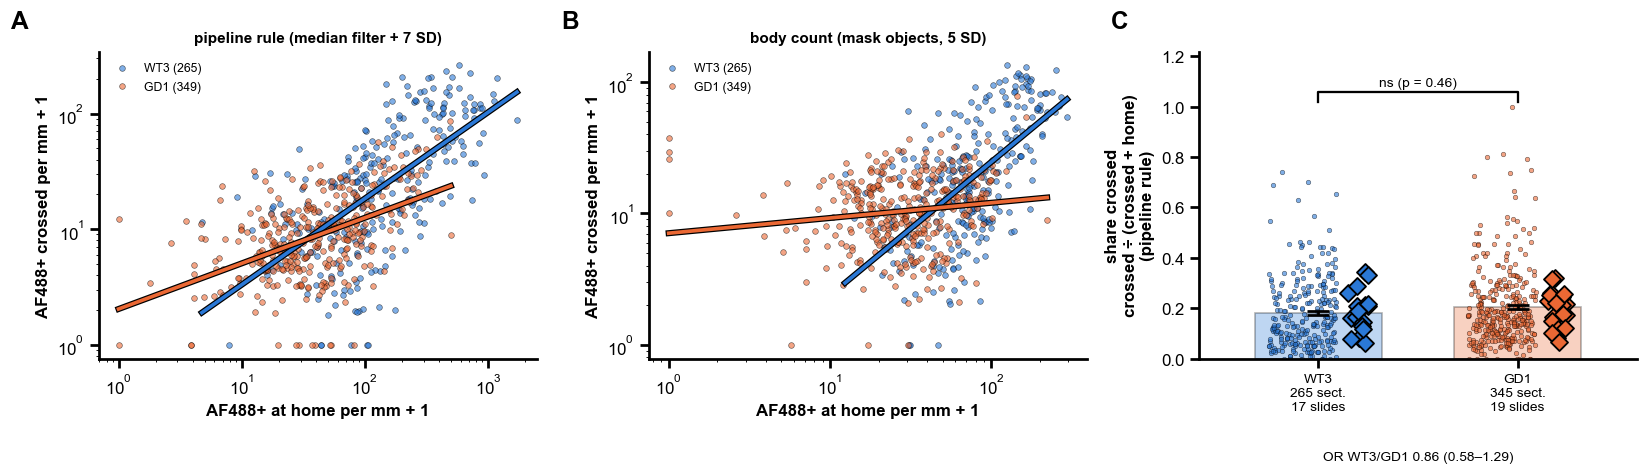

In [32]:
rows = []
for method in METHODS:
    frame = obs[obs["method"] == method].copy()
    frame["log_home"] = np.log1p(frame["home per mm"])
    for label, outcome, kind, extra in (("home per mm", "home per mm", "fold", ""),
                                        ("crossed per mm", "crossed per mm", "fold", ""),
                                        ("crossed per mm, adjusted for home per mm", "crossed per mm", "fold", " + log_home"),
                                        ("share crossed (odds ratio)", "share crossed", "logit", "")):
        rows.append({"method": METHODS[method], "test": label, **mixed(frame, outcome, kind, extra)})
    frame["log_crossed"] = np.log1p(frame["crossed per mm"])
    slope = smf.mixedlm("log_crossed ~ C(Genotype) + C(Experiment) + log_home", frame,
                        groups=frame["slide"]).fit(reml=True).params["log_home"]
    print(f"{METHODS[method]}: within a genotype, 1 + crossed rises as (1 + home)^{slope:.2f} (1 = proportional)")
    means = frame.groupby("Genotype")["share crossed"].agg(["mean", "median"])
    print(f"{METHODS[method]}: share crossed mean WT3 {means.at['WT3', 'mean']:.3f} / GD1 {means.at['GD1', 'mean']:.3f}; "
          f"median {means.at['WT3', 'median']:.3f} / {means.at['GD1', 'median']:.3f}")
share_tests = pd.DataFrame(rows).set_index(["method", "test"])
display(share_tests.round(4))
ok_rules = ["median filter · median + 5 SD", PIPELINE, "AF488 mask · 5 SD", "AF488 mask · 8 SD", BODY,
            "body count · mask objects 8 SD"]
print("share crossed, odds ratio WT3 / GD1, under the low-noise methods:")
display(by_method[(by_method["outcome"] == "share crossed") & by_method["method"].isin(ok_rules)]
        .set_index("method")[["effect", "CI low", "CI high", "p", "sections"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
frame = obs[obs["method"] == PIPELINE]
for ax, method in zip(axes[:2], METHODS):
    part = obs[obs["method"] == method]
    for g in GENOTYPES:
        q = part[part["Genotype"] == g]
        xh, yc = np.log1p(q["home per mm"]), np.log1p(q["crossed per mm"])
        ax.scatter(q["home per mm"] + 1, q["crossed per mm"] + 1, s=14, color=GENOTYPE_COLOURS[g], alpha=0.6,
                   edgecolor="black", linewidth=0.4, label=f"{g} ({len(q)})")
        fit = np.polyfit(xh, yc, 1)
        xs = np.linspace(xh.min(), xh.max(), 50)
        ax.plot(np.exp(xs), np.exp(np.polyval(fit, xs)), color="black", lw=4)
        ax.plot(np.exp(xs), np.exp(np.polyval(fit, xs)), color=GENOTYPE_COLOURS[g], lw=2.4)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("AF488+ at home per mm + 1")
    ax.set_ylabel("AF488+ crossed per mm + 1")
    ax.set_title(METHODS[method], fontsize=10)
    ax.legend(fontsize=8, loc="upper left")
e = share_tests.loc[(METHODS[PIPELINE], "share crossed (odds ratio)")]
bars_dots_slides(axes[2], frame, "share crossed", p=e["p"])
axes[2].set_ylabel(OUTCOMES["share crossed"][1] + "\n(pipeline rule)")
axes[2].text(0.5, -0.33, f"OR WT3/GD1 {e['effect']:.2f} ({e['CI low']:.2f}–{e['CI high']:.2f})",
             transform=axes[2].transAxes, ha="center", fontsize=9)
panel_letters(axes, x=-0.2)
fig.tight_layout()
save(fig, "biology_share_crossed")
plt.show()

**(v) Residual confounders from §1.** QC status ("ok" in 43 % of WT3 against 16 % of GD1 sections), a hand-drawn region, pre-screen Quality and Folded, and the section's size (log junction length, log cells in the section) added as covariates to the primary outcome's model, one at a time and all together; and the model within each QC stratum alone.

effect  CI low  CI high      p  sections  slides
method                               model                                                                   
pipeline rule (median filter + 7 SD) experiment only          2.697   1.657    4.390  0.000       614      36
                                     + QC ok                  2.477   1.554    3.948  0.000       614      36
                                     + hand-drawn region      2.689   1.650    4.381  0.000       614      36
                                     + Quality good           2.705   1.662    4.403  0.000       614      36
                                     + Folded                 2.698   1.657    4.392  0.000       614      36
                                     + log junction length    2.634   1.640    4.231  0.000       614      36
                                     + log cells in section   2.641   1.633    4.271  0.000       614      36
                                     + all of these           2.150   1.413    3.270  0.000       614      36
                                     only QC ok               1.781   1.077    2.946  0.025       170      25
                                     only QC check / fail     2.873   1.652    4.996  0.000       444      36
body count (mask objects, 5 SD)      experiment only          1.864   1.284    2.707  0.001       614      36
                                     + QC ok                  1.884   1.294    2.742  0.001       614      36
                                     + hand-drawn region      1.832   1.261    2.661  0.001       614      36
                                     + Quality good           1.867   1.285    2.710  0.001       614      36
                                     + Folded                 1.872   1.290    2.718  0.001       614      36
                                     + log junction length    1.850   1.277    2.679  0.001       614      36
                                     + log cells in section   1.789   1.239    2.584  0.002       614      36
                                     + all of these           1.604   1.141    2.255  0.007       614      36
                                     only QC ok               1.686   1.144    2.487  0.008       170      25
                                     only QC check / fail     2.001   1.269    3.155  0.003       444      36

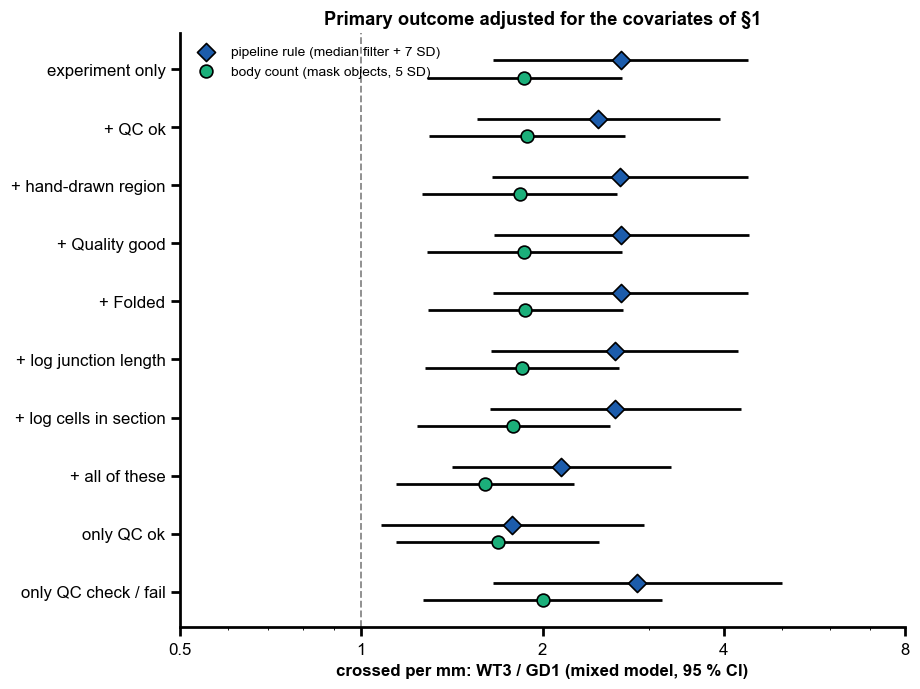

In [33]:
ADJUST = {"QC ok": " + qc", "hand-drawn region": " + hand", "Quality good": " + good", "Folded": " + folded",
          "log junction length": " + log_length", "log cells in section": " + log_cells",
          "all of these": " + qc + hand + good + folded + log_length + log_cells"}
rows = []
for method in METHODS:
    frame = obs[obs["method"] == method].copy()
    frame["qc"], frame["hand"] = frame["QC ok"].astype(int), frame["hand-drawn region"].astype(int)
    frame["good"], frame["folded"] = frame["Quality good"].astype(int), frame["Folded (yes)"].astype(int)
    frame["log_length"], frame["log_cells"] = np.log(frame["length (mm)"]), np.log(frame["cells in section"])
    rows.append({"method": METHODS[method], "model": "experiment only", **mixed(frame, PRIMARY, "fold")})
    for label, extra in ADJUST.items():
        rows.append({"method": METHODS[method], "model": f"+ {label}", **mixed(frame, PRIMARY, "fold", extra)})
    for value in (True, False):
        rows.append({"method": METHODS[method], "model": f"only QC {'ok' if value else 'check / fail'}",
                     **mixed(frame[frame["QC ok"] == value], PRIMARY, "fold")})
adjusted = pd.DataFrame(rows)
display(adjusted.set_index(["method", "model"]).round(3))
fig, ax = plt.subplots(figsize=(8.5, 6.4))
models = list(dict.fromkeys(adjusted["model"]))
ys = np.arange(len(models))[::-1]
for k, method in enumerate(METHODS):
    part = adjusted[adjusted["method"] == METHODS[method]].set_index("model").loc[models]
    off = 0.15 if k == 0 else -0.15
    ax.hlines(ys + off, part["CI low"], part["CI high"], color="black", lw=1.8)
    ax.scatter(part["effect"], ys + off, s=70, marker="D" if k == 0 else "o",
               color=PIPELINE_COLOUR if k == 0 else "#1baf7a", zorder=3, label=METHODS[method], **EDGE)
ax.axvline(1, color=GREY, ls="--", lw=1.2)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xticks([0.5, 1, 2, 4, 8])
ax.set_yticks(ys, models)
ax.set_xlabel("crossed per mm: WT3 / GD1 (mixed model, 95 % CI)")
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Primary outcome adjusted for the covariates of §1")
fig.tight_layout()
save(fig, "biology_adjusted")
plt.show()

**Selection sensitivity: inverse-probability weighting.** §1 found that passed WT3 sections were left out of the run far more often than GD1 ones, and that the left-out sections were the harder ones (worse pre-screen Quality, fewer finder "ok", higher seam price, shorter junctions). If those sections differed in the outcome, the analysed set would be biased. A logistic model of *analysed* among the passed sections (genotype × (Quality good, Folded, finder ok, seam price, log junction length), plus experiment) gives each analysed section its probability of having been kept. Weighting each section by 1 / that probability lets the kept hard sections stand in for the lost ones. The primary outcome is then refitted by weighted least squares on log(1 + y) with experiment, with standard errors clustered by slide (the mixed model takes no weights). The 20 analysed sections outside the passed set (Pass = review) take their genotype's mean weight. This corrects only for what the pre-screen and the finder measured, not for whatever made a reviewer reject a junction.

In [34]:
sel = passed_two.copy()
sel["good"], sel["folded"] = sel["Quality good"].astype(int), sel["Folded (yes)"].astype(int)
sel["finder_ok"] = sel["finder ok"].astype(int)
sel["seam"] = sel["Seam price"].fillna(sel["Seam price"].median())
sel["log_length"] = np.log(sel["Junction length (um)"].fillna(sel["Junction length (um)"].median()).clip(lower=50))
sel["kept"] = sel["analysed"].astype(int)
selection = smf.logit("kept ~ C(Genotype) * (good + folded + finder_ok + seam + log_length) + C(Experiment)",
                      sel).fit(disp=0)
sel["p kept"] = selection.predict(sel)
weights = (1 / sel.loc[sel["analysed"], "p kept"]).rename("weight")
print(f"selection model: pseudo-R² {selection.prsquared:.2f}; weights {weights.min():.2f}–{weights.max():.2f} "
      f"(WT3 mean {weights[sel.loc[weights.index, 'Genotype'] == 'WT3'].mean():.2f}, "
      f"GD1 mean {weights[sel.loc[weights.index, 'Genotype'] == 'GD1'].mean():.2f})")
rows = []
for method in METHODS:
    frame = obs[obs["method"] == method].set_index("name").join(weights)
    frame["weight"] = frame["weight"].fillna(frame.groupby("Genotype")["weight"].transform("mean"))
    frame["y"] = np.log1p(frame[PRIMARY])
    codes = frame["slide"].astype("category").cat.codes.to_numpy()
    for label, w in (("unweighted", np.ones(len(frame))), ("inverse-probability weighted", frame["weight"].to_numpy())):
        fit = smf.wls(f"y ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)", frame, weights=w).fit(
            cov_type="cluster", cov_kwds={"groups": codes})
        lo, hi = fit.conf_int().loc[TERM]
        rows.append({"method": METHODS[method], "model": label, "effect": np.exp(fit.params[TERM]),
                     "CI low": np.exp(lo), "CI high": np.exp(hi), "p": fit.pvalues[TERM]})
ipw = pd.DataFrame(rows).set_index(["method", "model"])
print("primary outcome, WT3 / GD1 (WLS on log(1 + y), experiment fixed, SE clustered by slide):")
display(ipw.round(4))

selection model: pseudo-R² 0.34; weights 1.00–11.89 (WT3 mean 1.32, GD1 mean 1.12)
primary outcome, WT3 / GD1 (WLS on log(1 + y), experiment fixed, SE clustered by slide):


effect  CI low  CI high       p
method                               model                                                        
pipeline rule (median filter + 7 SD) unweighted                    2.7263  1.8383   4.0433  0.0000
                                     inverse-probability weighted  2.9707  1.9527   4.5195  0.0000
body count (mask objects, 5 SD)      unweighted                    1.7885  1.2910   2.4777  0.0005
                                     inverse-probability weighted  2.0566  1.4297   2.9582  0.0001

In [35]:
_lo = loo[loo["kind"] == "slide"]
_pipe_lo = _lo[_lo["method"] == METHODS[PIPELINE]]
_le = loo[(loo["kind"] == "experiment") & (loo["method"] == METHODS[PIPELINE])].set_index("left out")
_leb = loo[(loo["kind"] == "experiment") & (loo["method"] == METHODS[BODY])].set_index("left out")
verdict("Primary robust to leaving out any slide or experiment",
        "PASS" if (_lo["p"] < 0.05).all() and (_le["p"] < 0.05).all() and (_leb["p"] < 0.05).all() else "PASS with caveat",
        f"leave one slide out: {_pipe_lo['effect'].min():.2f}–{_pipe_lo['effect'].max():.2f}×, "
        f"{int((_pipe_lo['p'] < 0.05).sum())}/{len(_pipe_lo)} significant; leave one experiment out: "
        + ", ".join(f"{k} {r['effect']:.2f}× ({r['CI low']:.2f}–{r['CI high']:.2f}, p {r['p']:.2g})" for k, r in _le.iterrows())
        + "; body count without experiment 9: "
        + f"{_leb.at['experiment 9', 'effect']:.2f}× (p {_leb.at['experiment 9', 'p']:.2g})",
        "the leave-one-out range, and that experiment 9 carries much of the effect")
_sl = slide_level.loc[(METHODS[PIPELINE], PRIMARY)]
_slb = slide_level.loc[(METHODS[BODY], PRIMARY)]
verdict("Primary holds with slides as the unit (n = 17 / 19)",
        "PASS" if max(_sl["Welch p"], _sl["Mann-Whitney p"]) < 0.05 else "PASS with caveat",
        f"pipeline: {_sl['effect (Welch)']:.2f}× ({_sl['CI low']:.2f}–{_sl['CI high']:.2f}), Welch p {_sl['Welch p']:.2g}, "
        f"Mann-Whitney p {_sl['Mann-Whitney p']:.2g}, OLS + experiment p {_sl['OLS p']:.2g}; body count "
        f"{_slb['effect (Welch)']:.2f}×, Welch p {_slb['Welch p']:.2g}",
        "the slide-level test beside the mixed model")
_d = direction.loc[PRIMARY]
verdict("Primary direction does not depend on the positivity method",
        "PASS with caveat",
        f"9 rules: same sign {_d['9 rules: same sign']}, same sign and p < 0.05 {_d['9 rules: same sign and p < 0.05']}; "
        f"12 methods incl. body counts: {_d['12 methods: same sign and p < 0.05']} significant; folds {_d['range of effects (9 rules)']}",
        "the forest of every method; that the fold grows with the strictness of the rule (lenient rules add equal noise)")
_s = share_tests.loc[(METHODS[PIPELINE], "share crossed (odds ratio)")]
_a = share_tests.loc[(METHODS[PIPELINE], "crossed per mm, adjusted for home per mm")]
_h = share_tests.loc[(METHODS[PIPELINE], "home per mm")]
verdict("WT3's excess of crossed cells is more migration (not only more labelled cells)",
        "FAIL (not shown)" if _s["p"] >= 0.05 else "PASS",
        f"home per mm {_h['effect']:.2f}× ({_h['CI low']:.2f}–{_h['CI high']:.2f}); share crossed OR {_s['effect']:.2f} "
        f"({_s['CI low']:.2f}–{_s['CI high']:.2f}), p {_s['p']:.2g}; crossed adjusted for home {_a['effect']:.2f}× "
        f"({_a['CI low']:.2f}–{_a['CI high']:.2f}), p {_a['p']:.2g}",
        "the share crossed next to the counts: the count difference reflects more labelled cells near the junction, "
        "not a higher rate of crossing")
_ad = adjusted[(adjusted["method"] == METHODS[PIPELINE])].set_index("model")
verdict("Primary survives the residual confounders (QC status, section size, region, quality)",
        "PASS" if (_ad["p"] < 0.05).all() else "PASS with caveat",
        f"fully adjusted {_ad.at['+ all of these', 'effect']:.2f}× ({_ad.at['+ all of these', 'CI low']:.2f}–"
        f"{_ad.at['+ all of these', 'CI high']:.2f}), p {_ad.at['+ all of these', 'p']:.2g}; QC ok only "
        f"{_ad.at['only QC ok', 'effect']:.2f}× (p {_ad.at['only QC ok', 'p']:.2g}); range over models "
        f"{_ad['effect'].min():.2f}–{_ad['effect'].max():.2f}×",
        "the adjusted fold as a sensitivity analysis")
_w = ipw.loc[(METHODS[PIPELINE], "inverse-probability weighted")]
_wb = ipw.loc[(METHODS[BODY], "inverse-probability weighted")]
verdict("Primary survives re-weighting for the genotype-biased selection",
        "PASS" if max(_w["p"], _wb["p"]) < 0.05 else "PASS with caveat",
        f"IPW pipeline {_w['effect']:.2f}× ({_w['CI low']:.2f}–{_w['CI high']:.2f}), p {_w['p']:.2g}; body count "
        f"{_wb['effect']:.2f}× ({_wb['CI low']:.2f}–{_wb['CI high']:.2f}), p {_wb['p']:.2g}",
        "the weighted estimate as the selection sensitivity analysis, with its limit (only measured reasons for exclusion)")

[PASS with caveat] Primary robust to leaving out any slide or experiment
    leave one slide out: 2.48–2.98×, 36/36 significant; leave one experiment out: experiment 10 3.36× (1.69–6.69, p 0.00054), experiment 8 3.64× (2.04–6.49, p 1.2e-05), experiment 9 1.57× (1.01–2.43, p 0.044); body count without experiment 9: 1.19× (p 0.41)
[PASS] Primary holds with slides as the unit (n = 17 / 19)
    pipeline: 2.64× (1.43–4.89), Welch p 0.0035, Mann-Whitney p 0.0085, OLS + experiment p 0.0007; body count 1.85×, Welch p 0.018
[PASS with caveat] Primary direction does not depend on the positivity method
    9 rules: same sign 9/9, same sign and p < 0.05 8/9; 12 methods incl. body counts: 11/12 significant; folds 1.45 to 3.46
[FAIL (not shown)] WT3's excess of crossed cells is more migration (not only more labelled cells)
    home per mm 3.33× (2.19–5.07); share crossed OR 0.86 (0.58–1.29), p 0.46; crossed adjusted for home 1.67× (1.12–2.49), p 0.013
[PASS] Primary survives the residual confounders

**Verdict — §4 robustness. The count difference is robust. Its interpretation as "more migration" is not supported.**

- **(i) Leave one out: PASS with caveat.**
  - Leaving out any one slide gives 2.48–2.98× (pipeline) and 1.74–2.02× (body count), significant in 36/36 for both.
  - Leaving out one experiment: without experiment 10, 3.36×; without experiment 8, 3.64×; without **experiment 9, 1.57× (1.01–2.43, p 0.044)**. The body count without experiment 9 is **1.19× (p 0.41, ns)**.
  - Experiment 9 carries much of the effect (dataset/03: 10× there against 1.2× in experiment 8). Report the per-experiment folds and the heterogeneity between batches.
- **(ii) Slides as the unit (n = 17 / 19): PASS.**
  - Pipeline: 2.64× (1.43–4.89); Welch p 0.004, Mann-Whitney p 0.009, regression with experiment p 0.0007. Body count: 1.85× (1.12–3.05), Welch p 0.018.
  - Every secondary outcome keeps its direction at slide level. All are p < 0.05 except the pipeline's distance past the line in µm (Welch p 0.07; Mann-Whitney 0.03).
- **(iii) Positivity methods: PASS with caveat.**
  - Crossed per mm is higher in WT3 under 9/9 rules (1.45–3.46×) and significant under 8/9, and 11/12 including the three body counts. The exception is the lenient AF488 mask at 3 SD.
  - The edge distance is significant under 12/12 methods. The distance past the line in µm is significant under only 5/9 rules.
  - The fold grows with the strictness of the rule: lenient rules add background calls equally in both genotypes. State this.
- **(iv) More labelled cells or more migration: FAIL (not shown).**
  - WT3 has **3.3× (2.2–5.1) more AF488+ cells at home** within 300 µm of the line, more than the 2.7× crossed.
  - **The share crossed does not differ**: 0.18 against 0.20 per section; OR 0.86 (0.58–1.29), p 0.46. Under the body count GD1's share is even a little higher: OR 0.71 (0.52–0.98), p 0.036. Under the six low-noise methods the OR runs from 0.69 to 1.38, all but one ns.
  - Adjusting the count for log(1 + home) leaves 1.67× (1.12–2.49, p 0.013). But within a genotype, crossed rises only as (1 + home)^0.40, far from proportional. Much of this leftover is the regression dilution of a noisy covariate, so it is not evidence of a higher crossing rate.
  - **Report the result as "more AF488+ cells near and across the junction in WT3", not "more migration".** The difference in kind is the route: crossed cells nearer the surface.
- **(v) Residual confounders: PASS.**
  - QC status, a hand-drawn region, Quality, Folded, log junction length and log cells per section, alone or all together: pipeline 2.15–2.70× (all p ≤ 0.001); body count 1.60–1.88×.
  - Within the QC strata: "ok" only, 1.78× (1.08–2.95, p 0.025, 170 sections); check / fail, 2.87×.
  - **Inverse-probability weighting for the review's genotype-biased selection** (selection model pseudo-R² 0.34; weights 1.0–11.9) moves the fold up, not down: 2.97× (1.95–4.52) pipeline, 2.06× (1.43–2.96) body count. This corrects only for the measured reasons for exclusion.

**Overall verdict for the biology: PASS with caveat.**
- WT3 assembloids have about 2–3× more AF488+ cells per mm crossed into the partner organoid, and in the junction region, than GD1. This holds across counting methods, slide-level tests, covariates, selection weighting and every single slide.
- The crossed cells in WT3 sit nearer the organoid surface, by about 70 µm or 0.06 of the local half-width.
- The excess follows the 3× more labelled cells at home. The share that crossed is the same, so these data do not show a higher migration rate.
- One experiment (9) carries much of the count effect.
- Edge distance is in 2D, to the nearest edge, which includes cut faces and tears.

## 5. Verdict

Every claim tested above, with its verdict, the evidence, and what the paper should report. Green: PASS; yellow: PASS with caveat; red: FAIL.

In [36]:
VERDICT_COLOURS = {"PASS": "#d8efd9", "PASS with caveat": "#fbedc8", "FAIL": "#f6d0cc", "FAIL (finder alone, not relied on)": "#ececec", "FAIL (not shown)": "#f6d0cc"}
table = pd.DataFrame(VERDICTS)
print(table["verdict"].value_counts().to_string())
display(table.style.apply(lambda row: [f"background-color: {VERDICT_COLOURS.get(row['verdict'], 'white')}"] * len(row),
                          axis=1).set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
table.to_csv(FIGURES / "verdicts.csv", index=False)

verdict
PASS with caveat                      10
FAIL                                   7
PASS                                   5
FAIL (finder alone, not relied on)     2
FAIL (not shown)                       1


,claim,verdict,evidence,what to report
0,Analysed set: no genotype-biased loss before the analysis,PASS with caveat,"pre-screen pass rate WT3 70 % vs GD1 76 % (p 0.071); passed → analysed WT3 75 % vs GD1 92 % (Fisher p 4e-10; slides p 0.042); covariates differing by genotype (slides): QC ok (% of sections), hand-drawn region (% of sections)",the CONSORT flow (figure data_flow) with the WT3-biased loss at the review step; WT2 not part of the study (left out by design); the sensitivity analyses of section 4 (v) for QC status and section covariates
1,2a. Finder alone (before the manual screening): accurate on held-out sections,"FAIL (finder alone, not relied on)","held out (n=45, 23 slides): capped mean 158 (128–188) µm [slide CI 117–197], median 124 (80–214) µm, within 50 µm 22 % (13–36), within 100 µm 40 % (27–55); tuning (n=93) capped mean 131 (108–154) µm, median 97 (55–132) µm; held out − tuning +28 µm (CI -11 to +66, p=0.08); 60 % of held-out sections > 100 µm off","Not relied on: every line was screened by eye and redrawn when wrong (2e). Do not claim the finder alone is accurate. Report the held-out numbers with slide CIs, that the held-out set is enriched for review-rejected sections (37/45), and the unselected first 30 (capped mean 66 µm, median 29 µm) as the estimate for a random section; the pipeline's junction is the finder plus a human review."
2,2b. Finder error within inter-annotator variability,PASS with caveat,"27 sections drawn by both: human–human median 17 (11–32) µm (capped mean 39); finder vs annotator 1 median 26 (17–40) µm (capped mean 66); paired difference median 6 (-3–17) µm, Wilcoxon p=0.18; ratio of medians 1.50 (0.86–3.19); finder ≤ human on 11/27, ≤ 2× on 17/27; triage-kept (23) ratio 1.41. All 27 are from the unselected first 30 (20 tuning); the finder's median there is 26 µm against 110 µm on all 138.","Report the human–human distance as the benchmark beside the finder's, with the ratio and its CI; do not claim human-level placement of the line."
3,2c. Finder's automatic flags recognise its failures (rule 'status fail or Damaged'),"FAIL (finder alone, not relied on)","72/138 lines > 100 µm off (29 ≥ 300 µm or none). Rule 'status fail or Damaged': on the 108 it was not set on, sensitivity 8/67 = 12 % (6–22), specificity 93 % (81–97); all 138: sensitivity 14 % (8–24), specificity 92 %. Seam price AUC 0.64 (0.55–0.73). In the run, 28 % of 614 sections were counted in a hand-drawn region (the review redrew 25 % of the sections not drawn beforehand). Review by eye on the unselected first 30 (n=23): caught 4/5 failures, accepted lines median 17 µm, 1/14 > 100 µm. Hand-drawn share by genotype: WT3 34 %, GD1 23 % (χ² p=0.0041).","Not relied on: the screening by eye is the triage (2e). Do not present the automatic status as a triage; report that every section's junction was reviewed by eye (accept / redraw), the redraw rate, and the share counted in hand-drawn regions per genotype."
4,2e-1. Manual screening of every line catches the finder's failures,PASS with caveat,first 30 (n=23 with a review decision): caught 4/5 failures; of the 14 accepted lines 1 are > 100 µm off; across the run the screening redrew 25 % of the sections not drawn beforehand,Methods: every junction proposed by the finder was screened by eye and redrawn by hand when wrong; give the redraw rate and the share of sections counted in a hand-drawn region per genotype.
5,2e-2. Final junctions (accepted finder lines + hand-redrawn lines) are as accurate as a person's,PASS with caveat,accepted finder lines: median error 17 µm (n=14); redrawn lines are hand-drawn: human–human median 17 µm (11–32); 28 % of the 614 analysed sections were counted in a hand-drawn region,Report the final junction's accuracy as the accepted lines' error beside the human–human distance; the accepted-line estimate rests on the first 30 sections only.
6,2d. Finder's band gives the same % positive as the hand-drawn band,PASS with caveat,"AF488: bias -0.40 (-1.51–0.31) 

## 6. Overall verdict (4 November 2026)

**The pipeline can support the paper's main result, if the result is worded as the data allow and the caveats below are reported.**

**What the data support.** WT3 assembloids have **more AF488+ cells in the junction region and past the junction line** than GD1: 2.7× crossed cells per mm of junction (95 % CI 1.7–4.4, p 7e-5; the pre-declared primary outcome), 3.1× in the junction region. The difference holds:
- with each slide left out (36 of 36);
- with slides as the unit (2.6×, p 0.004);
- under 9 of 9 positivity rules in direction and 8 of 9 in significance;
- with labelled bodies counted instead of positive nuclei (1.9×);
- after adjusting for QC status, a hand-drawn region, quality, junction length and section size;
- after reweighting for the genotype-biased loss of sections at review.

The crossed cells of WT3 sit nearer the organoid surface (−70 µm, also relative to the organoid's width) and go slightly less far past the line (−17 µm). The distance effects are small and the past-line one depends on the rule.

**What the data do not support.** *More migration.* WT3 sections hold about 3× more AF488+ cells on their home side, and the **share** of them that crossed is the same in both genotypes (OR 0.86, p 0.46). The excess of crossed cells follows the excess of labelled cells. Write "more AF488+ cells at and across the junction", not "increased migration". A migration claim needs a per-labelled-cell rate or a time course.

**Caveats to state.**
1. **One experiment carries much of the effect.** Without experiment 9 the fold falls to 1.6× (p 0.04) by the pipeline rule and 1.2× (ns) by body count. Report the leave-one-experiment-out results and the experiment term in the model, and look for a biological or technical reason in experiment 9.
2. **The junction is the finder's proposal, screened by eye for every section and redrawn by hand when wrong — not an automatic result.** 25 % of the reviewed sections were redrawn by hand, and 28 % of the analysed ones were counted in a hand-drawn region, more often in WT3 (34 % vs 23 %). Adjusting for it does not change the result.
   - On an unselected sample (the first 30) the finder's line lies a median 29 µm from the hand-drawn one, with 83 % within 100 µm. The two annotators differ by a median 17 µm on the same kind of section.
   - The 138-section evaluation is enriched for failures (108 were redrawn) and does not estimate accuracy on a random section.
   - The automatic triage flags do not catch failures (12 % sensitivity); the review by eye does.
3. **Genotype-biased attrition.** The junction review kept 75 % of passed WT3 sections against 92 % of GD1. The lost sections were the hard ones in both genotypes. Reweighting for it raises, not lowers, the effect.
4. **Positivity is valid at the group level, not as a per-section count.**
   - Against two independent annotators (27 sections, 4 220 dots) the pipeline rule has no detectable bias (1.1–1.2×).
   - It ranks sections like them (ρ ≈ 0.7), but a single section's count lies between 0.2× and 6× the hand count (CCC ≈ 0.5).
   - Cell by cell, F1 is about 0.4. Recall is 0.41–0.58, against a ceiling of 91–96 % set by the nuclear segmentation, so the AF488 call, not the nuclei, is the limit.
   - Quote group comparisons over many sections, not individual sections' counts.
5. **No inter-rater agreement on positivity.** The two annotators counted different sections, and they counted with different emphasis (Quillan: half his dots near the line are on the crossed side; James: 16 %). The benchmark a reviewer will ask for — two people on the same sections — is missing.
6. **The primary outcome was declared after exploratory analysis** (dataset/03–04), not pre-registered. Say so, and present the secondary outcomes with Holm correction (all 11 survive).

**Before submission (recommended).**
- Have both annotators count AF488+ cells on the **same** ~15 sections (balanced by genotype, including some redrawn junctions). This gives inter-rater CCC / Bland–Altman / F1, against which the pipeline's agreement is judged.
- Have someone draw the junction on a **random** sample of ~30 sections the reviewer did not select, for an unbiased accuracy estimate of "finder + review".
- Explain experiment 9, or show the result per experiment.
- Fix the analysis (rule, region, outcome definitions) as it is now and archive the code version (git commit) and the run folder with the paper.

## Methods text (draft)

*Image analysis.* Whole slide-scanner sections (0.325 µm/pixel) were analysed with ARGUS, a custom napari-based pipeline (version: git commit of this notebook).
- **Junction.** The junction between the two organoids of each assembloid was located automatically as the minimum-cost path through the dark seam of the tissue overview. Every line was reviewed by eye, and lines judged wrong (n = 173 of 614 analysed sections) were redrawn by hand.
- **Nuclei and cells.** Nuclei were segmented over the whole section with Cellpose (cpsam) and grown by 6 µm to approximate cells.
- **AF488 positivity.** The AF488 signal of each cell was measured on the image less its local median (45 µm window), removing slowly varying background. A cell was called AF488+ when this value exceeded the median + 7 robust SD (1.4826 × MAD) of all cells in the junction region of the same section (a band along the junction).
- **Position.** Cells were placed by their signed distance to the junction line and their distance to the tissue edge. Cells 2–300 µm past the line, in the organoid not expressing the label, were counted as crossed.
- **Validation.** Hand-drawn junctions (138 sections, 45 held out) and hand counts of AF488+ cells by two independent annotators (27 sections, 4 220 clicked cells) were used. Agreement was assessed by Lin's concordance correlation, Bland–Altman analysis and cell-level precision / recall.

*Statistics.* Sections were the observation unit and slides the random effect. Outcomes were compared between genotypes with linear mixed models (experiment as fixed effect, slide as random intercept). Counts were analysed on log(1 + y) and reported as fold changes with 95 % CIs; distances were analysed as differences. The primary outcome was AF488+ cells crossed per mm of junction. The secondary outcomes were Holm-corrected. Robustness was assessed by:
- leaving one slide or experiment out;
- slide-level tests;
- alternative positivity rules and a labelled-body count;
- covariate adjustment;
- inverse-probability weighting for section exclusion.

Confidence intervals for agreement statistics were obtained by bootstrap over sections (2 000 resamples).